# 🕵️ Detectando Fraudes em Transferências Bancárias

**Autor:** Rafael R. Silva · **Metodologia:** CRISP-DM · **Tipo de problema:** classificação binária (fraude x legítima), com classes muito desbalanceadas

> **Resumo:** em 283.726 transações (0,17% de fraudes), treinamos um modelo que dá a cada transação uma **probabilidade de fraude** e escolhemos, pelo **custo em reais**, a partir de qual probabilidade a transação deve ser revisada por um analista.

---

### 📑 Sumário
- **FASE 01:** Entendimento do Negócio
- **FASE 02:** Preparação dos Dados
- **FASE 03:** Modelagem dos Dados
- **FASE 04:** Avaliação
- **FASE 05:** Implantação
- **Resposta à pergunta de negócio**, **Insights**, **Próximos Passos** e **Interface com Streamlit**

> ℹ️ **Sobre esta versão (v2):** a versão original continua no repositório para mostrar a evolução. Ela calculava o SMOTE **sem usá-lo**, escolhia hiperparâmetros pela **acurácia** (que é 99,83% para quem chuta "nunca é fraude"), avaliava os modelos ajustados **nos mesmos dados em que tinham treinado** (o "LightGBM com 100% em tudo") e interpretava as colunas como se fossem "valor", "empréstimos" ou "antecedentes", quando são **componentes PCA anônimas**. A v2 corrige esses pontos, remove duplicatas, usa a **PR-AUC** como métrica principal, escolhe o **limiar pelo custo em reais** na validação e abre o teste uma única vez. Executado com Python 3.13 e pandas 3.

# FASE 01: ENTENDIMENTO DO NEGÓCIO

## 🏢 Contexto

Golpes em transações pela internet crescem todo ano no Brasil. Para um banco, cada fraude que passa é **dinheiro perdido** (e um cliente insatisfeito); cada transação legítima bloqueada por engano é **custo de atendimento** e atrito com o cliente.

A base tem **284.807 transações** feitas em **dois dias**, das quais **492** são fraudes. Ela é o conjunto público *Credit Card Fraud Detection* (Universidade Livre de Bruxelas, disponível no Kaggle), com as colunas renomeadas.

## 🎯 Objetivo

Construir um modelo que estime a **probabilidade de fraude** de cada transação e definir uma **regra de decisão** (o limiar) que equilibre fraudes barradas e revisões desnecessárias.

> **Pergunta de negócio:** *Quantas fraudes, e quanto dinheiro, o banco consegue barrar revisando só as transações que o modelo marcar? Qual o custo dessas revisões?*

**Stakeholder:** área de prevenção a fraudes da instituição financeira.

## 🧩 Formato da solução

| Item | Definição |
|---|---|
| **Granularidade** | Uma linha por transação |
| **Tipo de problema** | Classificação binária: fraude (1) x legítima (0), com **0,17%** de fraudes |
| **Métrica principal** | **PR-AUC** (área sob a curva precisão x recall), que mede o quanto o modelo coloca as fraudes no topo da lista. A acurácia não serve: "nunca é fraude" acerta 99,83% |
| **Métricas de apoio** | Recall (das fraudes, quantas foram encontradas), precisão (das transações marcadas, quantas eram fraude), F1 e **custo em reais** |
| **Entrega** | Pipeline treinado + limiar escolhido + ficha do modelo + **app Streamlit** para testar limiares e transações e acompanhar o modelo em produção |

## 🗺️ Planejamento da solução (CRISP-DM)

| Fase | O que será feito |
|---|---|
| **01. Entendimento do negócio** | Definir a pergunta, a métrica e o custo de cada tipo de erro |
| **02. Preparação dos dados** | Conferir o significado real das colunas, remover duplicatas, explorar com 6 hipóteses e criar a hora do dia |
| **03. Modelagem** | Separar 60/20/20, comparar balanceamentos e 4 algoritmos, validação cruzada, ajuste fino pela PR-AUC comparando Grid, Random e Bayesiana (Optuna), limiar pelo custo e teste anti-vazamento |
| **04. Avaliação** | Teste aberto uma única vez: métricas, curvas ROC e PR, resultado em reais, erros por grupo, permutação e SHAP |
| **05. Implantação** | Pipeline + ficha em `Model/`, simulação, curva "fraudes encontradas x transações revisadas" e monitoramento em produção (PSI, K-S, SLA, retreino) |

# FASE 02: PREPARAÇÃO DOS DADOS

## 1 - COLETA DOS DADOS

### 1.1. Bibliotecas

In [1]:
import gc
import sys
import time

import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import lightgbm as lgb
import optuna
import xgboost as xgb
from scipy.stats import ks_2samp, loguniform, randint, uniform
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as PipelineImb
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, brier_score_loss, classification_report,
                             f1_score, precision_recall_curve, precision_score, recall_score, roc_curve)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option('display.max_columns', 40)

C:\Users\Rafael\AppData\Local\Temp\nbv2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### Funções auxiliares

As funções reutilizáveis ficam na pasta **`src/`** (também usadas pelo app Streamlit e testadas em `tests/`):

| Arquivo | Funções | Para que serve |
|---|---|---|
| `src/config.py` | `ARQUIVO_BASE`, `SEMENTE`, `CUSTO_REVISAO`, `META_RECALL`, `VARIAVEIS_MONITORADAS` | Caminhos, semente e premissas de negócio |
| `src/dados.py` | `carregar_base`, `remover_duplicatas`, `hora_do_dia`, `preparar_variaveis`, `COLUNAS_ORIGINAIS` | Leitura, significado real das colunas e preparação |
| `src/estatistica.py` | `teste_mann_whitney`, `teste_qui_quadrado`, `odds_ratio`, `teste_spearman`, `regra_iqr` | Testes das hipóteses (com tamanho de efeito) e outliers |
| `src/selecao.py` | `importancia_random_forest`, `selecao_features` | Seleção de variáveis: Random Forest e Informação Mútua |
| `src/avaliacao.py` | `calcular_metricas_completas`, `relatorio_validacao`, `plot_comparacao_modelos` | Métricas, relatório de cada modelo e painel comparativo |
| `src/avaliacao.py` | `limiar_otimo_f1`, `custo_financeiro`, `resumo_financeiro`, `ganho_vs_sorteio`, `salvar_ficha_modelo` | Limiar, custo em reais, ganho sobre o sorteio e ficha do modelo |
| `src/avaliacao.py` | `aplicar_regra`, `bootstrap_decisoes`, `psi` | Regra de decisão (com a regra complementar de valor), intervalos de confiança e monitoramento de deriva |
| `src/otimizacao.py` | `objetivo_cv_com_poda`, `resumo_sklearn`, `resumo_optuna`, `historico_optuna`, `modelos_treinados_optuna` | Comparação Grid x Random x Bayesiana (Optuna com poda) |
| `src/monitoramento.py` | `relatorio_drift`, `desempenho_lote`, `painel_lotes`, `leitura_psi` | Monitoramento em produção: PSI e K-S das entradas e desempenho de cada lote contra o SLA |
| `src/explicacao.py` | `contribuicoes_xgboost` | Explicação de cada previsão pelos valores SHAP do próprio XGBoost |
| `src/graficos.py` | `plot_distribuicao_alvo`, `plot_barras`, `salvar` | Gráficos padronizados, salvos em `Imagens/` |

In [2]:
sys.path.append('..')  # permite importar a pasta src/ a partir de Notebooks/

from src.config import (ARQUIVO_BASE, PASTA_MODELO, PASTA_REPORTS, SEMENTE, CUSTO_REVISAO, META_RECALL, N_JOBS,
                        VARIAVEIS_MONITORADAS)
from src.dados import (COLUNAS_ORIGINAIS, COMPONENTES_PCA, COLUNA_VALOR, carregar_base, remover_duplicatas,
                       hora_do_dia, preparar_variaveis)
from src.estatistica import teste_mann_whitney, teste_qui_quadrado, odds_ratio, teste_spearman, regra_iqr
from src.selecao import importancia_random_forest, selecao_features
from src.avaliacao import (ROTULOS, calcular_metricas_completas, relatorio_validacao, plot_comparacao_modelos,
                           limiar_otimo_f1, custo_financeiro, resumo_financeiro, aplicar_regra, bootstrap_decisoes, psi,
                           ganho_vs_sorteio, salvar_ficha_modelo)
from src.explicacao import contribuicoes_xgboost
from src.otimizacao import (historico_optuna, modelos_treinados_optuna, objetivo_cv_com_poda, resumo_optuna,
                            resumo_sklearn)
from src.monitoramento import painel_lotes, relatorio_drift
from src.graficos import plot_distribuicao_alvo, plot_barras, salvar, titulo, COR_FRAUDE, COR_LEGITIMA

### 1.2. Salvar a base em CSV

A base (150 MB) fica compactada em `Datasets/transferencias.zip` (68,5 MB), dentro do limite de 100 MB por arquivo do GitHub; o pandas lê o CSV direto do zip.

> ⚠️ A versão original lia `Dataset/transferencias.csv`, que **não estava no repositório**: ninguém conseguia reproduzir o notebook. ✅ Na v2, a base vem junto. Conferimos que ela é **idêntica, valor por valor,** ao `creditcard.csv` público do Kaggle.

In [3]:
df_bruto = carregar_base(ARQUIVO_BASE)
print(f'Base carregada: {df_bruto.shape[0]:,} transações e {df_bruto.shape[1]} colunas'.replace(',', '.'))

Base carregada: 284.807 transações e 31 colunas


## 2 - LIMPEZA DOS DADOS

### 2.1. Leitura dos dados

In [4]:
df_bruto.head()

,Timestamp,pais,cidade,bairro,cep,ip,dia,hora,minuto,so,valor,antecedentes,reclamacoes,qtd_trans,crt,limite_global,tipo_crt,estabelecimento,contas,emprestimos,navegador,android,ios,compras,hist_navegacao,relacionamento,ind_seguranca,tempo_transacao,lim_crt,hist_saldo,Target
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


#### 📖 Dicionário de dados: o que as colunas são de verdade

A versão original (e o README) descrevia as colunas como "país", "valor", "antecedentes criminais", "empréstimos" etc. Comparando com a base pública, os nomes são **fictícios**:

In [5]:
dicionario = pd.DataFrame({'Coluna na base': list(COLUNAS_ORIGINAIS), 'Coluna original': list(COLUNAS_ORIGINAIS.values())})
dicionario['O que é'] = np.select(
    [dicionario['Coluna original'].str.startswith('V'), dicionario['Coluna original'] == 'Time',
     dicionario['Coluna original'] == 'Amount'],
    ['Componente PCA anônima (sem significado de negócio)', 'Segundos desde a 1ª transação (janela de 48 h)',
     'Valor da transação'], default='Alvo: 1 = fraude, 0 = legítima')
dicionario.set_index('Coluna na base').T

Coluna na base,Timestamp,pais,cidade,bairro,cep,ip,dia,hora,minuto,so,valor,antecedentes,reclamacoes,qtd_trans,crt,limite_global,tipo_crt,estabelecimento,contas,emprestimos,navegador,android,ios,compras,hist_navegacao,relacionamento,ind_seguranca,tempo_transacao,lim_crt,hist_saldo,Target
Coluna original,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
O que é,Segundos desde a 1ª transação (janela de 48 h),Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Componente PCA anônima (sem significado de neg...,Valor da transação,"Alvo: 1 = fraude, 0 = legítima"


> ⚠️ **28 das 30 variáveis são componentes PCA** (V1 a V28): combinações matemáticas das variáveis originais, que o banco não divulgou para proteger os clientes. "valor" é a V10, "empréstimos" é a V19, e assim por diante. Já o **valor real da transação** está na coluna `hist_saldo`.
>
> Por isso, as conclusões da versão original como "as fraudes têm valor médio de −5 (reembolsos)" ou "o mínimo de empréstimos é −7" **não têm sentido**: são valores de componentes padronizadas, não reais nem quantidades.
>
> ✅ **Decisão:** manter os nomes da base (para comparar com a versão original), mas tratar as 28 colunas como componentes anônimas e usar `hist_saldo` como o valor em reais.

### 2.2. Colunas

In [6]:
print(df_bruto.columns.tolist())

['Timestamp', 'pais', 'cidade', 'bairro', 'cep', 'ip', 'dia', 'hora', 'minuto', 'so', 'valor', 'antecedentes', 'reclamacoes', 'qtd_trans', 'crt', 'limite_global', 'tipo_crt', 'estabelecimento', 'contas', 'emprestimos', 'navegador', 'android', 'ios', 'compras', 'hist_navegacao', 'relacionamento', 'ind_seguranca', 'tempo_transacao', 'lim_crt', 'hist_saldo', 'Target']


### 2.3. Dimensões de dados

In [7]:
df, duplicatas = remover_duplicatas(df_bruto)
fraudes_duplicadas = df_bruto[df_bruto.duplicated()]['Target'].sum()

print(f'Linhas na base original: {len(df_bruto):,}'.replace(',', '.'))
print(f'Linhas idênticas (duplicatas): {duplicatas:,}'.replace(',', '.') + f' ({duplicatas / len(df_bruto):.2%}) | fraudes entre elas: {fraudes_duplicadas}')
print(f'Linhas sem duplicatas: {len(df):,} | Colunas: {df.shape[1]}'.replace(',', '.'))
print(f"Janela de tempo: {df['Timestamp'].max() / 3600:.1f} horas")

del df_bruto   # libera memória: a base com duplicatas só volta no teste anti-vazamento (item 9)
_ = gc.collect()

Linhas na base original: 284.807
Linhas idênticas (duplicatas): 1.081 (0.38%) | fraudes entre elas: 19
Linhas sem duplicatas: 283.726 | Colunas: 31
Janela de tempo: 48.0 horas


📌 **Nota**
- 🔎 A base tem **284.807 transações** em **48 horas**. Delas, **1.081 (0,38%)** são cópias idênticas de outras linhas, e **19** dessas cópias são fraudes.
- ⚠️ A versão original não removia as duplicatas. Com elas, uma cópia pode cair no treino e a outra no teste, e o modelo é avaliado em algo que já viu (o item 9 da Fase 03 mede isso).
- ✅ **Decisão:** remover as duplicatas antes de qualquer separação. Restam **283.726 transações**, com **473 fraudes**.

### 2.4. Check dados nulos

In [8]:
print(f'Valores nulos na base: {df.isnull().sum().sum()}')

Valores nulos na base: 0


✅ Nenhum valor nulo.

### 2.5. Estatística descritiva

#### 2.5.1. Separando os tipos de variáveis

In [9]:
df.dtypes.value_counts()

float64    30
int64       1
Name: count, dtype: int64

Todas as variáveis explicativas são numéricas (as componentes PCA, o tempo e o valor); o alvo é inteiro (0 ou 1).

#### 2.5.2. Colunas numéricas

In [10]:
descritiva = df.describe().T[['mean', 'std', 'min', '50%', 'max']]
descritiva.round(2)

,mean,std,min,50%,max
Timestamp,94811.08,47481.05,0.00,84692.50,172792.00
pais,0.01,1.95,-56.41,0.02,2.45
cidade,-0.00,1.65,-72.72,0.06,22.06
bairro,0.00,1.51,-48.33,0.18,9.38
cep,-0.00,1.41,-5.68,-0.02,16.88
ip,0.00,1.38,-113.74,-0.05,34.80
dia,-0.00,1.33,-26.16,-0.28,73.30
hora,0.00,1.23,-43.56,0.04,120.59
minuto,-0.00,1.18,-73.22,0.02,20.01
so,-0.00,1.10,-13.43,-0.05,15.59


📌 **Nota**
- 🔎 As 28 componentes têm média **0** e desvio entre **0,33** e **1,95**: foram padronizadas pelo PCA e não têm unidade. Mínimos como **−113,74** (`ip`) não são "valores" de nada.
- 🔎 O valor da transação (`hist_saldo`) vai de **R$ 0** a **R$ 25.691,16**, com mediana de **R$ 22,00** e média de **R$ 88,47**: muitas transações pequenas e poucas muito grandes.

#### 2.5.3. Colunas Categóricas

> 🚫 **Não se aplica.** Não há colunas categóricas: a base já veio transformada em componentes numéricas.

### 2.6. Verificando outliers

Aplicamos a regra do IQR ao **valor da transação** (`hist_saldo`), a única variável com unidade real. Nas componentes PCA, "outlier" não tem leitura de negócio, e são justamente os valores extremos que separam as fraudes (H4).

In [11]:
iqr_valor = regra_iqr(df[COLUNA_VALOR])
print(f"Limite superior do IQR: R$ {iqr_valor['limite superior']:.2f}")
print(f"Transações acima dele: {iqr_valor['outliers']:,} ({iqr_valor['% outliers']:.1%})".replace(',', '.'))

acima = df[COLUNA_VALOR] > iqr_valor['limite superior']
print(f"Taxa de fraude acima do limite: {df.loc[acima, 'Target'].mean():.3%} | abaixo: {df.loc[~acima, 'Target'].mean():.3%}")
print(f"Maior transação: R$ {df[COLUNA_VALOR].max():,.2f}".replace(',', 'X').replace('.', ',').replace('X', '.'))

Limite superior do IQR: R$ 185.38
Transações acima dele: 31.685 (11.2%)
Taxa de fraude acima do limite: 0.275% | abaixo: 0.153%
Maior transação: R$ 25.691,16


📌 **Nota: regra do IQR no valor da transação**
- 🔎 Pela regra do IQR, as transações acima de **R$ 185,38** são outliers: **31.685 (11,2%)**.
- 🔎 Nelas, a taxa de fraude é de **0,275%**, contra **0,153%** abaixo do limite: os valores altos são raros, mas reais, e concentram parte das fraudes.
- ✅ **Decisão:** manter todas. Os modelos de árvore não são afetados por valores extremos, e cortar as transações grandes esconderia justamente as fraudes que mais custam.

### 2.7. Verificando o balanceamento da variável alvo

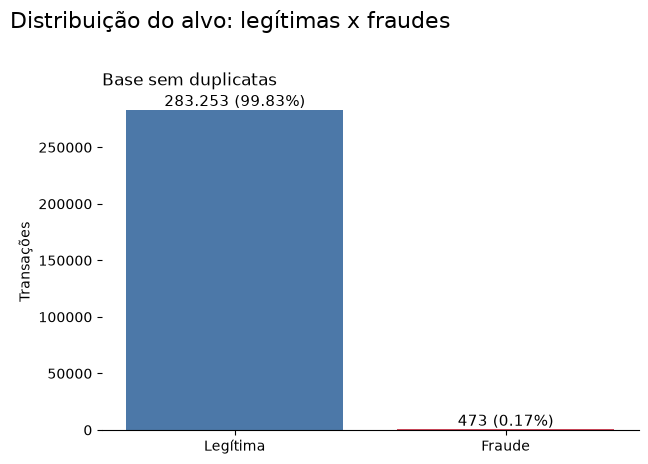

In [12]:
plot_distribuicao_alvo([df['Target']], ['Base sem duplicatas'], 'Distribuição do alvo: legítimas x fraudes',
                       'Distribuicao do alvo')

📌 **Nota**
- 🔎 Só **473 de 283.726** transações são fraudes (**0,17%**): para cada fraude, há cerca de **600** legítimas.
- ⚠️ Um "modelo" que diz sempre "não é fraude" acerta **99,83%**. A versão original destacava acurácias de 99,9% como bom resultado, mas elas não dizem nada aqui.
- ✅ **Decisão:** separação estratificada, **PR-AUC** como métrica principal e tratamento do desbalanceamento no treino (item 4.2 da Fase 03).

### 🛡️ Remoção de variáveis com vazamento (*data leakage*)

Vazamento é usar, no treino, uma informação que **não estaria disponível** no momento da previsão (ou que "entrega" a resposta). Conferimos as três situações possíveis nesta base:

| Situação | Risco | Decisão |
|---|---|---|
| Alguma coluna é calculada a partir do alvo? | As componentes PCA vieram prontas do banco | Nenhuma coluna tem correlação perfeita com o alvo (maior Spearman, H4). Mantidas |
| `Timestamp` (segundos desde a 1ª transação) | É a **posição na janela de coleta** de 48 h: uma transação de amanhã teria um valor que o modelo nunca viu | **Removido**. No lugar entra a **hora do dia** (0 a 24 h), um padrão que se repete |
| **Duplicatas** | A mesma transação no treino e no teste é "cola": o modelo é avaliado em algo que já viu | **Removidas** antes da separação (item 2.3) |

O item 9 da Fase 03 (teste anti-vazamento) mostra o tamanho do problema que a versão original tinha.

## 3 - ANÁLISE EXPLORATÓRIA DOS DADOS

Nas componentes PCA não há "significado de negócio" a explorar, mas há perguntas importantes: o **valor** e o **horário** das fraudes são diferentes? As componentes separam bem as classes?

### 3.1. Criação das Hipóteses

| # | Hipótese | Tipo |
|---|---|---|
| H1 | As fraudes têm valor **menor** que as transações legítimas | Individual |
| H2 | A fraude é mais comum **de madrugada** (0 h a 6 h) | Individual |
| H3 | Transações de **valor zero** são suspeitas (testes de cartão/conta) | Individual |
| H4 | Algumas componentes PCA **separam fortemente** fraudes de legítimas | Combinada |
| H5 | As componentes PCA **não se correlacionam** entre si (não há multicolinearidade) | Combinada |
| H6 | A taxa de fraude é a mesma nos **dois dias** da base | Combinada |

> 💡 Em todos os testes, **o que importa é o tamanho do efeito, não o p**: com 283 mil linhas, quase tudo dá "significativo".

### 3.2. Hipóteses Individuais (colunas isoladas)

#### H1 – As fraudes têm valor menor

,count,mean,std,min,25%,50%,75%,max
Target,,,,,,,,
Legítima,283253.0,88.41,250.38,0.0,5.67,22.00,77.46,25691.16
Fraude,473.0,123.87,260.21,0.0,1.00,9.82,105.89,2125.87


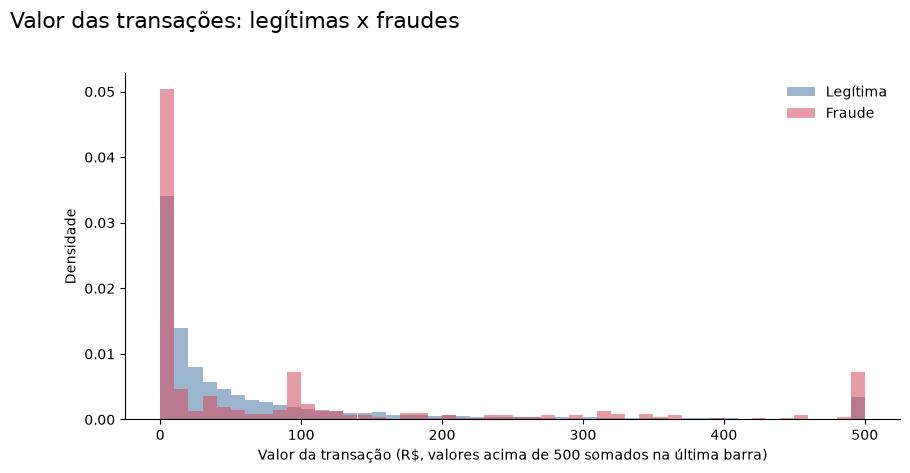

In [13]:
fraude = df['Target'] == 1
display(df.groupby('Target')[COLUNA_VALOR].describe().rename(index={0: 'Legítima', 1: 'Fraude'}).round(2))

fig, ax = plt.subplots(figsize=(10, 4.5))
limite = 500
for classe, cor, rotulo in [(0, COR_LEGITIMA, 'Legítima'), (1, COR_FRAUDE, 'Fraude')]:
    valores = df.loc[df['Target'] == classe, COLUNA_VALOR]
    ax.hist(valores.clip(upper=limite), bins=50, density=True, alpha=0.55, color=cor, label=rotulo)
ax.set(xlabel=f'Valor da transação (R$, valores acima de {limite} somados na última barra)', ylabel='Densidade')
ax.legend(frameon=False)
sns.despine()
titulo('Valor das transações: legítimas x fraudes')
salvar('Valor fraude x legitima')
plt.show()

**Teste.** Mann-Whitney entre os valores das fraudes e das legítimas, com a correlação de postos como tamanho de efeito.

In [14]:
pd.Series(teste_mann_whitney(df.loc[fraude, COLUNA_VALOR], df.loc[~fraude, COLUNA_VALOR])).to_frame('H1').T

,teste,estatística,p-valor,efeito,tamanho do efeito
H1,Mann-Whitney,59517129.5,0.000027,correlação de postos,-0.111543


✅ **Verdadeira, com efeito pequeno.** A mediana das fraudes é de **R$ 9,82**, contra **R$ 22,00** das legítimas, e 25% das fraudes valem até **R$ 1,00**.
- ⚠️ Mas a **média** das fraudes é maior (**R$ 123,87** x R$ 88,41): há muitas fraudes pequenas e algumas grandes (até R$ 2.125,87).
- ⚠️ A versão original dizia que "a média das fraudes é −5" olhando a coluna `valor`, que é a componente V10, e não o valor da transação.

🧪 **Teste estatístico:** Mann-Whitney com p < 0,001 e correlação de postos de **−0,11** (efeito pequeno): sozinho, o valor separa pouco as fraudes. O que importa é o tamanho do efeito, não o p.

#### H2 – A fraude é mais comum de madrugada

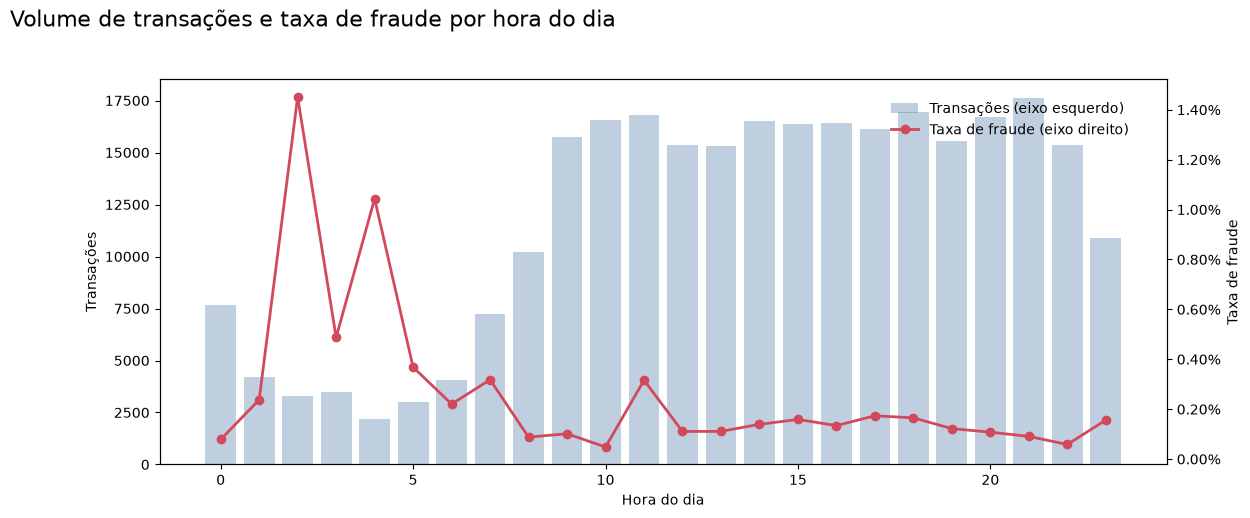

Madrugada (0 h a 6 h): 8.4% das transações | taxa de fraude 0.482%
Resto do dia:          91.6% das transações | taxa de fraude 0.138%


In [15]:
df['hora_do_dia'] = hora_do_dia(df['Timestamp'])
por_hora = df.groupby(df['hora_do_dia'].astype(int))['Target'].agg(transacoes='size', fraudes='sum', taxa='mean')

fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.bar(por_hora.index, por_hora['transacoes'], color=COR_LEGITIMA, alpha=0.35, label='Transações (eixo esquerdo)')
ax1.set_xlabel('Hora do dia')
ax1.set_ylabel('Transações')
ax2 = ax1.twinx()
ax2.plot(por_hora.index, por_hora['taxa'], color=COR_FRAUDE, marker='o', lw=2, label='Taxa de fraude (eixo direito)')
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=2))
ax2.set_ylabel('Taxa de fraude')
fig.legend(loc='upper right', bbox_to_anchor=(0.88, 0.86), frameon=False)
titulo('Volume de transações e taxa de fraude por hora do dia')
salvar('Fraude por hora')
plt.show()

madrugada = df['hora_do_dia'] < 6
print(f'Madrugada (0 h a 6 h): {madrugada.mean():.1%} das transações | taxa de fraude {df.loc[madrugada, "Target"].mean():.3%}')
print(f'Resto do dia:          {(~madrugada).mean():.1%} das transações | taxa de fraude {df.loc[~madrugada, "Target"].mean():.3%}')

**Teste.** Qui-quadrado entre "madrugada" e "fraude", com o V de Cramér e o *odds ratio* (quantas vezes a chance de fraude é maior de madrugada).

In [16]:
resultado_h2 = teste_qui_quadrado(madrugada, df['Target'])
resultado_h2['odds ratio'] = odds_ratio(madrugada, df['Target'])
pd.Series(resultado_h2).to_frame('H2').T

,teste,estatística,gl,p-valor,efeito,tamanho do efeito,odds ratio
H2,Qui-quadrado,153.743378,1,0.0,V de Cramér,0.023202,3.513604


✅ **Verdadeira.** A madrugada (0 h a 6 h) tem só **8,4%** das transações, mas a taxa de fraude ali é de **0,482%**, contra **0,138%** no resto do dia: a chance de fraude é **3,5 vezes** maior. O pico é às **2 h** (1,45%).
- 🔎 O gráfico confirma a premissa da hora do dia: o volume despenca entre 1 h e 6 h, como numa madrugada.
- ✅ **Decisão:** criar a variável `hora_do_dia`.

🧪 **Teste estatístico:** qui-quadrado com p < 0,001, V de Cramér de **0,023** (baixo, porque a fraude é rara) e *odds ratio* de **3,51**. O que importa é o tamanho do efeito, não o p.

#### H3 – Transações de valor zero são suspeitas

In [17]:
valor_zero = df[COLUNA_VALOR] == 0
resultado_h3 = teste_qui_quadrado(valor_zero, df['Target'])
resultado_h3['odds ratio'] = odds_ratio(valor_zero, df['Target'])
print(f'Transações de valor zero: {valor_zero.sum():,} | taxa de fraude {df.loc[valor_zero, "Target"].mean():.2%}'.replace(',', '.'))
print(f'Demais transações:        taxa de fraude {df.loc[~valor_zero, "Target"].mean():.2%}')
print(f'Fraudes de valor zero: {df.loc[valor_zero, "Target"].sum()} de {df["Target"].sum()}')
pd.Series(resultado_h3).to_frame('H3').T

Transações de valor zero: 1.808 | taxa de fraude 1.38%
Demais transações:        taxa de fraude 0.16%
Fraudes de valor zero: 25 de 473


,teste,estatística,gl,p-valor,efeito,tamanho do efeito,odds ratio
H3,Qui-quadrado,154.399837,1,0.0,V de Cramér,0.023252,8.809328


✅ **Verdadeira.** Das **1.808** transações de valor zero, **1,38%** são fraudes, contra **0,16%** nas demais: a chance é **8,8 vezes** maior. São **25 das 473** fraudes.
- 💡 Uma transação de R$ 0 pode ser um teste para saber se a conta ou o cartão funciona antes do golpe.

🧪 **Teste estatístico:** qui-quadrado com p < 0,001, V de Cramér de **0,023** e *odds ratio* de **8,81**. O que importa é o tamanho do efeito, não o p.

### 3.3. Hipóteses Combinadas (entre colunas)

#### H4 – Algumas componentes PCA separam fortemente as fraudes

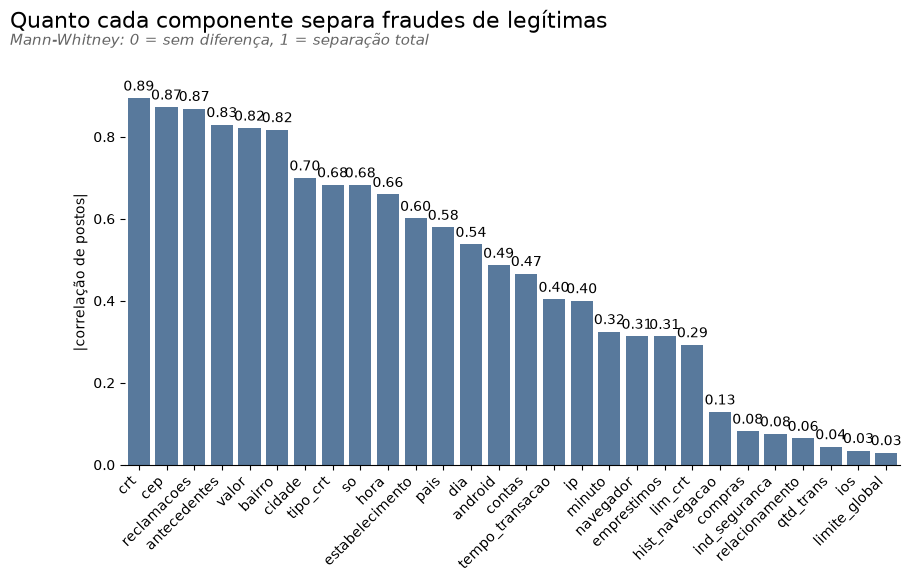

Componentes com efeito grande (|r| > 0,5): 13 de 28
Componentes com efeito desprezível (|r| < 0,1): 6


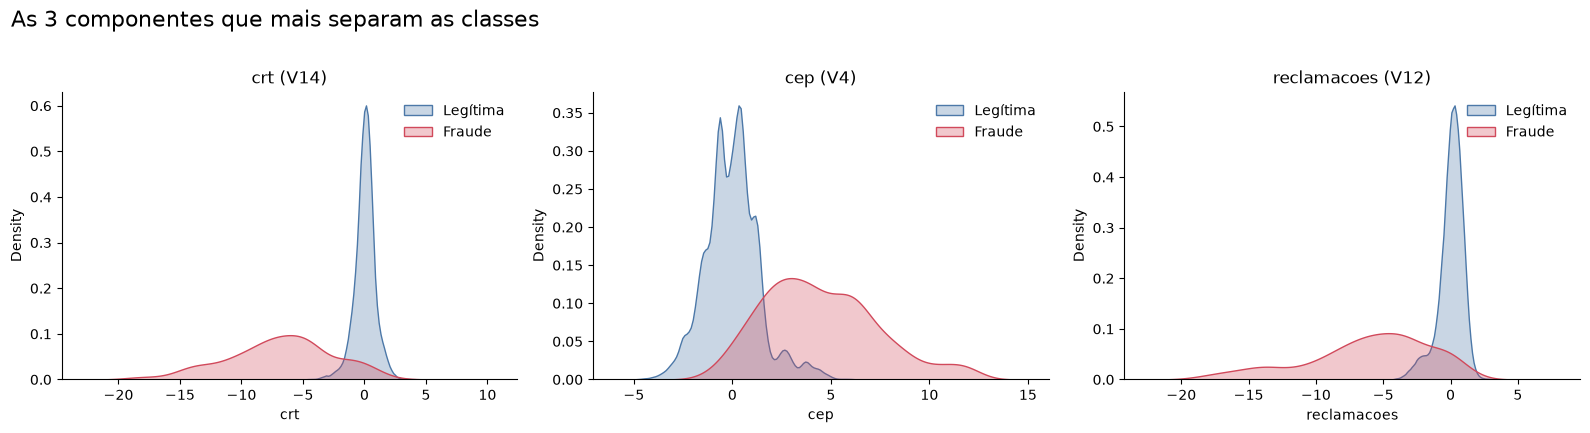

In [18]:
separacao = pd.DataFrame({coluna: teste_mann_whitney(df.loc[fraude, coluna], df.loc[~fraude, coluna])
                          for coluna in COMPONENTES_PCA}).T
separacao['tamanho do efeito'] = separacao['tamanho do efeito'].astype(float)
separacao = separacao.reindex(separacao['tamanho do efeito'].abs().sort_values(ascending=False).index)

plot_barras(separacao['tamanho do efeito'].abs(), 'Quanto cada componente separa fraudes de legítimas',
            'Separacao das componentes', ylabel='|correlação de postos|', formato='{:.2f}',
            subtitulo='Mann-Whitney: 0 = sem diferença, 1 = separação total')
print(f"Componentes com efeito grande (|r| > 0,5): {(separacao['tamanho do efeito'].abs() > 0.5).sum()} de {len(separacao)}")
print(f"Componentes com efeito desprezível (|r| < 0,1): {(separacao['tamanho do efeito'].abs() < 0.1).sum()}")

top3 = separacao.index[:3]
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, coluna in zip(axs, top3):
    for classe, cor, rotulo in [(0, COR_LEGITIMA, 'Legítima'), (1, COR_FRAUDE, 'Fraude')]:
        sns.kdeplot(df.loc[df['Target'] == classe, coluna], ax=ax, color=cor, fill=True, alpha=0.3, label=rotulo,
                    common_norm=False, clip=(-30, 15))
    ax.set_title(f'{coluna} ({COLUNAS_ORIGINAIS[coluna]})')
    ax.legend(frameon=False)
    sns.despine(ax=ax)
titulo('As 3 componentes que mais separam as classes')
plt.tight_layout()
salvar('Top 3 componentes')
plt.show()

✅ **Verdadeira.** **13 das 28** componentes separam as fraudes com efeito grande (correlação de postos acima de 0,5 em módulo). As maiores são `crt` (V14, **−0,89**), `cep` (V4, **0,87**) e `reclamacoes` (V12, **−0,87**); só **6** têm efeito desprezível.
- 💡 É isso que permite encontrar fraudes mesmo com 0,17% de casos: nas melhores componentes, as distribuições das duas classes quase não se sobrepõem.

🧪 **Teste estatístico:** Mann-Whitney em cada componente, com efeito de até **0,89** em módulo. O que importa é o tamanho do efeito, não o p.

#### H5 – As componentes PCA não se correlacionam entre si

In [19]:
correlacao_pca = df[COMPONENTES_PCA].corr()
pares = correlacao_pca.where(np.triu(np.ones(correlacao_pca.shape, dtype=bool), k=1)).stack()
print(f'Maior correlação (em módulo) entre duas componentes: {pares.abs().max():.3f} ({pares.abs().idxmax()[0]} x {pares.abs().idxmax()[1]})')
print(f'Correlação do valor da transação com as componentes: de {df[COMPONENTES_PCA].corrwith(df[COLUNA_VALOR]).min():.2f} '
      f'a {df[COMPONENTES_PCA].corrwith(df[COLUNA_VALOR]).max():.2f}')

Maior correlação (em módulo) entre duas componentes: 0.019 (minuto x android)


Correlação do valor da transação com as componentes: de -0.53 a 0.40


**Teste.** Spearman entre as duas componentes mais correlacionadas (o "pior caso").

In [20]:
a, b = pares.abs().idxmax()
pd.Series(teste_spearman(df[a], df[b])).to_frame('H5').T

,teste,estatística,p-valor,efeito,tamanho do efeito
H5,Spearman,0.076375,0.0,rho,0.076375


✅ **Verdadeira.** A maior correlação entre duas componentes é de **0,019** (`minuto` x `android`): o PCA cria componentes sem correlação por construção. Já o valor da transação, que não passou pelo PCA, tem correlação de **−0,53 a 0,40** com elas.
- ⚠️ A versão original sugeria remover variáveis por multicolinearidade; nesta base, esse problema não existe.

🧪 **Teste estatístico:** Spearman de **0,076** no par mais correlacionado (efeito desprezível). O que importa é o tamanho do efeito, não o p.

#### H6 – A taxa de fraude é a mesma nos dois dias

In [21]:
segundo_dia = df['Timestamp'] >= 24 * 3600
print(f'Dia 1: {(~segundo_dia).sum():,} transações | taxa de fraude {df.loc[~segundo_dia, "Target"].mean():.3%}'.replace(',', '.'))
print(f'Dia 2: {segundo_dia.sum():,} transações | taxa de fraude {df.loc[segundo_dia, "Target"].mean():.3%}'.replace(',', '.'))
resultado_h6 = teste_qui_quadrado(segundo_dia, df['Target'])
resultado_h6['odds ratio'] = odds_ratio(segundo_dia, df['Target'])
pd.Series(resultado_h6).to_frame('H6').T

Dia 1: 144.236 transações | taxa de fraude 0.189%
Dia 2: 139.490 transações | taxa de fraude 0.144%


,teste,estatística,gl,p-valor,efeito,tamanho do efeito,odds ratio
H6,Qui-quadrado,8.165814,1,0.004269,V de Cramér,0.005026,0.763773


⚠️ **Quase.** A taxa de fraude é de **0,189%** no dia 1 e de **0,144%** no dia 2 (*odds ratio* de **0,76**).
- 💡 A diferença é pequena, mas mostra que a posição na janela de coleta não é um padrão estável: com só dois dias, não há como aprender um "efeito do dia".
- ✅ **Decisão:** remover o `Timestamp` cru e manter só a hora do dia.

🧪 **Teste estatístico:** qui-quadrado com p = 0,004 e V de Cramér de **0,005** (efeito desprezível). O que importa é o tamanho do efeito, não o p.

### 3.4. Resumo das Hipóteses

| # | Hipótese | Resultado | Evidência |
|---|---|---|---|
| H1 | As fraudes têm valor menor | ✅ Verdadeira (efeito pequeno) | Mediana de R$ 9,82 x R$ 22,00; correlação de postos de −0,11 |
| H2 | A fraude é mais comum de madrugada | ✅ Verdadeira | Taxa de 0,482% x 0,138%; *odds ratio* de 3,51 |
| H3 | Transações de valor zero são suspeitas | ✅ Verdadeira | Taxa de 1,38% x 0,16%; *odds ratio* de 8,81 |
| H4 | Algumas componentes separam fortemente | ✅ Verdadeira | 13 de 28 com efeito grande; `crt` com −0,89 |
| H5 | As componentes não se correlacionam | ✅ Verdadeira | Correlação máxima de 0,019 |
| H6 | A taxa de fraude é a mesma nos dois dias | ⚠️ Quase | 0,189% x 0,144%; V de Cramér de 0,005 |

## 4 - FEATURE ENGINEERING — (engenharia de atributos)

| Variável | Fórmula | Por quê |
|---|---|---|
| **hora_do_dia** | (segundos desde a 1ª transação módulo 86.400) ÷ 3.600 | Captura o padrão da madrugada (H2) e, ao contrário do `Timestamp`, se repete em qualquer dia |
| `Timestamp` | removida | É a posição na janela de coleta de 48 h, não um padrão (H6) |

As componentes PCA e o valor ficam como estão: os modelos de árvore não precisam de escala, e a Regressão Logística recebe uma padronização **dentro do Pipeline** (ajustada só no treino).

In [22]:
X, y = preparar_variaveis(df.drop(columns=['hora_do_dia']))
print(f'X: {X.shape} | y: {y.shape} | % de fraudes: {y.mean():.3%}')
X[['hora_do_dia', COLUNA_VALOR]].describe().round(2).T

X: (283726, 30) | y: (283726,) | % de fraudes: 0.167%


,count,mean,std,min,25%,50%,75%,max
hora_do_dia,283726.0,14.54,5.85,0.0,10.6,15.01,19.33,24.00
hist_saldo,283726.0,88.47,250.40,0.0,5.6,22.00,77.51,25691.16


## 5 - EXPLORANDO AS CORRELAÇÕES

Correlação de Spearman de cada variável com o alvo (fraude = 1).

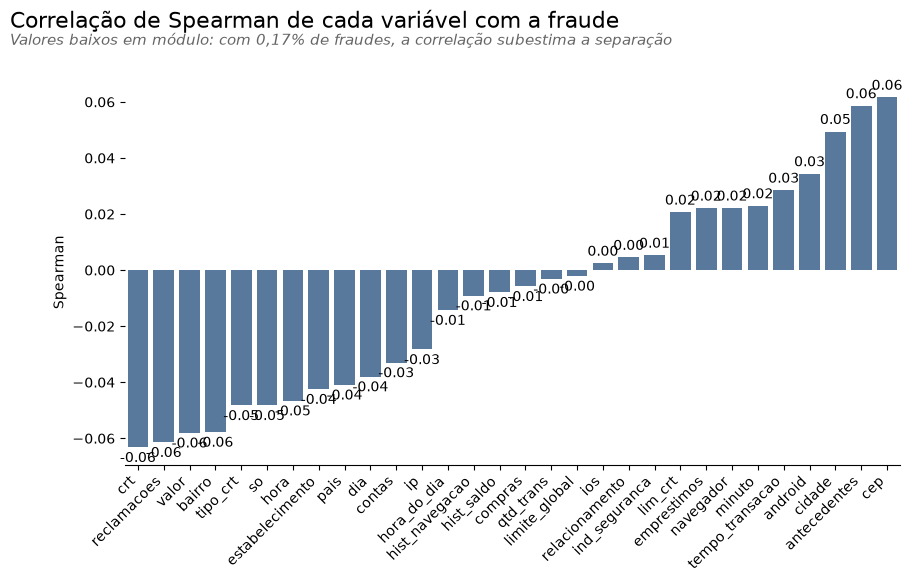

In [23]:
correlacao_alvo = X.corrwith(y, method='spearman').sort_values()
plot_barras(correlacao_alvo, 'Correlação de Spearman de cada variável com a fraude', 'Correlacao com o alvo',
            ylabel='Spearman', formato='{:.2f}', subtitulo='Valores baixos em módulo: com 0,17% de fraudes, a correlação subestima a separação')

📌 **Nota**
- 🔎 Nenhuma variável passa de **0,06** em módulo na correlação de Spearman com a fraude (`cep` com 0,06 e `crt` com −0,06).
- 💡 Isso não contradiz a H4: com 0,17% de fraudes, a correlação fica baixa mesmo quando a separação é grande, porque quase todas as linhas são da mesma classe. Para classes raras, a correlação de postos de Mann-Whitney (H4) e a informação mútua (item 4.3 da Fase 03) são mais adequadas.

# FASE 03: MODELAGEM DOS DADOS

## 1 - Leitura dos dados

In [24]:
print(f'X: {X.shape} | y: {y.shape} | fraudes: {y.sum()} ({y.mean():.3%})')

X: (283726, 30) | y: (283726,) | fraudes: 473 (0.167%)


## 2 - Valores nulos

In [25]:
print(f'Nulos em X: {X.isnull().sum().sum()} | nulos em y: {y.isnull().sum()}')

Nulos em X: 0 | nulos em y: 0


## 3 - Transformação

| Modelo | Transformação |
|---|---|
| Regressão Logística | `StandardScaler` (média 0, desvio 1) **dentro do Pipeline**: ajustado só nos dados de treino de cada etapa |
| XGBoost, LightGBM e Random Forest | Nenhuma: árvores não dependem da escala |

O desbalanceamento é tratado no próprio modelo (item 4.2), também dentro do Pipeline.

In [26]:
def pipeline_logistica(**parametros):
    return Pipeline([('escala', StandardScaler()), ('modelo', LogisticRegression(max_iter=3000, **parametros))])

## 4 - Pré-Processamento

### 4.1. Separação do conjunto de dados

In [27]:
# 1ª divisão: 20% para o teste (aberto uma única vez, na Fase 04)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMENTE, stratify=y)
# 2ª divisão: do restante (80%), 75% treino e 25% validação -> 60% / 20% / 20%
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=SEMENTE, stratify=y_temp)

pd.DataFrame({
    'Transações': [len(X), len(X_train), len(X_val), len(X_test)],
    '% da base': [1, len(X_train) / len(X), len(X_val) / len(X), len(X_test) / len(X)],
    'Fraudes': [y.sum(), y_train.sum(), y_val.sum(), y_test.sum()],
    '% de fraudes': [y.mean(), y_train.mean(), y_val.mean(), y_test.mean()],
}, index=['Total', 'Treino', 'Validação', 'Teste']).style.format({'Transações': '{:,}', '% da base': '{:.0%}', '% de fraudes': '{:.3%}'})

,Transações,% da base,Fraudes,% de fraudes
Total,"283,726",100%,473,0.167%
Treino,"170,235",60%,284,0.167%
Validação,"56,745",20%,94,0.166%
Teste,"56,746",20%,95,0.167%


📌 **Nota**
- 🔎 Treino com **170.235** transações (284 fraudes), validação com **56.745** (94) e teste com **56.746** (95), todos com **0,17%** de fraudes, graças à estratificação.
- ⚠️ A versão original estratificava só a primeira divisão; a validação podia ficar com uma proporção diferente de fraudes.
- 💡 Com só **94 fraudes** na validação, cada fraude vale cerca de 1 ponto de recall. Por isso, a validação cruzada decide o modelo (item 5).

### 4.2. Balancear os dados

Com 0,17% de fraudes, um modelo pode "aprender" que prever sempre "legítima" já é ótimo. Há duas formas de evitar isso:

| Estratégia | Como funciona |
|---|---|
| **SMOTE** | Cria fraudes sintéticas no treino, interpolando entre fraudes vizinhas, até as classes ficarem 50/50 |
| **Peso da classe** | Não cria dados: faz cada erro numa fraude "custar" mais no treino (`class_weight='balanced'` ou `scale_pos_weight`) |

Comparamos as duas (e nenhuma) em três algoritmos, **na validação, que nunca é balanceada**. O SMOTE fica dentro de um Pipeline do `imblearn`, então só é aplicado ao treino.

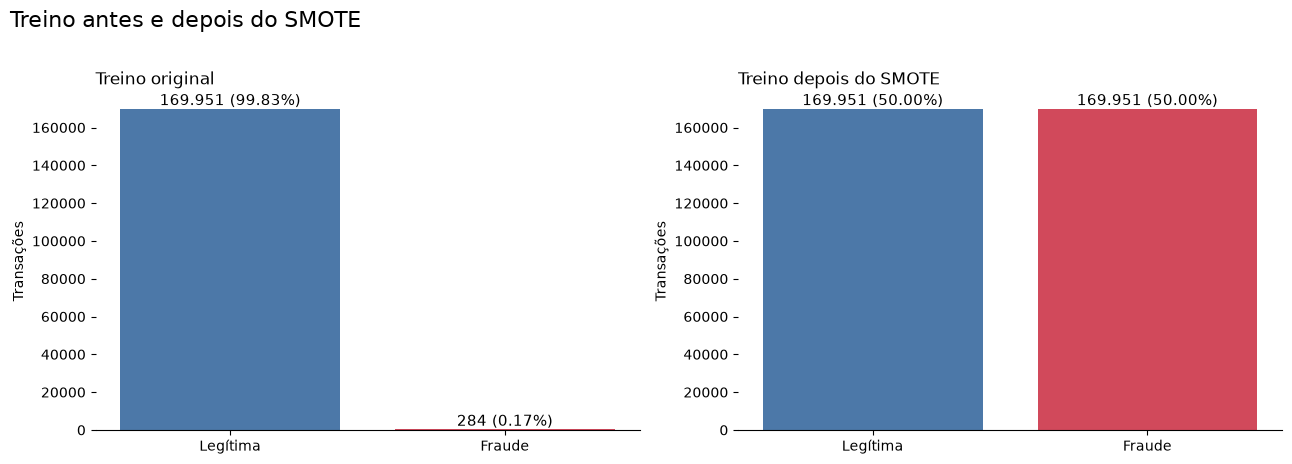

,Peso da classe,SMOTE,Sem balanceamento
LightGBM,0.855,0.853,0.092
Regressão Logística,0.788,0.788,0.800
XGBoost,0.891,0.893,0.711


In [28]:
proporcao = (y_train == 0).sum() / y_train.sum()   # legítimas por fraude no treino
_, y_smote = SMOTE(random_state=SEMENTE).fit_resample(X_train, y_train)
plot_distribuicao_alvo([y_train, pd.Series(y_smote)], ['Treino original', 'Treino depois do SMOTE'],
                       'Treino antes e depois do SMOTE', 'Treino antes e depois do SMOTE')

estrategias = {
    'Regressão Logística': {'Sem balanceamento': pipeline_logistica(),
                            'Peso da classe': pipeline_logistica(class_weight='balanced'),
                            'SMOTE': PipelineImb([('escala', StandardScaler()), ('smote', SMOTE(random_state=SEMENTE)),
                                                  ('modelo', LogisticRegression(max_iter=3000))])},
    'XGBoost': {'Sem balanceamento': xgb.XGBClassifier(random_state=SEMENTE, n_jobs=N_JOBS),
                'Peso da classe': xgb.XGBClassifier(random_state=SEMENTE, n_jobs=N_JOBS, scale_pos_weight=proporcao),
                'SMOTE': PipelineImb([('smote', SMOTE(random_state=SEMENTE)),
                                      ('modelo', xgb.XGBClassifier(random_state=SEMENTE, n_jobs=N_JOBS))])},
    'LightGBM': {'Sem balanceamento': lgb.LGBMClassifier(random_state=SEMENTE, verbose=-1),
                 'Peso da classe': lgb.LGBMClassifier(random_state=SEMENTE, verbose=-1, class_weight='balanced'),
                 'SMOTE': PipelineImb([('smote', SMOTE(random_state=SEMENTE)),
                                       ('modelo', lgb.LGBMClassifier(random_state=SEMENTE, verbose=-1))])},
}
comparacao_balanceamento = {}
for algoritmo, opcoes in estrategias.items():
    for estrategia, modelo in opcoes.items():
        t0 = time.time()
        proba = modelo.fit(X_train, y_train).predict_proba(X_val)[:, 1]
        comparacao_balanceamento[(algoritmo, estrategia)] = {'PR-AUC (validação)': average_precision_score(y_val, proba),
                                                            'Tempo de treino (s)': time.time() - t0}
comparacao_balanceamento = pd.DataFrame(comparacao_balanceamento).T
del estrategias, y_smote   # libera os modelos de teste e o treino sintético do SMOTE
_ = gc.collect()
comparacao_balanceamento['PR-AUC (validação)'].unstack().round(3)

📌 **Nota: peso da classe x SMOTE**
- 🔎 Sem balanceamento, o LightGBM falha (PR-AUC de **0,092**) e o XGBoost cai para **0,711**.
- 🔎 Peso da classe e SMOTE empatam: XGBoost com **0,891** x **0,893**, LightGBM com **0,855** x **0,853** e Regressão Logística com **0,788** nos dois (0,800 sem balanceamento).
- ⚠️ A versão original criava um treino 50/50 com SMOTE (o gráfico mostrava isso), mas treinava os modelos com o treino original: o balanceamento nunca foi usado.
- ✅ **Decisão:** usar o **peso da classe**. O resultado é o mesmo, sem criar cerca de 170 mil fraudes sintéticas e com treino mais rápido.

### 4.3. Seleção de Variáveis

Dois métodos, ajustados **só no treino**:

| Método | O que mede |
|---|---|
| **Importância do Random Forest** | Quanto cada variável ajudou as árvores a separar fraudes de legítimas |
| **Informação Mútua** (`SelectKBest` + `mutual_info_classif`) | Quanto saber o valor da variável reduz a incerteza sobre o alvo, inclusive em relações não lineares |

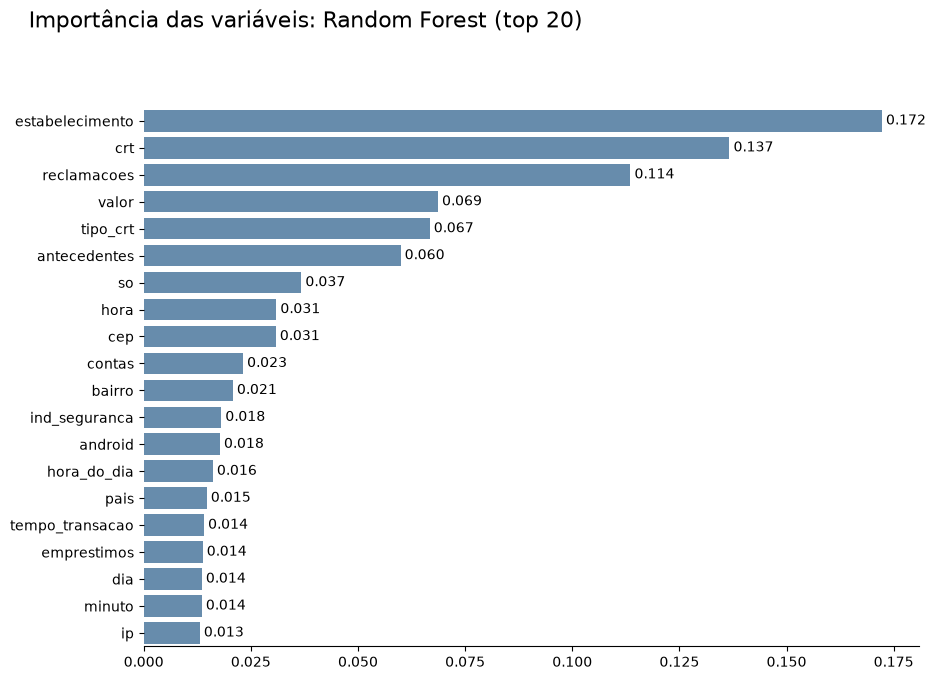

Random Forest ajustado em 203s


In [29]:
t0 = time.time()
importancias = importancia_random_forest(X_train, y_train, X_train.columns, semente=SEMENTE, n_jobs=N_JOBS)
plot_barras(importancias.head(20), 'Importância das variáveis: Random Forest (top 20)', 'Importancia RF (selecao)',
            horizontal=True, cor='#5B8DB8', formato='{:.3f}')
print(f'Random Forest ajustado em {time.time() - t0:.0f}s')

Informação mútua calculada em 87s
Variáveis com informação mútua praticamente nula (< 0,0005): 6 de 30


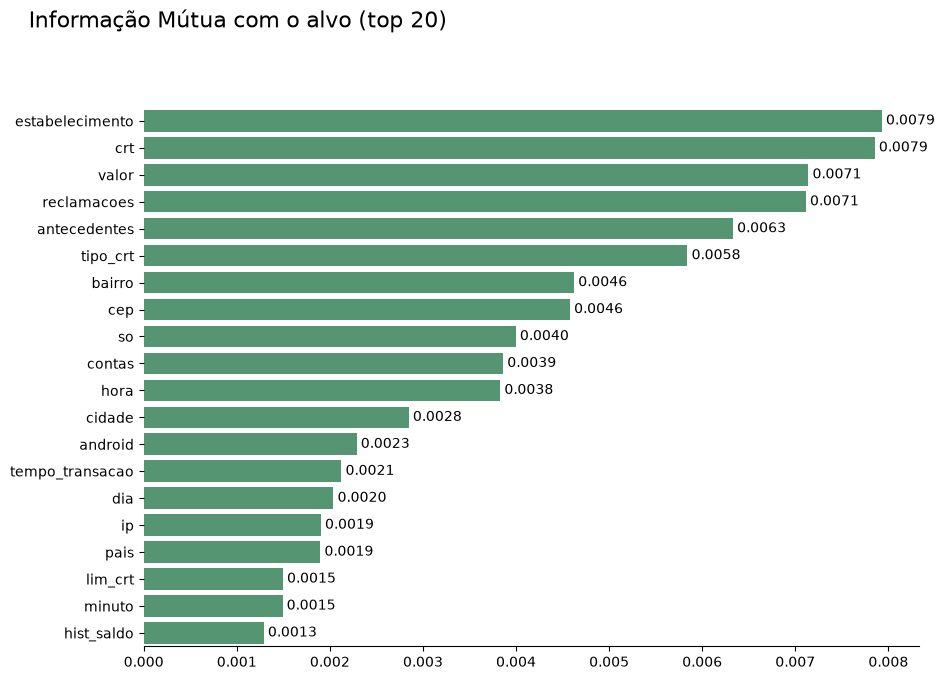

,Random Forest,Informação Mútua
1,estabelecimento,estabelecimento
2,crt,crt
3,reclamacoes,valor
4,valor,reclamacoes
5,tipo_crt,antecedentes
6,antecedentes,tipo_crt
7,so,bairro
8,hora,cep
9,cep,so
10,contas,contas


In [30]:
t0 = time.time()
ranking_mi, seletor = selecao_features(X_train, y_train, X_train.columns, k=10, semente=SEMENTE)
print(f'Informação mútua calculada em {time.time() - t0:.0f}s')
print(f"Variáveis com informação mútua praticamente nula (< 0,0005): {(ranking_mi['score'] < 0.0005).sum()} de {len(ranking_mi)}")
plot_barras(ranking_mi.set_index('feature')['score'].head(20), 'Informação Mútua com o alvo (top 20)',
            'Informacao mutua (selecao)', horizontal=True, cor='#4C9F70', formato='{:.4f}')

pd.DataFrame({'Random Forest': importancias.head(10).index, 'Informação Mútua': ranking_mi['feature'].head(10).values},
             index=range(1, 11))

**Vale a pena usar só as melhores variáveis?** Comparamos o XGBoost (com peso da classe) com todas as 30 variáveis e com as 10 melhores pela informação mútua, na validação.

In [31]:
top10 = ranking_mi['feature'].head(10).tolist()
modelo_todas = xgb.XGBClassifier(random_state=SEMENTE, n_jobs=N_JOBS, scale_pos_weight=proporcao).fit(X_train, y_train)
modelo_top10 = xgb.XGBClassifier(random_state=SEMENTE, n_jobs=N_JOBS, scale_pos_weight=proporcao).fit(X_train[top10], y_train)
print(f"PR-AUC com as 30 variáveis: {average_precision_score(y_val, modelo_todas.predict_proba(X_val)[:, 1]):.3f}")
print(f"PR-AUC com as 10 melhores:  {average_precision_score(y_val, modelo_top10.predict_proba(X_val[top10])[:, 1]):.3f}")
del modelo_todas, modelo_top10
_ = gc.collect()

PR-AUC com as 30 variáveis: 0.891


PR-AUC com as 10 melhores:  0.833


📌 **Nota**
- 🔎 Os dois métodos concordam: `estabelecimento` (V17) e `crt` (V14) ficam em 1º e 2º nos dois, e **9 das 10** primeiras se repetem.
- 🔎 **6** variáveis têm informação mútua praticamente nula.
- 🔎 Mas usar só as 10 melhores **piora** o XGBoost: a PR-AUC cai de **0,891** para **0,833**. As variáveis "fracas" sozinhas ajudam em combinação.
- ⚠️ A versão original usava `mutual_info_regression` (para alvos numéricos) num problema de classificação. ✅ Na v2, `mutual_info_classif`, com semente fixa.
- ✅ **Decisão:** manter as 30 variáveis.

## 5 - Treinamento dos Algoritmos de Machine Learning

Todos com **peso da classe** (item 4.2), treinados no treino e avaliados na validação. Em cada um: amostra gabarito x previsão, métricas, **treino x validação** (sobreajuste), relatório de classificação e matriz de confusão, com o limiar padrão de 0,5 (o limiar é escolhido no item 8).

In [32]:
modelos = {
    'XGBoost': xgb.XGBClassifier(random_state=SEMENTE, n_jobs=N_JOBS, scale_pos_weight=proporcao),
    'Random Forest': RandomForestClassifier(random_state=SEMENTE, n_jobs=N_JOBS, class_weight='balanced'),
    'LightGBM': lgb.LGBMClassifier(random_state=SEMENTE, verbose=-1, class_weight='balanced'),
    'Regressão Logística': pipeline_logistica(class_weight='balanced'),
}
metricas_validacao, probas_validacao = {}, {}

### XGBoost

XGBoost treinado em 8s



AMOSTRA: GABARITO x PROBABILIDADE x PREVISÃO (limiar = 0.50)


,Gabarito,Probabilidade,Previsão da máquina
0,0,0.0,0
1,0,0.0,0
2,0,0.0,0
3,0,0.0,0
4,0,0.0,0
5,0,0.0,0
6,0,0.0,0
7,0,0.0,0


MÉTRICAS DE VALIDAÇÃO: XGBoost
Acurácia                 0.9996
Precisão                 0.9302
Recall (Sensibilidade)   0.8511
F1-Score                 0.8889
AUC-ROC                  0.9769
PR-AUC                   0.8913
                         (sorteio: PR-AUC = 0.0017, AUC-ROC = 0,50)



SOBREAJUSTE (treino x validação):
  PR-AUC : treino 1.0000 | validação 0.8913 | diferença +0.1087
  AUC-ROC: treino 1.0000 | validação 0.9769 | diferença +0.0231

              precision    recall  f1-score   support

Legítima (0)     0.9998    0.9999    0.9998     56651
  Fraude (1)     0.9302    0.8511    0.8889        94

    accuracy                         0.9996     56745
   macro avg     0.9650    0.9255    0.9444     56745
weighted avg     0.9996    0.9996    0.9996     56745



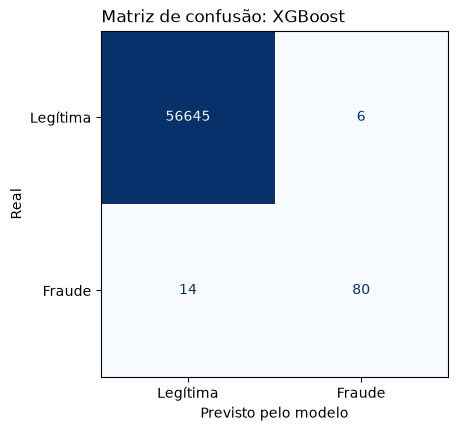

In [33]:
t0 = time.time()
modelos['XGBoost'].fit(X_train, y_train)
print(f'XGBoost treinado em {time.time() - t0:.0f}s\n')
metricas_validacao['XGBoost'], probas_validacao['XGBoost'] = relatorio_validacao(
    'XGBoost', modelos['XGBoost'], X_train, y_train, X_val, y_val, nome_arquivo='Matriz XGBoost')

📌 **Nota: XGBoost**
- 🔎 Na validação, encontrou **80 das 94** fraudes (recall de **0,851**) com só **6** alarmes falsos (precisão de **0,930**); F1 de **0,889** e PR-AUC de **0,891**.
- 🔎 **Sobreajuste:** PR-AUC de **1,000** no treino contra **0,891** na validação. Modelos de árvore "decoram" o treino; o que vale é o desempenho em dados novos, que a validação cruzada confirma.
- 🔎 Matriz de confusão: das 94 fraudes, **14** passaram como legítimas; das 56.651 legítimas, só 6 foram marcadas.

### Random Forest

Random Forest treinado em 74s



AMOSTRA: GABARITO x PROBABILIDADE x PREVISÃO (limiar = 0.50)


,Gabarito,Probabilidade,Previsão da máquina
0,0,0.0,0
1,0,0.0,0
2,0,0.0,0
3,0,0.0,0
4,0,0.0,0
5,0,0.0,0
6,0,0.0,0
7,0,0.0,0


MÉTRICAS DE VALIDAÇÃO: Random Forest
Acurácia                 0.9996
Precisão                 0.9186
Recall (Sensibilidade)   0.8404
F1-Score                 0.8778
AUC-ROC                  0.9557
PR-AUC                   0.8770
                         (sorteio: PR-AUC = 0.0017, AUC-ROC = 0,50)



SOBREAJUSTE (treino x validação):
  PR-AUC : treino 1.0000 | validação 0.8770 | diferença +0.1230
  AUC-ROC: treino 1.0000 | validação 0.9557 | diferença +0.0443

              precision    recall  f1-score   support

Legítima (0)     0.9997    0.9999    0.9998     56651
  Fraude (1)     0.9186    0.8404    0.8778        94

    accuracy                         0.9996     56745
   macro avg     0.9592    0.9202    0.9388     56745
weighted avg     0.9996    0.9996    0.9996     56745



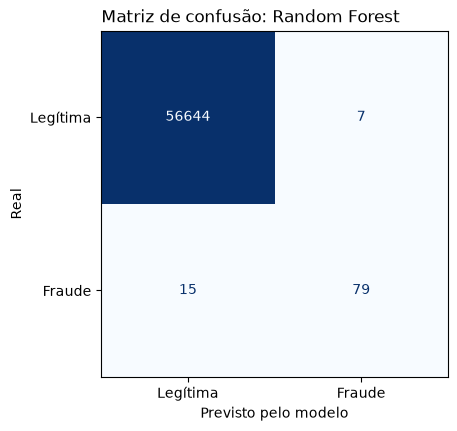

In [34]:
t0 = time.time()
modelos['Random Forest'].fit(X_train, y_train)
print(f'Random Forest treinado em {time.time() - t0:.0f}s\n')
metricas_validacao['Random Forest'], probas_validacao['Random Forest'] = relatorio_validacao(
    'Random Forest', modelos['Random Forest'], X_train, y_train, X_val, y_val, nome_arquivo='Matriz Random Forest')

📌 **Nota: Random Forest**
- 🔎 Encontrou **79 das 94** fraudes (recall de **0,840**), com **7** alarmes falsos (precisão de **0,919**); F1 de **0,878** e PR-AUC de **0,877**.
- 🔎 **Sobreajuste:** PR-AUC de **1,000** no treino contra **0,877** na validação.
- 🔎 É o mais lento: **cerca de 1 minuto** de treino, contra menos de 10 s do XGBoost.

### LightGBM

LightGBM treinado em 8s



AMOSTRA: GABARITO x PROBABILIDADE x PREVISÃO (limiar = 0.50)


,Gabarito,Probabilidade,Previsão da máquina
0,0,0.0,0
1,0,0.0,0
2,0,0.0,0
3,0,0.0,0
4,0,0.0,0
5,0,0.0,0
6,0,0.0,0
7,0,0.0,0


MÉTRICAS DE VALIDAÇÃO: LightGBM
Acurácia                 0.9995
Precisão                 0.8778
Recall (Sensibilidade)   0.8404
F1-Score                 0.8587
AUC-ROC                  0.9815
PR-AUC                   0.8555
                         (sorteio: PR-AUC = 0.0017, AUC-ROC = 0,50)



SOBREAJUSTE (treino x validação):
  PR-AUC : treino 1.0000 | validação 0.8555 | diferença +0.1445
  AUC-ROC: treino 1.0000 | validação 0.9815 | diferença +0.0185

              precision    recall  f1-score   support

Legítima (0)     0.9997    0.9998    0.9998     56651
  Fraude (1)     0.8778    0.8404    0.8587        94

    accuracy                         0.9995     56745
   macro avg     0.9388    0.9201    0.9292     56745
weighted avg     0.9995    0.9995    0.9995     56745



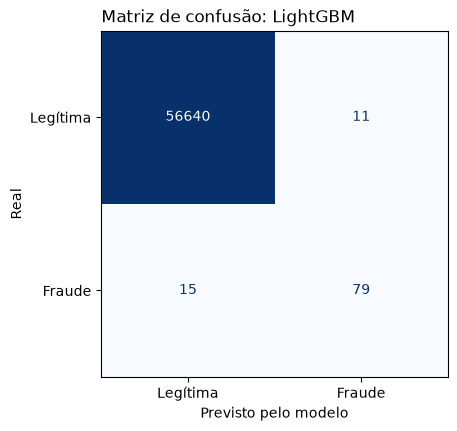

In [35]:
t0 = time.time()
modelos['LightGBM'].fit(X_train, y_train)
print(f'LightGBM treinado em {time.time() - t0:.0f}s\n')
metricas_validacao['LightGBM'], probas_validacao['LightGBM'] = relatorio_validacao(
    'LightGBM', modelos['LightGBM'], X_train, y_train, X_val, y_val, nome_arquivo='Matriz LightGBM')

📌 **Nota: LightGBM**
- 🔎 Encontrou **79 das 94** fraudes (recall de **0,840**), mas com **11** alarmes falsos (precisão de **0,878**); F1 de **0,859** e PR-AUC de **0,855**.
- 🔎 **Sobreajuste:** PR-AUC de **1,000** no treino contra **0,855** na validação.

### Regressão Logística

Regressão Logística treinado em 2s

AMOSTRA: GABARITO x PROBABILIDADE x PREVISÃO (limiar = 0.50)


,Gabarito,Probabilidade,Previsão da máquina
0,0,0.009,0
1,0,0.001,0
2,0,0.011,0
3,0,0.038,0
4,0,0.001,0
5,0,0.037,0
6,0,0.001,0
7,0,0.102,0


MÉTRICAS DE VALIDAÇÃO: Regressão Logística
Acurácia                 0.9733
Precisão                 0.0535
Recall (Sensibilidade)   0.9043
F1-Score                 0.1010
AUC-ROC                  0.9822
PR-AUC                   0.7876
                         (sorteio: PR-AUC = 0.0017, AUC-ROC = 0,50)



SOBREAJUSTE (treino x validação):
  PR-AUC : treino 0.7287 | validação 0.7876 | diferença -0.0590
  AUC-ROC: treino 0.9915 | validação 0.9822 | diferença +0.0093

              precision    recall  f1-score   support

Legítima (0)     0.9998    0.9735    0.9865     56651
  Fraude (1)     0.0535    0.9043    0.1010        94

    accuracy                         0.9733     56745
   macro avg     0.5267    0.9389    0.5437     56745
weighted avg     0.9983    0.9733    0.9850     56745



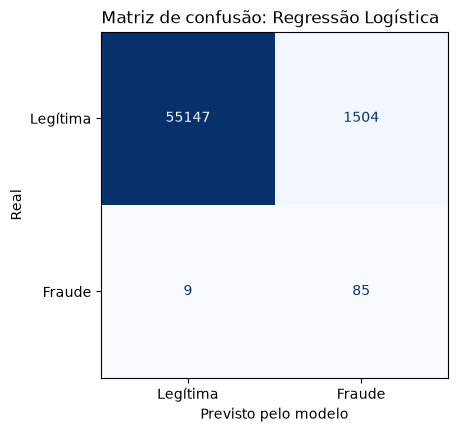

In [36]:
t0 = time.time()
modelos['Regressão Logística'].fit(X_train, y_train)
print(f'Regressão Logística treinado em {time.time() - t0:.0f}s\n')
metricas_validacao['Regressão Logística'], probas_validacao['Regressão Logística'] = relatorio_validacao(
    'Regressão Logística', modelos['Regressão Logística'], X_train, y_train, X_val, y_val, nome_arquivo='Matriz Regressao Logistica')

📌 **Nota: Regressão Logística**
- 🔎 Com o limiar de 0,5, encontrou **85 das 94** fraudes (recall de **0,904**), mas marcou **1.504** legítimas: precisão de só **0,054** e F1 de **0,101**.
- 💡 O peso da classe empurra as probabilidades para cima, e o limiar de 0,5 vira "marcar quase tudo que é estranho". A PR-AUC (**0,788**), que não depende do limiar, mostra que ela ordena bem as transações, mas pior que as árvores.
- 🔎 **Sem sobreajuste:** PR-AUC de **0,729** no treino e **0,788** na validação. É o modelo mais simples e o mais estável, mas uma fronteira linear não capta as interações das componentes.

### Validação cruzada

A validação tem só **94 fraudes**: um ou dois acertos a mais mudam muito as métricas. A validação cruzada estratificada (5 dobras, em treino + validação) mostra a **média ± desvio** e decide o modelo.

In [37]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
resultados_cv = {}
for nome, modelo in modelos.items():
    t0 = time.time()
    r = cross_validate(clone(modelo), X_temp, y_temp, cv=cv, scoring=['average_precision', 'recall', 'precision'])
    resultados_cv[nome] = {'PR-AUC (média)': r['test_average_precision'].mean(),
                           'PR-AUC (desvio)': r['test_average_precision'].std(),
                           'Recall (média)': r['test_recall'].mean(), 'Precisão (média)': r['test_precision'].mean(),
                           'Tempo (s)': time.time() - t0}
tabela_cv = pd.DataFrame(resultados_cv).T.sort_values('PR-AUC (média)', ascending=False)
melhor_modelo = tabela_cv.index[0]
print(f'Melhor modelo na validação cruzada: {melhor_modelo}')
for nome in modelos:   # as métricas e probabilidades já foram guardadas; libera os modelos treinados que não serão usados
    if nome != melhor_modelo:
        modelos[nome] = clone(modelos[nome])
_ = gc.collect()
tabela_cv.round(3)

Melhor modelo na validação cruzada: XGBoost


,PR-AUC (média),PR-AUC (desvio),Recall (média),Precisão (média),Tempo (s)
XGBoost,0.848,0.028,0.825,0.913,47.195
Random Forest,0.840,0.034,0.796,0.925,407.683
LightGBM,0.824,0.032,0.823,0.879,47.724
Regressão Logística,0.755,0.027,0.907,0.057,15.032


📌 **Nota: validação cruzada (5 dobras, treino + validação)**

| Modelo | PR-AUC (média ± desvio) | Tempo |
|---|---|---|
| **XGBoost** | **0,848 ± 0,028** | ~47 s |
| Random Forest | 0,840 ± 0,034 | ~7 min |
| LightGBM | 0,824 ± 0,032 | ~47 s |
| Regressão Logística | 0,755 ± 0,027 | ~13 s |

- 🔎 O **XGBoost** tem a melhor média. A diferença para o Random Forest (0,008) é menor que o desvio, mas o XGBoost é **cerca de 8 vezes mais rápido**.
- ✅ **Decisão:** ajustar o **XGBoost** (item 7).

## 6 - Comparação do desempenho dos modelos

**As métricas usadas, em uma tabela.** Em fraude, a classe positiva é rara (0,17%) e os dois erros têm custos muito diferentes. Com **VP** = fraudes encontradas, **FP** = alarmes falsos, **FN** = fraudes que passaram e **VN** = legítimas liberadas:

| Métrica | Fórmula | O que responde | Usar quando |
|---|---|---|---|
| Acurácia | (VP + VN) / total | Quantas transações o modelo acertou? | Classes equilibradas. **Aqui engana:** "nunca é fraude" acerta 99,83% |
| Precisão | VP / (VP + FP) | Das transações marcadas, quantas eram fraude? | O alarme falso é caro (aqui, ele define o tamanho da fila de revisão) |
| Recall (sensibilidade) | VP / (VP + FN) | Das fraudes, quantas o modelo encontrou? | Deixar passar é caro (aqui, a fraude perdida custa o valor da transação) |
| F1-Score | 2 x Precisão x Recall / (Precisão + Recall) | O equilíbrio entre as duas | Não há um custo definido para cada erro |
| Especificidade | VN / (VN + FP) | Das legítimas, quantas foram liberadas? | Medir o incômodo causado aos clientes bons |
| AUC-ROC | área sob a curva recall x taxa de falsos positivos (sorteio = 0,50) | O modelo ordena as fraudes acima das legítimas? | Comparar modelos com classes equilibradas. **Com 0,17% de fraudes, fica perto de 1 com facilidade** |
| PR-AUC | área sob a curva precisão x recall (sorteio = a taxa de fraude) | O modelo coloca as fraudes no topo da lista? | **Classe positiva rara: é a métrica principal deste projeto** |
| Brier score | média de (probabilidade − real)² | As probabilidades são confiáveis? | Comunicar o risco em % (calibração, item 8.4) |
| Economia líquida (R$) | valor das fraudes barradas − custo das revisões | Quanto o banco ganha com a regra? | **Decisão de negócio: é o critério do limiar** (item 8) |

> O modelo devolve uma **probabilidade**. Precisão, recall, F1 e especificidade dependem do **limiar** escolhido (item 8); a PR-AUC e o AUC-ROC não dependem: medem só a ordenação.

,Acurácia,Precisão,Recall (Sensibilidade),F1-Score,AUC-ROC,PR-AUC,PR-AUC CV (média ± desvio),Verdadeiros Positivos,Falsos Positivos,Falsos Negativos
XGBoost,1.000,0.930,0.851,0.889,0.977,0.891,0.848 ± 0.028,80.000000,6.000000,14.000000
Random Forest,1.000,0.919,0.840,0.878,0.956,0.877,0.840 ± 0.034,79.000000,7.000000,15.000000
LightGBM,1.000,0.878,0.840,0.859,0.982,0.855,0.824 ± 0.032,79.000000,11.000000,15.000000
Regressão Logística,0.973,0.053,0.904,0.101,0.982,0.788,0.755 ± 0.027,85.000000,1504.000000,9.000000
Modelo que chuta,0.998,0.000,0.000,0.000,0.500,0.002,–,0.000000,0.000000,94.000000


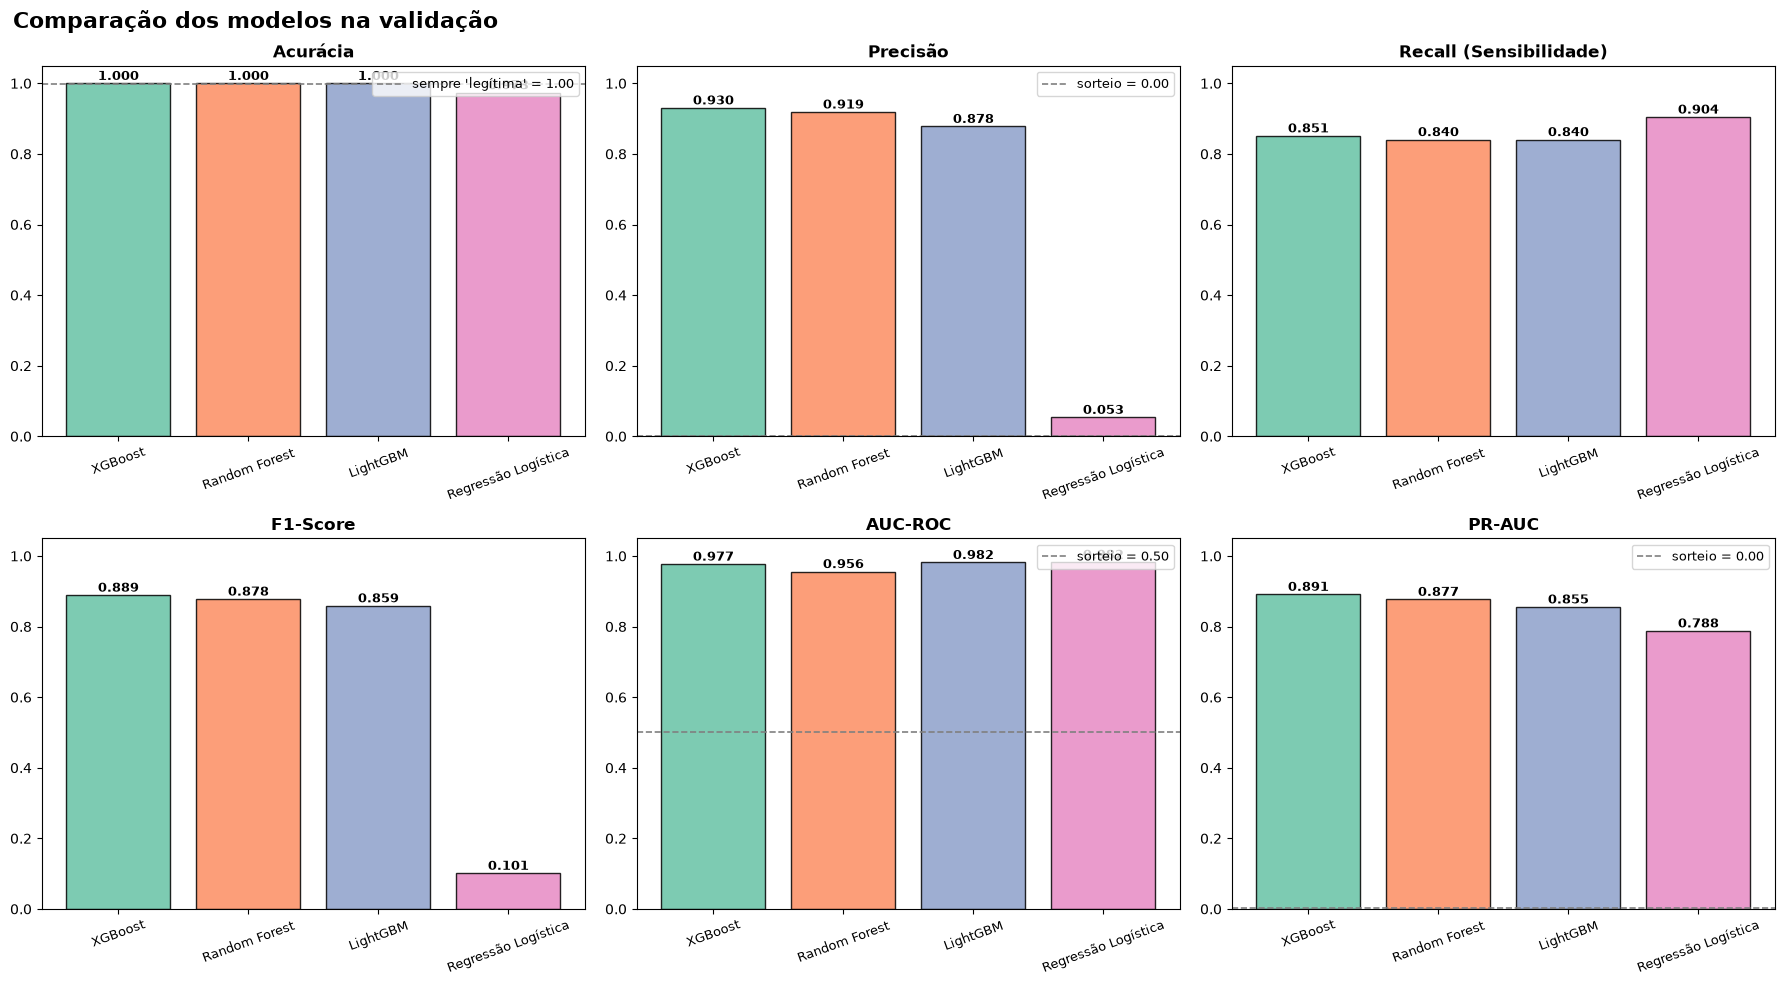

📊 SCORE GERAL (média de F1, PR-AUC, Recall e Precisão na validação):
• XGBoost              0.890 | PR-AUC CV 0.848 ± 0.028
• Random Forest        0.878 | PR-AUC CV 0.840 ± 0.034
• LightGBM             0.858 | PR-AUC CV 0.824 ± 0.032
• Regressão Logística  0.462 | PR-AUC CV 0.755 ± 0.027

💾 Resultados salvos em: reports/comparacao_modelos.csv


In [38]:
chute = DummyClassifier(strategy='prior').fit(X_train, y_train)   # "modelo que chuta": sempre a taxa de fraude
proba_chute = chute.predict_proba(X_val)[:, 1]
metricas_validacao_tabela = dict(metricas_validacao)
metricas_validacao_tabela['Modelo que chuta'] = calcular_metricas_completas(y_val, (proba_chute >= 0.5).astype(int), proba_chute)

df_comparacao = pd.DataFrame(metricas_validacao_tabela).T
df_comparacao['PR-AUC CV (média ± desvio)'] = [
    f"{tabela_cv.loc[m, 'PR-AUC (média)']:.3f} ± {tabela_cv.loc[m, 'PR-AUC (desvio)']:.3f}" if m in tabela_cv.index else '–'
    for m in df_comparacao.index]
df_comparacao = df_comparacao.sort_values('PR-AUC', ascending=False)
PASTA_REPORTS.mkdir(exist_ok=True)
df_comparacao.to_csv(PASTA_REPORTS / 'comparacao_modelos.csv')

colunas = ['Acurácia', 'Precisão', 'Recall (Sensibilidade)', 'F1-Score', 'AUC-ROC', 'PR-AUC', 'PR-AUC CV (média ± desvio)',
           'Verdadeiros Positivos', 'Falsos Positivos', 'Falsos Negativos']
display(df_comparacao[colunas].style.format('{:.3f}', subset=colunas[:6]))

plot_comparacao_modelos(metricas_validacao, y_val.mean(), 'Comparacao dos modelos')

score_geral = df_comparacao.loc[list(metricas_validacao), ['F1-Score', 'PR-AUC', 'Recall (Sensibilidade)', 'Precisão']].mean(axis=1)
print('📊 SCORE GERAL (média de F1, PR-AUC, Recall e Precisão na validação):')
for nome, valor in score_geral.sort_values(ascending=False).items():
    print(f'• {nome:<20} {valor:.3f} | PR-AUC CV {df_comparacao.loc[nome, "PR-AUC CV (média ± desvio)"]}')
print('\n💾 Resultados salvos em: reports/comparacao_modelos.csv')

📌 **Nota**
- 🔎 Na validação, o **XGBoost** lidera em PR-AUC (**0,891**), F1 (**0,889**) e score geral (**0,890**), confirmando a validação cruzada.
- 🔎 O **modelo que chuta** tem PR-AUC de **0,002** e não encontra nenhuma fraude: todos os modelos são muito melhores que o acaso.
- ⚠️ A versão original comparava os modelos por acurácia (99,92% a 99,95%), que não separa um bom modelo de um ruim. ✅ Na v2, o painel mostra a linha do "modelo que chuta" em cada métrica.

## 7 - AJUSTE FINO DE HIPERPARÂMETROS

**Parâmetros x hiperparâmetros.** Os **parâmetros** são o que o modelo aprende sozinho com os dados (no XGBoost, as perguntas de cada árvore e o valor de cada folha). Os **hiperparâmetros** são as configurações que **nós** escolhemos antes do treino e que controlam **como** ele aprende. No XGBoost, os principais são:

| Hiperparâmetro | O que controla | Em palavras simples |
|---|---|---|
| `n_estimators` | o número de árvores | quantas correções em sequência o modelo faz |
| `max_depth` | a profundidade de cada árvore | quantas perguntas cada árvore pode fazer |
| `learning_rate` | o peso de cada árvore nova | o tamanho de cada passo de correção |
| `subsample` e `colsample_bytree` | a fração de linhas e de colunas que cada árvore vê | variedade entre as árvores, contra o sobreajuste |
| `min_child_weight` | o "tamanho" mínimo de uma folha | evita regras feitas para pouquíssimas transações |
| `scale_pos_weight` | o peso de cada fraude no treino | o quanto errar uma fraude "dói" mais que errar uma legítima |

Com **7 hiperparâmetros** e um modelo que leva segundos para treinar, este é o cenário em que a escolha do **método de busca** pesa. Comparamos os três mais usados, todos com as **mesmas 3 dobras estratificadas** do treino e a mesma métrica (PR-AUC):

| Método | Como escolhe as combinações | Ponto forte | Ponto fraco |
|---|---|---|---|
| **Grid Search** | testa **todas** as combinações de uma grade | se a melhor estiver na grade, ele a encontra | o custo **explode** com o número de hiperparâmetros |
| **Random Search** | **sorteia** N combinações | explora mais valores com o mesmo orçamento | não aprende com o que já testou |
| **Bayesiana (Optuna)** | usa os resultados anteriores para escolher a **próxima** combinação | concentra as tentativas nas regiões promissoras e, com a **poda**, abandona no meio as tentativas ruins | mais complexa de explicar |

> 🛡️ **O teste fica trancado.** Escolher os hiperparâmetros pelo resultado no teste ajustaria o modelo **àquelas** 95 fraudes (sobreajuste de hiperparâmetros). A escolha usa só a **validação cruzada do treino**; o teste é aberto uma única vez, no item 7.6.

> 🔁 **Por que dobras estratificadas?** Com 0,17% de fraudes, uma divisão comum pode deixar uma dobra com bem menos fraudes que as outras. O *Stratified K-Fold* garante a mesma proporção (cerca de 95 fraudes) em cada dobra. A base tem ordem no tempo, mas a busca segue a separação aleatória do projeto; o efeito do tempo é medido à parte, na validação temporal (Fase 04, item 1.2).

### 7.1. Grid Search

Uma grade com os 7 hiperparâmetros, mesmo com só 3 valores em cada um, teria 3⁷ = **2.187 combinações** x 3 dobras = **6.561 modelos**. Por isso, o Grid fica com os **3 hiperparâmetros** que mais mudam o XGBoost, numa grade grossa, e fixa os outros (400 árvores; `subsample`, `colsample_bytree` e `min_child_weight` no padrão):
- `max_depth`: 3, 5 e 7;
- `learning_rate`: 0,05, 0,1 e 0,2;
- `scale_pos_weight`: 1 (sem peso) e a raiz da proporção de legítimas por fraude.

Grade: 18 combinações x 3 dobras = 54 modelos treinados


Grid Search concluído em 17.2 min | melhor PR-AUC (CV): 0.8372
Melhores hiperparâmetros: {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 400, 'scale_pos_weight': 24.463}
No mesmo ritmo (19 s por modelo), a grade completa de 6.561 modelos levaria ~35 horas


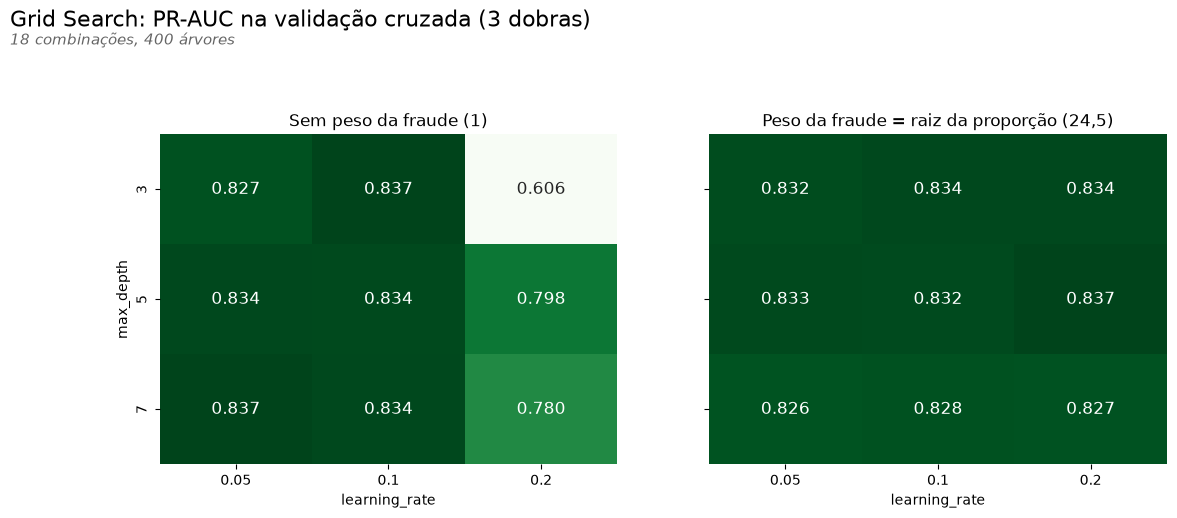

In [39]:
proporcao_raiz = float(np.sqrt(proporcao))
grades = {
    'XGBoost': {'max_depth': [3, 5, 7], 'learning_rate': [0.05, 0.1, 0.2], 'scale_pos_weight': [1, proporcao_raiz], 'n_estimators': [400]},
    'LightGBM': {'num_leaves': [15, 31, 63], 'learning_rate': [0.05, 0.1, 0.2], 'n_estimators': [400]},
    'Random Forest': {'max_depth': [None, 10, 20], 'min_samples_leaf': [1, 5], 'n_estimators': [200]},
    'Regressão Logística': {'modelo__C': np.logspace(-3, 2, 11).tolist()},
}
cv_busca = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMENTE)   # as mesmas 3 dobras nos 3 métodos
grade = grades[melhor_modelo]
n_combinacoes = int(np.prod([len(valores) for valores in grade.values()]))
modelos_grid = n_combinacoes * cv_busca.get_n_splits()
print(f'Grade: {n_combinacoes} combinações x {cv_busca.get_n_splits()} dobras = {modelos_grid} modelos treinados')

grid = GridSearchCV(clone(modelos[melhor_modelo]), grade, scoring='average_precision', cv=cv_busca, return_train_score=True)
t0 = time.time()
grid.fit(X_train, y_train)
tempo_grid = time.time() - t0
print(f'Grid Search concluído em {tempo_grid / 60:.1f} min | melhor PR-AUC (CV): {grid.best_score_:.4f}')
print('Melhores hiperparâmetros:', {k: round(v, 3) if isinstance(v, float) else v for k, v in grid.best_params_.items()})
print(f'No mesmo ritmo ({tempo_grid / modelos_grid:.0f} s por modelo), a grade completa de 6.561 modelos levaria '
      f'~{6561 * tempo_grid / modelos_grid / 3600:.0f} horas')

# Mapa de calor: PR-AUC (CV) de cada profundidade x taxa de aprendizado, sem e com peso da fraude
if melhor_modelo == 'XGBoost':
    resultados_grid = pd.DataFrame(grid.cv_results_)
    fig, axs = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    for ax, peso in zip(axs, grade['scale_pos_weight']):
        mapa = resultados_grid[resultados_grid['param_scale_pos_weight'] == peso].pivot_table(
            index='param_max_depth', columns='param_learning_rate', values='mean_test_score')
        sns.heatmap(mapa, annot=True, fmt='.3f', cmap='Greens', cbar=False, ax=ax, annot_kws={'fontsize': 12},
                    vmin=resultados_grid['mean_test_score'].min(), vmax=resultados_grid['mean_test_score'].max())
        ax.set(title='Sem peso da fraude (1)' if peso == 1 else f'Peso da fraude = raiz da proporção ({peso:.1f})'.replace('.', ','),
               xlabel='learning_rate', ylabel='max_depth' if ax is axs[0] else '')
    titulo('Grid Search: PR-AUC na validação cruzada (3 dobras)', f'{n_combinacoes} combinações, 400 árvores')
    fig.subplots_adjust(top=0.85 - 0.4 / fig.get_figheight())
    salvar('Grid search')
    plt.show()

📌 **Nota**
- 🔎 A grade treinou **54 modelos** em **17,2 min** (19 s por modelo). A melhor combinação é **max_depth = 5, learning_rate = 0,2 e peso da fraude = 24,5**, com PR-AUC de **0,837** na validação cruzada.
- 🔎 **Com o peso da fraude** (painel da direita), as 9 combinações ficam entre **0,826 e 0,837**: nessa faixa, o XGBoost é pouco sensível à profundidade e à taxa de aprendizado.
- 🔎 **Sem o peso** (painel da esquerda), a taxa de aprendizado de 0,2 desaba: **0,606** com profundidade 3 e de **0,780 a 0,798** com 5 e 7. Com passos menores (0,05 e 0,1), chega aos mesmos **0,837**. O peso da fraude deixa o modelo mais estável.
- 💡 **A explosão da grade:** no mesmo ritmo, a grade completa dos 7 hiperparâmetros com 3 valores cada (6.561 modelos) levaria **~35 horas**. Por isso, o Grid só serve para poucos hiperparâmetros.

### 7.2. Random Search

O Random Search **sorteia** 20 combinações dos 7 hiperparâmetros, com valores vindos de distribuições **contínuas** (`loguniform` para a taxa de aprendizado, `uniform` para as frações), em vez de listas fixas. Ele **otimiza a PR-AUC** (a versão original otimizava a acurácia, que é quase 100% para qualquer modelo) nas mesmas 3 dobras estratificadas do treino.

Busca (XGBoost) concluída em 26.7 min | melhor PR-AUC (CV): 0.8410


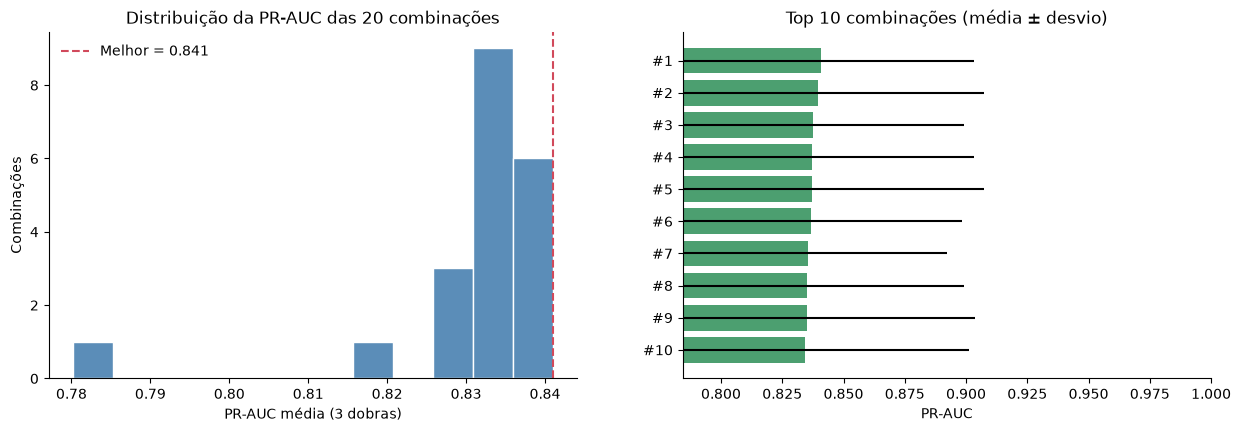

,rank_test_score,mean_test_score,std_test_score,param_colsample_bytree,param_learning_rate,param_max_depth,param_min_child_weight,param_n_estimators,param_scale_pos_weight,param_subsample
16,1,0.8410,0.0621,0.8566,0.1570,4,7,454,24.4626,0.7975
15,2,0.8398,0.0674,0.6626,0.1442,8,3,648,598.4190,0.6478
13,3,0.8375,0.0616,0.8534,0.1440,3,5,689,598.4190,0.8604
7,4,0.8373,0.0659,0.8050,0.1910,5,1,619,24.4626,0.8650
5,5,0.8371,0.0700,0.7334,0.2053,7,9,366,24.4626,0.9796


In [40]:
espacos = {
    'XGBoost': (xgb.XGBClassifier(random_state=SEMENTE, n_jobs=N_JOBS, scale_pos_weight=proporcao),
                {'n_estimators': randint(200, 700), 'max_depth': randint(3, 9), 'learning_rate': loguniform(0.02, 0.3),
                 'subsample': uniform(0.6, 0.4), 'colsample_bytree': uniform(0.5, 0.5), 'min_child_weight': randint(1, 10),
                 'scale_pos_weight': [1, np.sqrt(proporcao), proporcao]}),
    'LightGBM': (lgb.LGBMClassifier(random_state=SEMENTE, verbose=-1, class_weight='balanced'),
                 {'n_estimators': randint(200, 700), 'num_leaves': randint(15, 127), 'learning_rate': loguniform(0.02, 0.3),
                  'subsample': uniform(0.6, 0.4), 'subsample_freq': [1], 'colsample_bytree': uniform(0.5, 0.5)}),
    'Random Forest': (RandomForestClassifier(random_state=SEMENTE, n_jobs=N_JOBS, class_weight='balanced'),
                      {'n_estimators': randint(100, 400), 'max_depth': [None, 10, 20, 30], 'min_samples_leaf': randint(1, 10),
                       'max_features': ['sqrt', 'log2', 0.5]}),
    'Regressão Logística': (pipeline_logistica(class_weight='balanced'),
                            {'modelo__C': loguniform(0.001, 100)}),
}
estimador_base, espaco = espacos[melhor_modelo]

busca = RandomizedSearchCV(estimador_base, espaco, n_iter=20, scoring='average_precision', cv=cv_busca, random_state=SEMENTE,
                           return_train_score=True)
t0 = time.time()
busca.fit(X_train, y_train)
tempo_random = time.time() - t0
print(f'Busca ({melhor_modelo}) concluída em {tempo_random / 60:.1f} min | melhor PR-AUC (CV): {busca.best_score_:.4f}')

resultados_busca = pd.DataFrame(busca.cv_results_).sort_values('rank_test_score')
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
axs[0].hist(resultados_busca['mean_test_score'], bins=12, color='#5B8DB8', edgecolor='white')
axs[0].axvline(busca.best_score_, color=COR_FRAUDE, ls='--', label=f'Melhor = {busca.best_score_:.3f}')
axs[0].set(title='Distribuição da PR-AUC das 20 combinações', xlabel='PR-AUC média (3 dobras)', ylabel='Combinações')
axs[0].legend(frameon=False)
top10_busca = resultados_busca.head(10)
axs[1].barh(range(10)[::-1], top10_busca['mean_test_score'], xerr=top10_busca['std_test_score'], color='#4C9F70')
axs[1].set(yticks=range(10)[::-1], yticklabels=[f'#{i}' for i in top10_busca['rank_test_score']],
           title='Top 10 combinações (média ± desvio)', xlabel='PR-AUC')
axs[1].set_xlim(top10_busca['mean_test_score'].min() - 0.05, 1)
sns.despine()
salvar('Random Search')
plt.show()

colunas_parametros = [c for c in resultados_busca if c.startswith('param_')]
resultados_busca[['rank_test_score', 'mean_test_score', 'std_test_score'] + colunas_parametros].head(5).round(4)

📌 **Nota: busca de hiperparâmetros**
- 🔎 As **20 combinações** levaram **26,7 minutos** (agora calculando também a PR-AUC no treino, para medir o sobreajuste no item 7.4). A melhor teve PR-AUC de **0,841** nas 3 dobras, e as 5 melhores ficaram entre **0,837 e 0,841**: diferenças muito menores que o desvio entre as dobras (~**0,06**).
- 🔎 A melhor combinação usa árvores rasas (**max_depth = 4**), **454** árvores e um peso para a fraude de **24,5** (a raiz da proporção de 599 legítimas por fraude): um peso menor que o "totalmente balanceado" funcionou melhor.
- ⚠️ A versão original otimizava a **acurácia** (99,94% a 99,95% em todas as combinações). ✅ Na v2, a busca otimiza a **PR-AUC**.

### 7.3. Otimização Bayesiana (Optuna)

O Grid e o Random Search **não aprendem** com o que já testaram. A otimização **Bayesiana** usa o histórico: depois de cada tentativa (*trial*), um modelo probabilístico (o **TPE** do Optuna) estima onde estão as combinações promissoras e escolhe a próxima, equilibrando **exploração** (regiões desconhecidas; as 10 primeiras tentativas são sorteadas) e **explotação** (refinar em volta das melhores).

Aqui usamos também a **poda** (*pruning*): a validação cruzada roda **dobra a dobra**, e depois de cada dobra a PR-AUC média até ali é informada ao Optuna (`trial.report`). Se ela ficar abaixo da **mediana** das tentativas anteriores na mesma dobra (`MedianPruner`, a partir da 6ª tentativa), a tentativa é abandonada e as dobras restantes não são treinadas. Depois da **última** dobra não há poda: o custo já foi pago, e a tentativa conta como completa. Num modelo caro como este, é aí que a Bayesiana pode economizar tempo.

Mesmos 7 hiperparâmetros, mesmas faixas e mesmo orçamento do Random Search: **20 tentativas**.

Optuna concluído em 15.6 min | melhor PR-AUC (CV): 0.8420 (tentativa nº 8)
Melhores hiperparâmetros: {'n_estimators': 350, 'max_depth': 4, 'learning_rate': 0.087, 'subsample': 0.6564, 'colsample_bytree': 0.9011, 'min_child_weight': 1, 'scale_pos_weight': 1.0}
Tentativas podadas: 10 de 20 | modelos treinados: 40 de 60 possíveis


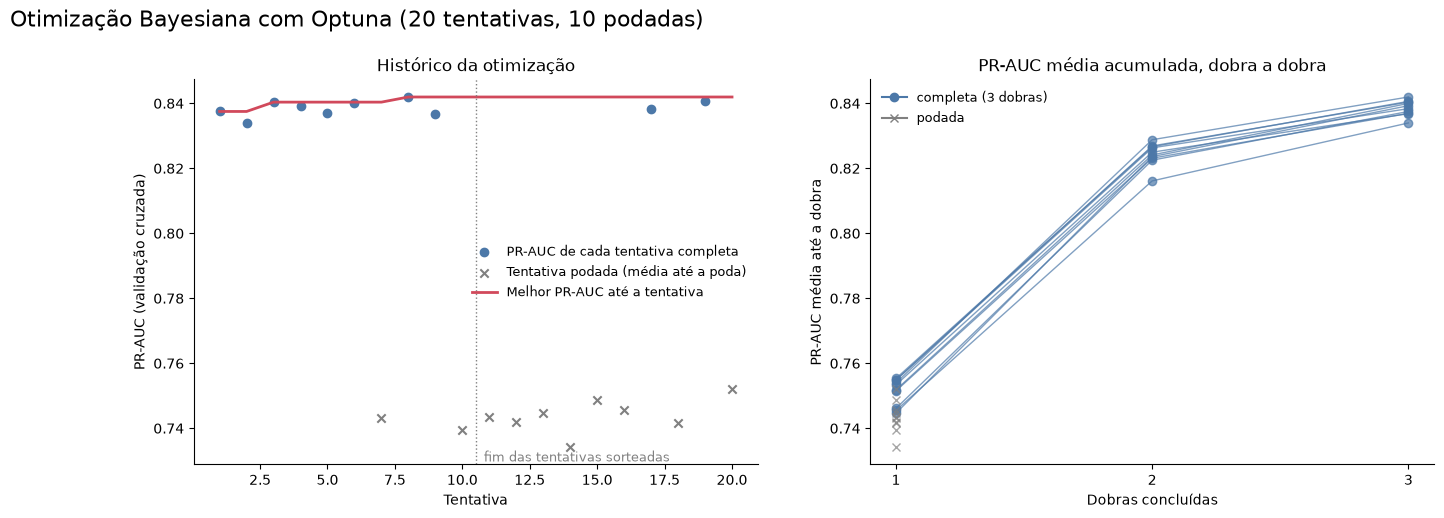

In [41]:
espacos_optuna = {
    'XGBoost': lambda t: {'n_estimators': t.suggest_int('n_estimators', 200, 700, step=50),
                          'max_depth': t.suggest_int('max_depth', 3, 8),
                          'learning_rate': t.suggest_float('learning_rate', 0.02, 0.3, log=True),
                          'subsample': t.suggest_float('subsample', 0.6, 1.0),
                          'colsample_bytree': t.suggest_float('colsample_bytree', 0.5, 1.0),
                          'min_child_weight': t.suggest_int('min_child_weight', 1, 9),
                          'scale_pos_weight': t.suggest_categorical('scale_pos_weight', [1.0, round(proporcao_raiz, 4), round(float(proporcao), 4)])},
    'LightGBM': lambda t: {'n_estimators': t.suggest_int('n_estimators', 200, 700, step=50),
                           'num_leaves': t.suggest_int('num_leaves', 15, 127, log=True),
                           'learning_rate': t.suggest_float('learning_rate', 0.02, 0.3, log=True),
                           'subsample': t.suggest_float('subsample', 0.6, 1.0), 'subsample_freq': 1,
                           'colsample_bytree': t.suggest_float('colsample_bytree', 0.5, 1.0)},
    'Random Forest': lambda t: {'n_estimators': t.suggest_int('n_estimators', 100, 400, step=50),
                                'max_depth': t.suggest_int('max_depth', 5, 30),
                                'min_samples_leaf': t.suggest_int('min_samples_leaf', 1, 9),
                                'max_features': t.suggest_float('max_features', 0.1, 0.6)},
    'Regressão Logística': lambda t: {'modelo__C': t.suggest_float('C', 1e-3, 100, log=True)},
}
estudo = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEMENTE),
                             pruner=optuna.pruners.MedianPruner(n_startup_trials=5))
objetivo = objetivo_cv_com_poda(modelos[melhor_modelo], espacos_optuna[melhor_modelo], X_train, y_train, cv_busca,
                                average_precision_score)
t0 = time.time()
estudo.optimize(objetivo, n_trials=20)
tempo_optuna = time.time() - t0
podadas = [t for t in estudo.trials if t.state == optuna.trial.TrialState.PRUNED]
modelos_optuna = modelos_treinados_optuna(estudo, cv_busca.get_n_splits())
print(f'Optuna concluído em {tempo_optuna / 60:.1f} min | melhor PR-AUC (CV): {estudo.best_value:.4f} '
      f'(tentativa nº {estudo.best_trial.number + 1})')
print('Melhores hiperparâmetros:', {k: round(v, 4) if isinstance(v, float) else v for k, v in estudo.best_params.items()})
print(f'Tentativas podadas: {len(podadas)} de {len(estudo.trials)} | modelos treinados: {modelos_optuna} '
      f'de {len(estudo.trials) * cv_busca.get_n_splits()} possíveis')

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
valores, melhor_ate_aqui = historico_optuna(estudo)
numeros = np.arange(1, len(valores) + 1)
axs[0].scatter(numeros, valores, color=COR_LEGITIMA, label='PR-AUC de cada tentativa completa')   # podadas = NaN
if podadas:
    axs[0].scatter([t.number + 1 for t in podadas], [t.intermediate_values[max(t.intermediate_values)] for t in podadas],
                   marker='x', color='grey', label='Tentativa podada (média até a poda)')
axs[0].plot(numeros, melhor_ate_aqui, color=COR_FRAUDE, lw=2, label='Melhor PR-AUC até a tentativa')
axs[0].axvline(10.5, color='grey', ls=':', lw=1)
axs[0].text(10.8, axs[0].get_ylim()[0], 'fim das tentativas sorteadas', va='bottom', fontsize=9, color='grey')
axs[0].set(title='Histórico da otimização', xlabel='Tentativa', ylabel='PR-AUC (validação cruzada)')
axs[0].legend(frameon=False, fontsize=9)
for tentativa in estudo.trials:
    passos = sorted(tentativa.intermediate_values)
    poda = tentativa.state == optuna.trial.TrialState.PRUNED
    axs[1].plot([p + 1 for p in passos], [tentativa.intermediate_values[p] for p in passos], marker='x' if poda else 'o',
                color='grey' if poda else COR_LEGITIMA, alpha=0.7, lw=1)
axs[1].plot([], [], color=COR_LEGITIMA, marker='o', label='completa (3 dobras)')
axs[1].plot([], [], color='grey', marker='x', label='podada')
axs[1].set(xticks=[1, 2, 3], title='PR-AUC média acumulada, dobra a dobra', xlabel='Dobras concluídas', ylabel='PR-AUC média até a dobra')
axs[1].legend(frameon=False, fontsize=9)
sns.despine()
titulo(f'Otimização Bayesiana com Optuna ({len(estudo.trials)} tentativas, {len(podadas)} podadas)')
salvar('Otimizacao bayesiana')
plt.show()

📌 **Nota**
- 🔎 A melhor tentativa foi a **nº 8**, ainda na fase sorteada: PR-AUC de **0,842** com 350 árvores, max_depth = 4, learning_rate = 0,087 e **sem peso da fraude** (1,0). A busca guiada pelo TPE (tentativas 11 a 20) não superou esse resultado.
- 🔎 **A poda cortou 10 das 20 tentativas, todas logo depois da 1ª dobra.** Foram treinados **40 modelos** em vez de 60 (10 completas × 3 dobras + 10 podadas × 1 dobra, **um terço a menos**), em **15,6 min**, contra **26,7 min** do Random Search com o mesmo orçamento de 20 combinações.
- ⚠️ **Limite da poda (gráfico da direita):** na 1ª dobra, as tentativas podadas ficavam só um pouco abaixo das completas, uma diferença menor que o desvio entre as dobras. A poda troca um pouco de risco (descartar uma combinação boa) por tempo. Depois da última dobra não há poda: nenhum modelo é treinado à toa.
- 💡 Neste modelo caro, a Bayesiana com poda foi o método **mais barato**.

### 7.4. Comparação dos 3 métodos

Os métodos lado a lado, junto com o modelo **sem ajuste** (hiperparâmetros padrão, com o peso da classe): o ganho do ajuste só existe se for medido contra essa referência. Para cada método: a melhor PR-AUC da validação cruzada (± desvio entre as dobras), a PR-AUC no próprio treino (a diferença indica **sobreajuste**), o custo (modelos treinados e tempo) e a PR-AUC na **validação** (dados fora da busca).

**Regra de escolha:** a maior PR-AUC da validação cruzada. Se um método novo ganhar do Random Search (usado até a versão anterior) por **menos que o desvio entre as dobras**, a diferença é ruído e o Random Search continua, para não trocar o modelo, o limiar e o app sem ganho real.

,PR-AUC CV,desvio,PR-AUC treino,sobreajuste,PR-AUC validação,Combinações testadas,Modelos treinados,Tempo (min)
Método,,,,,,,,
Padrão (sem ajuste),0.8199,0.0760,1.0000,0.1801,0.8913,1,3,–
Grid Search,0.8372,0.0693,1.0000,0.1628,0.8803,18,54,17.2
Random Search,0.8410,0.0621,1.0000,0.1590,0.8892,20,60,26.7
Bayesiana (Optuna),0.8420,0.0639,1.0000,0.1580,0.8862,20,40,15.6


Padrão (sem ajuste)  padrão do XGBoost, com peso da classe = 598.4
Grid Search          {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 400, 'scale_pos_weight': 24.4626}
Random Search        {'colsample_bytree': 0.8566, 'learning_rate': 0.157, 'max_depth': 4, 'min_child_weight': 7, 'n_estimators': 454, 'scale_pos_weight': 24.4626, 'subsample': 0.7975}
Bayesiana (Optuna)   {'n_estimators': 350, 'max_depth': 4, 'learning_rate': 0.087, 'subsample': 0.6564, 'colsample_bytree': 0.9011, 'min_child_weight': 1, 'scale_pos_weight': 1.0}

Maior PR-AUC na validação cruzada: Bayesiana (Optuna) (+0.0009 sobre o Random Search)
✅ Método escolhido: Random Search


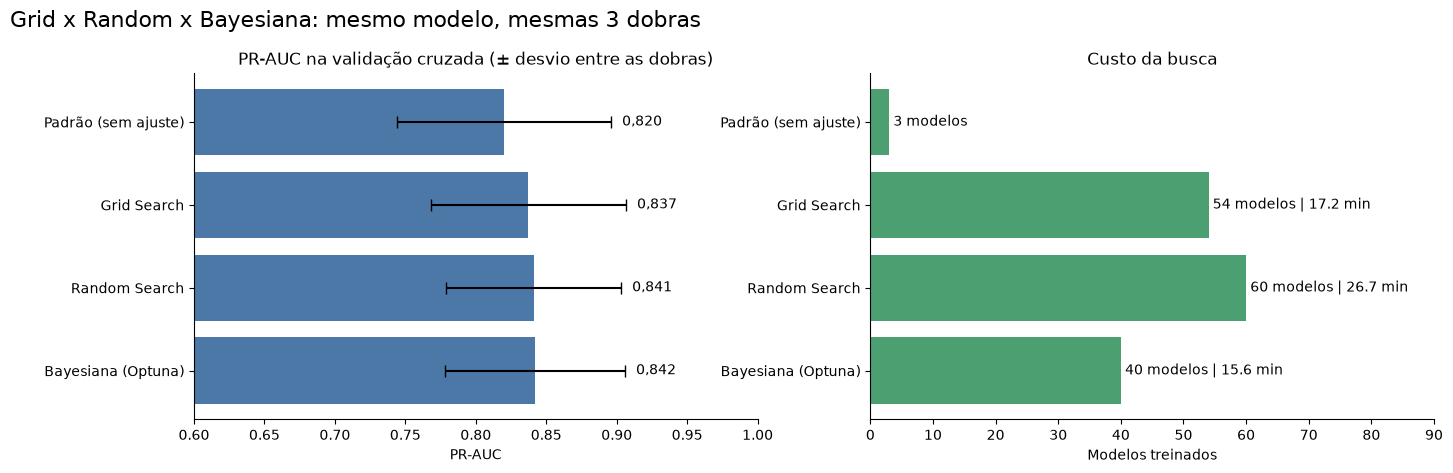

In [42]:
cv_padrao = cross_validate(clone(modelos[melhor_modelo]), X_train, y_train, cv=cv_busca, scoring='average_precision',
                           return_train_score=True)
parametros_por_metodo = {'Grid Search': grid.best_params_, 'Random Search': busca.best_params_,
                         'Bayesiana (Optuna)': espacos_optuna[melhor_modelo](estudo.best_trial)}
estimadores = {'Padrão (sem ajuste)': modelos[melhor_modelo], 'Grid Search': grid.best_estimator_, 'Random Search': busca.best_estimator_,
               'Bayesiana (Optuna)': clone(modelos[melhor_modelo]).set_params(**parametros_por_metodo['Bayesiana (Optuna)']).fit(X_train, y_train)}
linhas = [{'Método': 'Padrão (sem ajuste)', 'Melhor score (CV)': cv_padrao['test_score'].mean(), 'Desvio entre dobras': cv_padrao['test_score'].std(),
           'Score no treino': cv_padrao['train_score'].mean(), 'Combinações testadas': 1, 'Modelos treinados': cv_busca.get_n_splits(),
           'Tempo (s)': np.nan, 'Melhores hiperparâmetros': f'padrão do {melhor_modelo}, com peso da classe = {proporcao:.1f}'},
          resumo_sklearn('Grid Search', grid, tempo_grid), resumo_sklearn('Random Search', busca, tempo_random),
          resumo_optuna('Bayesiana (Optuna)', estudo, tempo_optuna, cv_busca.get_n_splits())]
comparacao_busca = pd.DataFrame(linhas).set_index('Método').rename(columns={
    'Melhor score (CV)': 'PR-AUC CV', 'Desvio entre dobras': 'desvio', 'Score no treino': 'PR-AUC treino'})
comparacao_busca['sobreajuste'] = comparacao_busca['PR-AUC treino'] - comparacao_busca['PR-AUC CV']
comparacao_busca['PR-AUC validação'] = [average_precision_score(y_val, m.predict_proba(X_val)[:, 1]) for m in estimadores.values()]
comparacao_busca['Tempo (min)'] = comparacao_busca['Tempo (s)'] / 60
colunas_tabela = ['PR-AUC CV', 'desvio', 'PR-AUC treino', 'sobreajuste', 'PR-AUC validação', 'Combinações testadas', 'Modelos treinados', 'Tempo (min)']
display(comparacao_busca[colunas_tabela].style.format({c: '{:.4f}' for c in colunas_tabela[:5]} | {'Tempo (min)': '{:.1f}'}, na_rep='–')
        .highlight_max(subset=['PR-AUC CV'], color='#C8E6C9'))
for metodo, parametros in comparacao_busca['Melhores hiperparâmetros'].items():
    print(f'{metodo:20s}', {k: round(float(v), 4) if isinstance(v, float) else v for k, v in parametros.items()} if isinstance(parametros, dict) else parametros)

# Escolha: maior PR-AUC da validação cruzada, com a regra do desvio entre as dobras
ajustados = comparacao_busca.drop('Padrão (sem ajuste)')
vencedor = ajustados['PR-AUC CV'].idxmax()
ganho_sobre_random = ajustados.loc[vencedor, 'PR-AUC CV'] - ajustados.loc['Random Search', 'PR-AUC CV']
metodo_escolhido = vencedor if (vencedor == 'Random Search' or ganho_sobre_random >= ajustados.loc[vencedor, 'desvio']) else 'Random Search'
melhor_estimador = estimadores[metodo_escolhido]
melhor_score_cv = float(comparacao_busca.loc[metodo_escolhido, 'PR-AUC CV'])
melhores_params = parametros_por_metodo[metodo_escolhido]
print(f'\nMaior PR-AUC na validação cruzada: {vencedor} ({ganho_sobre_random:+.4f} sobre o Random Search)')
print(f'✅ Método escolhido: {metodo_escolhido}')

fig, axs = plt.subplots(1, 2, figsize=(16, 4.5))
ordem = comparacao_busca.index
axs[0].barh(ordem, comparacao_busca['PR-AUC CV'], xerr=comparacao_busca['desvio'], color=COR_LEGITIMA, capsize=4)
axs[0].bar_label(axs[0].containers[1], labels=[f'{v:.3f}'.replace('.', ',') for v in comparacao_busca['PR-AUC CV']], padding=8)
axs[0].set(xlim=(0.6, 1.0), title='PR-AUC na validação cruzada (± desvio entre as dobras)', xlabel='PR-AUC')
axs[1].barh(ordem, comparacao_busca['Modelos treinados'], color='#4C9F70')
axs[1].bar_label(axs[1].containers[0], labels=[f'{n} modelos' + (f' | {t:.1f} min' if t == t else '') for n, t in
                                               zip(comparacao_busca['Modelos treinados'], comparacao_busca['Tempo (min)'])], padding=3)
axs[1].set(title='Custo da busca', xlabel='Modelos treinados', xlim=(0, comparacao_busca['Modelos treinados'].max() * 1.5))
for ax in axs:
    ax.invert_yaxis()
sns.despine()
titulo('Grid x Random x Bayesiana: mesmo modelo, mesmas 3 dobras')
salvar('Comparacao dos metodos de busca')
plt.show()

📌 **Nota**

| Método | PR-AUC CV | Sobreajuste (treino − CV) | PR-AUC validação | Custo |
|---|---|---|---|---|
| Padrão (peso = 598) | 0,820 ± 0,076 | 0,180 | **0,891** | 3 modelos |
| Grid Search | 0,837 ± 0,069 | 0,163 | 0,880 | 54 modelos, 17,2 min |
| Random Search | 0,841 ± 0,062 | 0,159 | 0,889 | 60 modelos, 26,7 min |
| Bayesiana (Optuna) | **0,842 ± 0,064** | **0,158** | 0,886 | **40 modelos, 15,6 min** |

- 🔎 Os três métodos melhoram o modelo padrão (de **+0,017 a +0,023** de PR-AUC na validação cruzada) e chegam a respostas parecidas: árvores de profundidade **4 ou 5** e um peso da fraude **moderado**, a raiz da proporção (24,5) no Grid e no Random e nenhum peso na Bayesiana, nunca a proporção inteira (598) do padrão. O mapa de calor do Grid já mostrava isso: sem peso, as taxas de aprendizado menores chegam aos mesmos 0,837.
- 🔎 A Bayesiana tem a maior PR-AUC, mas só **+0,0009** acima do Random Search, cerca de **1/70 do desvio entre as dobras** (0,064): empate técnico. Na validação, a ordem muda (Random 0,889, Bayesiana 0,886, Grid 0,880) e o padrão fica em primeiro (0,891), outro sinal de que, com 94 fraudes, essas diferenças são ruído.
- 🔎 A PR-AUC no treino é **1,000** em todos: o XGBoost decora o treino. O ajuste reduz um pouco a distância (de 0,180 para 0,158 a 0,163), mas o que decide é a validação cruzada.
- ✅ **Decisão:** pela regra do desvio, o **Random Search continua**. O modelo, o limiar de 0,11, a regra de valor, a ficha e o app não mudam.
- 💡 **Lição:** com 7 hiperparâmetros e um treino caro, a vantagem da Bayesiana com poda foi o **custo** (um terço menos modelos, o menor tempo), e não o desempenho.

### 7.5. Modelo ajustado

Comparamos, na validação, o modelo do método escolhido no item 7.4 com a versão padrão do mesmo algoritmo.

AMOSTRA: GABARITO x PROBABILIDADE x PREVISÃO (limiar = 0.50)


,Gabarito,Probabilidade,Previsão da máquina
0,0,0.0,0
1,0,0.0,0
2,0,0.0,0
3,0,0.0,0
4,0,0.0,0
5,0,0.0,0
6,0,0.0,0
7,0,0.0,0


MÉTRICAS DE VALIDAÇÃO: XGBoost ajustado
Acurácia                 0.9996
Precisão                 0.9294
Recall (Sensibilidade)   0.8404
F1-Score                 0.8827
AUC-ROC                  0.9747
PR-AUC                   0.8892
                         (sorteio: PR-AUC = 0.0017, AUC-ROC = 0,50)



SOBREAJUSTE (treino x validação):
  PR-AUC : treino 1.0000 | validação 0.8892 | diferença +0.1108
  AUC-ROC: treino 1.0000 | validação 0.9747 | diferença +0.0253

              precision    recall  f1-score   support

Legítima (0)     0.9997    0.9999    0.9998     56651
  Fraude (1)     0.9294    0.8404    0.8827        94

    accuracy                         0.9996     56745
   macro avg     0.9646    0.9202    0.9412     56745
weighted avg     0.9996    0.9996    0.9996     56745



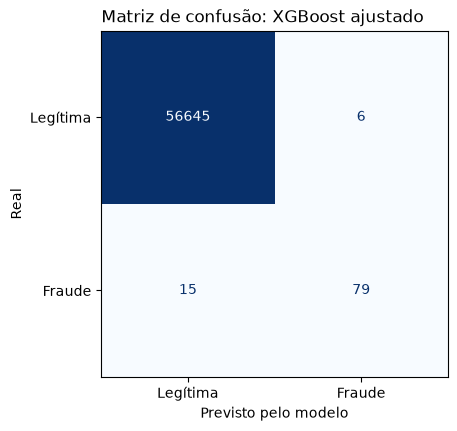

,Precisão,Recall (Sensibilidade),F1-Score,PR-AUC,PR-AUC CV (3 dobras do treino),Falsos Positivos,Falsos Negativos
XGBoost (padrão),0.9302,0.8511,0.8889,0.8913,0.8199,6.0,14.0
XGBoost ajustado,0.9294,0.8404,0.8827,0.8892,0.8410,6.0,15.0


✅ Modelo escolhido pela validação cruzada (mesmas 3 dobras da busca): XGBoost ajustado


In [43]:
modelo_ajustado = melhor_estimador   # do método escolhido no item 7.4
metricas_ajustado, proba_ajustado = relatorio_validacao(f'{melhor_modelo} ajustado', modelo_ajustado, X_train, y_train,
                                                         X_val, y_val, nome_arquivo='Matriz modelo ajustado')
pr_auc_padrao_cv = float(comparacao_busca.loc['Padrão (sem ajuste)', 'PR-AUC CV'])   # mesmas 3 dobras da busca (item 7.4)
usar_ajustado = melhor_score_cv > pr_auc_padrao_cv
modelo_escolhido = modelo_ajustado if usar_ajustado else modelos[melhor_modelo]
proba_escolhido = proba_ajustado if usar_ajustado else probas_validacao[melhor_modelo]
nome_escolhido = f'{melhor_modelo} ajustado' if usar_ajustado else f'{melhor_modelo} (hiperparâmetros padrão)'

display(pd.DataFrame({f'{melhor_modelo} (padrão)': {**metricas_validacao[melhor_modelo], 'PR-AUC CV (3 dobras do treino)': pr_auc_padrao_cv},
                      f'{melhor_modelo} ajustado': {**metricas_ajustado, 'PR-AUC CV (3 dobras do treino)': melhor_score_cv}}).T[
    ['Precisão', 'Recall (Sensibilidade)', 'F1-Score', 'PR-AUC', 'PR-AUC CV (3 dobras do treino)', 'Falsos Positivos',
     'Falsos Negativos']].round(4))
print(f'✅ Modelo escolhido pela validação cruzada (mesmas 3 dobras da busca): {nome_escolhido}')

📌 **Nota: ajustado x padrão**
- 🔎 Na validação, os dois praticamente empatam: PR-AUC de **0,889** (ajustado) x **0,891** (padrão), com 1 fraude a menos no ajustado.
- 🔎 Nas mesmas 3 dobras da busca, o ajustado é melhor: **0,841** x **0,820**.
- 💡 Com 94 fraudes, uma fraude a mais ou a menos na validação é ruído. As 3 dobras usam as 284 fraudes do treino.
- ✅ **Decisão:** usar o **XGBoost ajustado**, escolhido pela validação cruzada.

### 7.6. Modelo final

O modelo final é um **clone** do modelo escolhido no item 7.5, treinado de novo com **treino + validação** (80% da base). O teste é usado aqui pela primeira vez, só para registrar o resultado com o limiar padrão; o limiar final vem da validação (item 8).

In [44]:
modelo_final = clone(modelo_escolhido).fit(X_temp, y_temp)
prob_teste = modelo_final.predict_proba(X_test)[:, 1]
metricas_teste_05 = calcular_metricas_completas(y_test, (prob_teste >= 0.5).astype(int), prob_teste)

metricas_escolhido = metricas_ajustado if usar_ajustado else metricas_validacao[melhor_modelo]
pd.DataFrame({f'Validação ({nome_escolhido})': metricas_escolhido, 'Teste (modelo final, limiar 0,5)': metricas_teste_05}).loc[
    ['Precisão', 'Recall (Sensibilidade)', 'F1-Score', 'AUC-ROC', 'PR-AUC', 'Verdadeiros Positivos', 'Falsos Negativos',
     'Falsos Positivos']].round(3)

,Validação (XGBoost ajustado),"Teste (modelo final, limiar 0,5)"
Precisão,0.929,0.961
Recall (Sensibilidade),0.840,0.768
F1-Score,0.883,0.854
AUC-ROC,0.975,0.975
PR-AUC,0.889,0.817
Verdadeiros Positivos,79.000,73.000
Falsos Negativos,15.000,22.000
Falsos Positivos,6.000,3.000


📌 **Nota: modelo final no teste (limiar de 0,5)**
- 🔎 No teste, aberto pela primeira vez: precisão de **0,961**, recall de **0,768** (**73 de 95** fraudes), F1 de **0,854** e PR-AUC de **0,817**, contra 0,889 na validação.
- 💡 A queda é de 0,07 na PR-AUC. Com só 95 fraudes, poucas fraudes "difíceis" mudam bastante a métrica: a validação cruzada já mostrava desvios de 0,03 a 0,06 entre as dobras.
- 🔎 O AUC-ROC é o mesmo nos dois (**0,975**): o modelo ordena as transações tão bem quanto na validação.

## 8 - Otimização de limiar e calibração

O modelo dá uma **probabilidade**; o limiar decide a partir de qual probabilidade a transação vai para revisão. Tudo aqui usa a **validação** (o modelo escolhido, treinado só no treino); o teste só recebe a regra já escolhida. No item 8.5, testamos uma **regra complementar para transações de valor alto**, onde estão as fraudes mais caras.

### 8.1. O efeito do limiar

In [45]:
valor_val = X_val[COLUNA_VALOR].values
linhas = []
for corte in [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]:
    marcado = proba_escolhido >= corte
    linhas.append({'Limiar': corte, 'Transações revisadas': marcado.sum(), 'Fraudes encontradas': (marcado & (y_val == 1)).sum(),
                   'Alarmes falsos': (marcado & (y_val == 0)).sum(), 'Precisão': precision_score(y_val, marcado, zero_division=0),
                   'Recall': recall_score(y_val, marcado)})
pd.DataFrame(linhas).set_index('Limiar').round(3)

,Transações revisadas,Fraudes encontradas,Alarmes falsos,Precisão,Recall
Limiar,,,,,
0.05,107,83,24,0.776,0.883
0.10,96,82,14,0.854,0.872
0.20,89,80,9,0.899,0.851
0.30,87,80,7,0.920,0.851
0.50,85,79,6,0.929,0.840
0.70,82,78,4,0.951,0.830
0.90,79,77,2,0.975,0.819


### 8.2. Escolhendo o limiar

Três critérios, todos calculados na validação:

| Critério | Como escolhe |
|---|---|
| **F1 máximo** | O melhor equilíbrio entre precisão e recall |
| **Custo mínimo em reais** | Fraude não detectada custa **o valor da transação**; cada transação revisada custa **R$ 5** (premissa do tempo de um analista) |
| **Meta de recall** | O maior limiar que ainda encontra pelo menos **80%** das fraudes |

,Limiar,Precisão,Recall,F1,Revisadas,% do valor barrado,Economia líquida (R$)
"Padrão (0,50)",0.500,0.929,0.840,0.883,85,80.9%,"R$ 7,717"
F1 máximo,0.897,0.975,0.830,0.897,80,80.6%,"R$ 7,712"
Custo mínimo (revisão = R$ 5),0.110,0.871,0.862,0.866,93,83.3%,"R$ 7,916"
Meta de recall (80%),0.921,0.974,0.809,0.884,78,80.6%,"R$ 7,720"


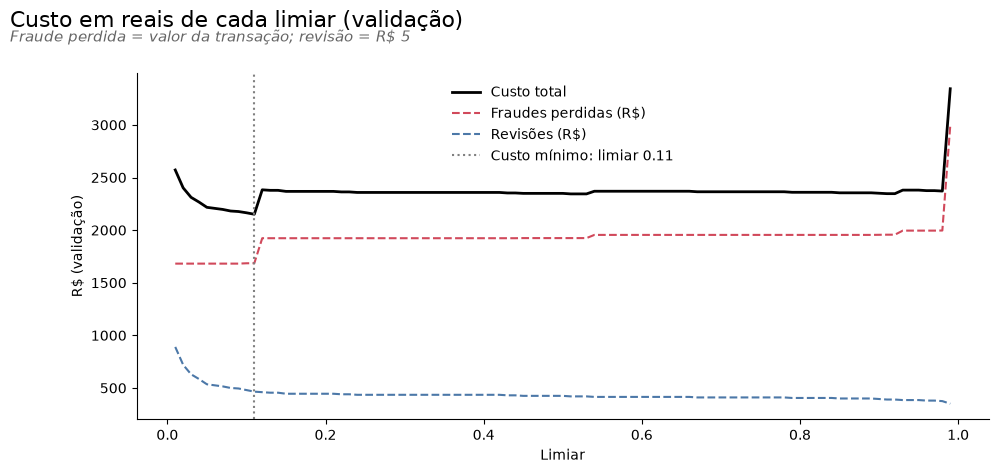

✅ Limiar escolhido (custo mínimo na validação): 0.11


In [46]:
limiar_f1, f1_max = limiar_otimo_f1(y_val, proba_escolhido)
custos = custo_financeiro(y_val, proba_escolhido, valor_val, CUSTO_REVISAO, limiares=np.round(np.arange(0.01, 1.0, 0.01), 2))
limiar_custo = float(custos.loc[custos['Custo total'].idxmin(), 'Limiar'])
precisao_curva, recall_curva, limiares_curva = precision_recall_curve(y_val, proba_escolhido)
limiar_meta = float(limiares_curva[recall_curva[:-1] >= META_RECALL].max())

resumo_limiares = {}
for nome, corte in [('Padrão (0,50)', 0.5), ('F1 máximo', limiar_f1), (f'Custo mínimo (revisão = R$ {CUSTO_REVISAO:.0f})', limiar_custo),
                    (f'Meta de recall ({META_RECALL:.0%})', limiar_meta)]:
    marcado = proba_escolhido >= corte
    financeiro = resumo_financeiro(y_val, marcado, valor_val, CUSTO_REVISAO)
    resumo_limiares[nome] = {'Limiar': corte, 'Precisão': precision_score(y_val, marcado), 'Recall': recall_score(y_val, marcado),
                             'F1': f1_score(y_val, marcado), 'Revisadas': financeiro['Transações revisadas'],
                             '% do valor barrado': financeiro['% do valor barrado'], 'Economia líquida (R$)': financeiro['Economia líquida']}
display(pd.DataFrame(resumo_limiares).T.style.format({'Limiar': '{:.3f}', 'Precisão': '{:.3f}', 'Recall': '{:.3f}', 'F1': '{:.3f}',
                                                      'Revisadas': '{:.0f}', '% do valor barrado': '{:.1%}',
                                                      'Economia líquida (R$)': 'R$ {:,.0f}'}))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(custos['Limiar'], custos['Custo total'], color='black', lw=2, label='Custo total')
ax.plot(custos['Limiar'], custos['Valor das fraudes perdidas'], color=COR_FRAUDE, ls='--', label='Fraudes perdidas (R$)')
ax.plot(custos['Limiar'], custos['Custo das revisões'], color=COR_LEGITIMA, ls='--', label='Revisões (R$)')
ax.axvline(limiar_custo, color='grey', ls=':', label=f'Custo mínimo: limiar {limiar_custo:.2f}')
ax.set(xlabel='Limiar', ylabel='R$ (validação)')
ax.legend(frameon=False)
sns.despine()
titulo('Custo em reais de cada limiar (validação)', f'Fraude perdida = valor da transação; revisão = R$ {CUSTO_REVISAO:.0f}')
salvar('Curva de custo')
plt.show()

limiar = limiar_custo
print(f'✅ Limiar escolhido (custo mínimo na validação): {limiar:.2f}')

📌 **Nota: os três critérios (validação)**

| Critério | Limiar | Precisão | Recall | Revisões | % do valor barrado | Economia líquida |
|---|---|---|---|---|---|---|
| Padrão | 0,50 | 0,929 | 0,840 | 85 | 80,9% | R$ 7.717 |
| F1 máximo | 0,897 | 0,975 | 0,830 | 80 | 80,6% | R$ 7.712 |
| **Custo mínimo** | **0,11** | 0,871 | **0,862** | 93 | **83,3%** | **R$ 7.916** |
| Meta de recall (80%) | 0,921 | 0,974 | 0,809 | 78 | 80,6% | R$ 7.720 |

- 🔎 Baixar o limiar de 0,5 para **0,11** encontra 2 fraudes a mais, com 8 revisões a mais (R$ 40), e a economia líquida sobe **R$ 199**.
- ✅ **Decisão:** usar o limiar de **0,11**, o de menor custo em reais. Para o negócio, o que importa é o dinheiro, e não o F1.

**Sensibilidade à premissa de custo.** O limiar muda muito se a revisão custar outro valor?

In [47]:
sensibilidade = {}
for custo in [1, 2, 5, 10, 20]:
    tabela = custo_financeiro(y_val, proba_escolhido, valor_val, custo, limiares=np.round(np.arange(0.01, 1.0, 0.01), 2))
    melhor = tabela.loc[tabela['Custo total'].idxmin()]
    sensibilidade[f'R$ {custo}'] = {'Limiar de custo mínimo': melhor['Limiar'], 'Fraudes detectadas': melhor['Fraudes detectadas'],
                                    'Alarmes falsos': melhor['Alarmes falsos']}
pd.DataFrame(sensibilidade).T

,Limiar de custo mínimo,Fraudes detectadas,Alarmes falsos
R$ 1,0.11,81.0,12.0
R$ 2,0.11,81.0,12.0
R$ 5,0.11,81.0,12.0
R$ 10,0.11,81.0,12.0
R$ 20,0.98,74.0,1.0


📌 **Nota**
- 🔎 Com a revisão custando de **R$ 1 a R$ 10**, o limiar de custo mínimo continua em **0,11** (81 fraudes e 12 alarmes falsos na validação).
- 🔎 Só com a revisão a **R$ 20** ele salta para **0,98** (74 fraudes e 1 alarme falso).
- ✅ A decisão é **robusta** para custos de revisão de até R$ 10.

### 8.3. Aplicando o limiar escolhido no teste

In [48]:
valor_teste = X_test[COLUNA_VALOR].values

linhas = {}
for nome, corte in [('Limiar padrão (0,50)', 0.5), (f'Limiar escolhido ({limiar:.2f})', limiar)]:
    marcado = (prob_teste >= corte).astype(int)
    financeiro = resumo_financeiro(y_test, marcado, valor_teste, CUSTO_REVISAO)
    linhas[nome] = {'Precisão': precision_score(y_test, marcado), 'Recall': recall_score(y_test, marcado), 'F1': f1_score(y_test, marcado),
                    'Fraudes encontradas': f'{((marcado == 1) & (y_test == 1)).sum()} de {y_test.sum()}',
                    'Alarmes falsos': ((marcado == 1) & (y_test == 0)).sum(), '% do valor barrado': financeiro['% do valor barrado'],
                    'Economia líquida (R$)': financeiro['Economia líquida']}
pd.DataFrame(linhas).T

,Precisão,Recall,F1,Fraudes encontradas,Alarmes falsos,% do valor barrado,Economia líquida (R$)
"Limiar padrão (0,50)",0.960526,0.768421,0.853801,73 de 95,3,0.741872,10574.71
Limiar escolhido (0.11),0.8,0.8,0.8,76 de 95,19,0.743568,10504.76


📌 **Nota: o limiar escolhido no teste**
- 🔎 Com **0,11**, o modelo encontra **76 de 95** fraudes (recall de **0,800**), com **19** alarmes falsos (precisão de **0,800**). Com 0,5, seriam 73 fraudes e 3 alarmes.
- ⚠️ **No teste, a escolha da validação não se confirmou por pouco:** com 0,11, a economia líquida é de **R$ 10.504,76**, contra **R$ 10.574,71** com 0,5 (**R$ 69,95** a menos, 0,7%). As 3 fraudes a mais somavam só R$ 25,05, e as 19 revisões a mais custaram R$ 95.
- ✅ **Decisão:** manter 0,11. Trocar o limiar depois de olhar o teste seria escolher no teste (vazamento), e a diferença está dentro do ruído de ter só 95 fraudes. O que o teste mostra é que, entre 0,11 e 0,5, o resultado em reais é praticamente o mesmo.

### 8.4. Calibração (versão simples)

In [49]:
faixas = pd.cut(prob_teste, bins=[0, 0.001, 0.01, 0.1, 0.5, 0.9, 1.0], include_lowest=True)
calibracao = (pd.DataFrame({'probabilidade': prob_teste, 'real': y_test.values, 'faixa': faixas})
              .groupby('faixa', observed=True).agg(transacoes=('real', 'size'), probabilidade_media=('probabilidade', 'mean'),
                                                   taxa_real_de_fraude=('real', 'mean')))
display(calibracao.style.format({'transacoes': '{:,}', 'probabilidade_media': '{:.4f}', 'taxa_real_de_fraude': '{:.4f}'}))
print(f'Brier score (erro médio das probabilidades; menor é melhor): {brier_score_loss(y_test, prob_teste):.5f}'
      f' | modelo que chuta: {brier_score_loss(y_test, np.full(len(y_test), y_train.mean())):.5f}')

,transacoes,probabilidade_media,taxa_real_de_fraude
faixa,,,
"(-0.001, 0.001]","56,098",0.0000,0.0002
"(0.001, 0.01]",471,0.0028,0.0042
"(0.01, 0.1]",80,0.0275,0.0500
"(0.1, 0.5]",21,0.2497,0.1429
"(0.5, 0.9]",7,0.6391,0.7143
"(0.9, 1.0]",69,0.9968,0.9855


Brier score (erro médio das probabilidades; menor é melhor): 0.00043 | modelo que chuta: 0.00167


📌 **Nota: as probabilidades fazem sentido?**
- 🔎 **56.098** transações do teste (**98,9%**) têm probabilidade de até 0,1%, e a taxa real de fraude nelas é de **0,02%**.
- 🔎 Na faixa de 0,9 a 1,0, há **69** transações, com probabilidade média de **0,997** e taxa real de **0,986**: quando o modelo tem certeza, acerta.
- 🔎 As faixas intermediárias têm poucas transações (de 0,1 a 0,5: só **21**, com média de 0,25 e taxa real de 0,14) e servem só como indicação.
- 🔎 Brier score de **0,00043**, quase **4 vezes** menor que o do modelo que chuta (0,00167).

**Calibração isotônica.** Para comunicar o risco ("esta transação tem 30% de chance de ser fraude"), as probabilidades precisam bater com a frequência real. A calibração isotônica reajusta as probabilidades com validação cruzada (3 dobras em treino + validação), sem mexer na ordem das transações.

In [50]:
calibrado = CalibratedClassifierCV(clone(modelo_escolhido), method='isotonic',
                                   cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMENTE)).fit(X_temp, y_temp)
prob_teste_calibrada = calibrado.predict_proba(X_test)[:, 1]

faixas_cal = pd.cut(prob_teste_calibrada, bins=[0, 0.001, 0.01, 0.1, 0.5, 0.9, 1.0], include_lowest=True)
display(pd.DataFrame({'probabilidade': prob_teste_calibrada, 'real': y_test.values, 'faixa': faixas_cal})
        .groupby('faixa', observed=True).agg(transacoes=('real', 'size'), probabilidade_media=('probabilidade', 'mean'),
                                             taxa_real_de_fraude=('real', 'mean'))
        .style.format({'transacoes': '{:,}', 'probabilidade_media': '{:.4f}', 'taxa_real_de_fraude': '{:.4f}'}))
print(f'Brier score: original {brier_score_loss(y_test, prob_teste):.5f} | calibrado {brier_score_loss(y_test, prob_teste_calibrada):.5f}')
print(f'PR-AUC: original {average_precision_score(y_test, prob_teste):.4f} | calibrado {average_precision_score(y_test, prob_teste_calibrada):.4f}')
del calibrado
_ = gc.collect()

,transacoes,probabilidade_media,taxa_real_de_fraude
faixa,,,
"(-0.001, 0.001]","53,417",0.0001,0.0002
"(0.001, 0.01]","3,156",0.0021,0.0019
"(0.01, 0.1]",83,0.0219,0.0482
"(0.1, 0.5]",18,0.2435,0.3333
"(0.5, 0.9]",8,0.7178,0.8750
"(0.9, 1.0]",64,0.9873,0.9844


Brier score: original 0.00043 | calibrado 0.00043
PR-AUC: original 0.8169 | calibrado 0.8172


📌 **Nota: calibração isotônica**
- 🔎 O Brier score não muda (**0,00043** nos dois) e a PR-AUC quase não muda (**0,8169** → **0,8172**): a ordem das transações é a mesma.
- 🔎 Nas faixas intermediárias, a calibração troca um erro por outro: de 0,1 a 0,5, o modelo original **superestima** o risco (média de 0,25, taxa real de 0,14) e o calibrado **subestima** (média de 0,24, taxa real de 0,33). São só **18 a 21** transações por faixa: é ruído.
- ✅ **Decisão:** manter as probabilidades originais. A calibração não melhora nada mensurável e exige treinar 3 modelos a mais.

### 8.5. Regra complementar para valores altos

As fraudes que escapam com o maior prejuízo são as de **valor alto**. Testamos, na validação, uma regra extra: **revisar também as transações acima de um valor de corte que tenham probabilidade a partir de um limiar mais baixo**. Os dois parâmetros são escolhidos pelo menor custo total, mantendo o limiar principal (0,11).

Comparamos também outra forma de dar peso ao valor: **treinar o modelo com cada fraude pesando pelo seu valor** (`sample_weight`).

In [51]:
linhas_regra = []
for corte_valor in [100, 200, 500, 1000]:
    for limiar_valor in [0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05]:
        regra = {'corte_valor': corte_valor, 'limiar_valor': limiar_valor}
        r = resumo_financeiro(y_val, aplicar_regra(proba_escolhido, valor_val, limiar, regra), valor_val, CUSTO_REVISAO)
        linhas_regra.append({**regra, 'Revisadas': r['Transações revisadas'], '% do valor barrado': r['% do valor barrado'],
                             'Economia líquida': r['Economia líquida']})
grade_regra = pd.DataFrame(linhas_regra).sort_values('Economia líquida', ascending=False)
economia_simples = resumo_financeiro(y_val, aplicar_regra(proba_escolhido, valor_val, limiar), valor_val, CUSTO_REVISAO)['Economia líquida']
melhor_regra = grade_regra.iloc[0]
regra_valor = ({'corte_valor': float(melhor_regra['corte_valor']), 'limiar_valor': float(melhor_regra['limiar_valor'])}
               if melhor_regra['Economia líquida'] > economia_simples else None)
print(f'Economia na validação só com o limiar {limiar:.2f}: R$ {economia_simples:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.'))
display(grade_regra.head(5).style.format({'limiar_valor': '{:.4f}', '% do valor barrado': '{:.1%}', 'Economia líquida': 'R$ {:,.2f}'}))
print(f'✅ Regra complementar adotada: {regra_valor}' if regra_valor else '❌ Nenhuma regra complementar melhorou a validação')

# Alternativa: cada fraude pesa no treino de acordo com o valor
peso = np.where(y_train == 1, 1 + X_train[COLUNA_VALOR] / X_train.loc[y_train == 1, COLUNA_VALOR].mean(), 1)
modelo_peso_valor = clone(modelo_escolhido).fit(X_train, y_train, sample_weight=peso)
proba_peso_valor = modelo_peso_valor.predict_proba(X_val)[:, 1]
custos_peso = custo_financeiro(y_val, proba_peso_valor, valor_val, CUSTO_REVISAO, limiares=np.round(np.arange(0.01, 1.0, 0.01), 2))
melhor_peso = custos_peso.loc[custos_peso['Custo total'].idxmin()]
economia_peso = resumo_financeiro(y_val, proba_peso_valor >= melhor_peso['Limiar'], valor_val, CUSTO_REVISAO)['Economia líquida']
print(f"Peso pelo valor no treino: PR-AUC {average_precision_score(y_val, proba_peso_valor):.4f} (modelo escolhido: "
      f"{average_precision_score(y_val, proba_escolhido):.4f}) | melhor economia R$ {economia_peso:,.2f} com limiar {melhor_peso['Limiar']:.2f}")
del modelo_peso_valor
_ = gc.collect()

Economia na validação só com o limiar 0,11: R$ 7.915,75


,corte_valor,limiar_valor,Revisadas,% do valor barrado,Economia líquida
10,200,0.0050,131,86.4%,"R$ 8,037.66"
3,100,0.0050,144,86.4%,"R$ 7,972.66"
27,1000,0.0500,96,83.3%,"R$ 7,900.75"
20,500,0.0500,97,83.3%,"R$ 7,895.75"
25,1000,0.0100,100,83.3%,"R$ 7,880.75"


✅ Regra complementar adotada: {'corte_valor': 200.0, 'limiar_valor': 0.005}


Peso pelo valor no treino: PR-AUC 0.8830 (modelo escolhido: 0.8892) | melhor economia R$ 7,886.75 com limiar 0.12


📌 **Nota: regra complementar para valores altos (validação)**
- 🔎 Só com o limiar de 0,11, a economia líquida na validação é de **R$ 7.915,75**.
- 🔎 A melhor regra das 28 testadas é **revisar também as transações acima de R$ 200 com probabilidade a partir de 0,5%**: a economia sobe para **R$ 8.037,66** (**+R$ 121,91**), com **131** revisões em vez de 93 e **86,4%** do valor barrado em vez de 83,3%.
- 🔎 **Pesar cada fraude pelo valor no treino** não ajudou: PR-AUC de **0,883** (contra 0,889) e melhor economia de **R$ 7.886,75**, abaixo do limiar simples.
- ⚠️ O ganho na validação é pequeno (cerca de uma fraude) e foi escolhido entre 28 combinações, então pode ser um pouco otimista. O teste, a seguir, é a conferência honesta.
- ✅ **Decisão:** adotar a regra complementar (corte de **R$ 200**, limiar de **0,005**) e descartar o peso pelo valor.

In [52]:
# A regra final (limiar + regra complementar, se adotada) é aplicada ao teste uma única vez
previsto_teste = aplicar_regra(prob_teste, valor_teste, limiar, regra_valor).astype(int)
comparacao_regras_teste = {}
for nome, marcado in [(f'Só o limiar ({limiar:.2f})', aplicar_regra(prob_teste, valor_teste, limiar)),
                      ('Limiar + regra de valor', previsto_teste.astype(bool))]:
    r = resumo_financeiro(y_test, marcado, valor_teste, CUSTO_REVISAO)
    comparacao_regras_teste[nome] = {'Fraudes encontradas': f'{(marcado & (y_test.values == 1)).sum()} de {y_test.sum()}',
                                     'Alarmes falsos': int((marcado & (y_test.values == 0)).sum()), 'Revisadas': r['Transações revisadas'],
                                     '% do valor barrado': f"{r['% do valor barrado']:.1%}", 'Economia líquida (R$)': round(r['Economia líquida'], 2)}
pd.DataFrame(comparacao_regras_teste).T

,Fraudes encontradas,Alarmes falsos,Revisadas,% do valor barrado,Economia líquida (R$)
Só o limiar (0.11),76 de 95,19,95,74.4%,10504.76
Limiar + regra de valor,78 de 95,54,132,82.3%,11494.24


📌 **Nota: a regra final no teste**
- 🔎 A regra de valor encontrou **2 fraudes a mais** (78 contra 76 de 95), que somavam **R$ 1.174,48**, ao custo de **37 revisões a mais** (R$ 185) e **35 alarmes falsos a mais** (54 contra 19).
- 🔎 A economia líquida subiu de **R$ 10.504,76** para **R$ 11.494,24** (**+R$ 989,48**), e o valor barrado, de **74,4%** para **82,3%**.
- 💡 No teste, a regra rendeu mais do que na validação, porque pegou fraudes de valor alto. O bootstrap (Fase 04, item 1.1) mede o quanto esse ganho é confiável.

## 9 - Teste anti-vazamento

Reproduzimos os dois problemas da versão original para medir o quanto eles inflam as métricas:
1. **Avaliar o modelo nos dados em que ele treinou** (a versão original treinou os modelos "ajustados" em treino + validação e mediu na própria validação).
2. **Manter as duplicatas**: quantas transações do teste teriam uma cópia idêntica no treino?

In [53]:
# 1) O modelo final treinou com X_temp (treino + validação). Avaliá-lo na validação é avaliar o que ele já viu.
proba_vazada = modelo_final.predict_proba(X_val)[:, 1]
vazamento = pd.DataFrame({
    'Avaliação honesta (teste)': calcular_metricas_completas(y_test, (prob_teste >= 0.5).astype(int), prob_teste),
    'Avaliação com vazamento (validação já vista)': calcular_metricas_completas(y_val, (proba_vazada >= 0.5).astype(int), proba_vazada),
}).loc[['Precisão', 'Recall (Sensibilidade)', 'F1-Score', 'PR-AUC']]
display(vazamento.round(3))

# 2) Separando a base COM duplicatas do mesmo jeito: quantas linhas do teste têm uma cópia idêntica no treino?
X_bruto, y_bruto = preparar_variaveis(carregar_base(ARQUIVO_BASE))
Xb_temp, Xb_test, yb_temp, yb_test = train_test_split(X_bruto, y_bruto, test_size=0.2, random_state=SEMENTE, stratify=y_bruto)
# Uma linha do teste tem "cópia" no treino se todas as colunas forem iguais (merge pelas 30 colunas)
copias = Xb_test.reset_index().merge(Xb_temp.drop_duplicates(), on=list(Xb_test.columns), how='inner')['index'].unique()
copia_no_treino = Xb_test.index.isin(copias)
print(f'Com duplicatas: {copia_no_treino.sum()} transações do teste ({copia_no_treino.mean():.2%}) têm uma cópia idêntica no treino,'
      f' das quais {yb_test[copia_no_treino].sum()} são fraudes ({yb_test[copia_no_treino].sum() / yb_test.sum():.1%} das fraudes do teste).')
del X_bruto, y_bruto, Xb_temp, Xb_test, yb_temp, yb_test
_ = gc.collect()

,Avaliação honesta (teste),Avaliação com vazamento (validação já vista)
Precisão,0.961,1.0
Recall (Sensibilidade),0.768,1.0
F1-Score,0.854,1.0
PR-AUC,0.817,1.0


Com duplicatas: 344 transações do teste (0.60%) têm uma cópia idêntica no treino, das quais 8 são fraudes (8.2% das fraudes do teste).


📌 **Nota**
- 🔎 **Avaliando nos dados que o modelo já viu** (a validação, que entrou no treino do modelo final), precisão, recall, F1 e PR-AUC dão **1,000**: é exatamente o "LightGBM com 100% em tudo" da versão original. A avaliação honesta, no teste, dá F1 de **0,854** e PR-AUC de **0,817**.
- 🔎 **Mantendo as duplicatas**, **344** transações do teste (**0,60%**) teriam uma cópia idêntica no treino, **8** delas fraudes (**8,2%** das fraudes do teste). O modelo "reconheceria" essas fraudes em vez de detectá-las.

### 🛡️ Resumo: houve vazamento? Foi resolvido?

- ✅ **Havia vazamento na versão original?** Sim, de dois tipos: os modelos "ajustados" foram avaliados nos próprios dados de treino (100% em tudo) e as duplicatas podiam cair nos dois lados da separação.
- ✅ **Foi resolvido?** Sim. As duplicatas são removidas antes da separação; o modelo e o limiar são escolhidos na validação e na validação cruzada; o teste é usado uma única vez; e o `Timestamp` cru foi trocado pela hora do dia.
- ⚠️ **O que não dá para resolver:** o PCA das componentes foi feito pelo banco com a base inteira, incluindo as transações que usamos como teste. É um vazamento pequeno, mas fora do nosso controle.

# FASE 04: AVALIAÇÃO

## 1 - Avaliando a Máquina Preditiva

,Acurácia,Precisão,Recall (Sensibilidade),F1-Score,AUC-ROC,PR-AUC,Especificidade,Valor Preditivo Negativo,Verdadeiros Positivos,Verdadeiros Negativos,Falsos Positivos,Falsos Negativos
"Teste (limiar 0.11 + regra de valor (≥ R$ 200, prob. ≥ 0.005))",0.9987,0.5909,0.8211,0.6872,0.9753,0.8169,0.999,0.9997,78.0,56597.0,54.0,17.0


              precision    recall  f1-score   support

Legítima (0)     0.9997    0.9990    0.9994     56651
  Fraude (1)     0.5909    0.8211    0.6872        95

    accuracy                         0.9987     56746
   macro avg     0.7953    0.9100    0.8433     56746
weighted avg     0.9990    0.9987    0.9989     56746



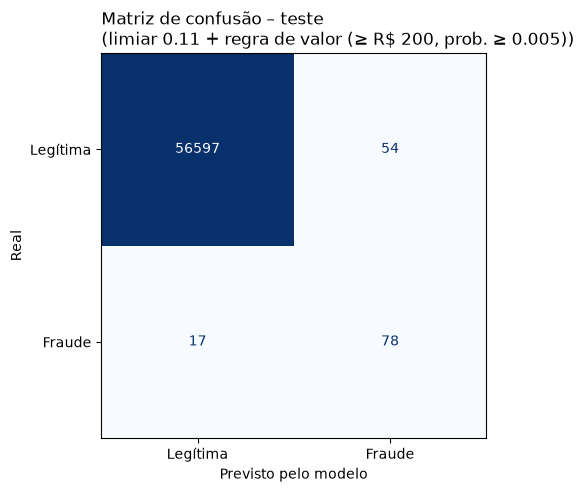

,Valor total das fraudes,Valor das fraudes barradas,% do valor barrado,Custo das revisões,Economia líquida,Transações revisadas
"Teste, em reais","R$ 14,766.31","R$ 12,154.24",82.3%,R$ 660.00,"R$ 11,494.24",132.000000


In [54]:
regra_texto = f'limiar {limiar:.2f}' + (f" + regra de valor (≥ R$ {regra_valor['corte_valor']:.0f}, prob. ≥ {regra_valor['limiar_valor']:.3f})"
                                       if regra_valor else '')
metricas_teste = calcular_metricas_completas(y_test, previsto_teste, prob_teste)
display(pd.Series(metricas_teste).to_frame(f'Teste ({regra_texto})').T.round(4))
print(classification_report(y_test, previsto_teste, target_names=ROTULOS, digits=4))

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, previsto_teste, display_labels=['Legítima', 'Fraude'], cmap='Blues',
                                        colorbar=False, ax=ax)
ax.set(xlabel='Previsto pelo modelo', ylabel='Real')
plt.title(f'Matriz de confusão – teste\n({regra_texto})', fontsize=12, loc='left')
salvar('Matriz de confusao teste')
plt.show()

financeiro_teste = resumo_financeiro(y_test, previsto_teste, valor_teste, CUSTO_REVISAO)
pd.Series(financeiro_teste).to_frame('Teste, em reais').T.style.format('R$ {:,.2f}', subset=['Valor total das fraudes', 'Valor das fraudes barradas',
                                                                                           'Custo das revisões', 'Economia líquida']) \
    .format('{:.1%}', subset=['% do valor barrado'])

📌 **Nota: o resultado no teste (regra final: limiar de 0,11 + regra de valor)**
- 🔎 O modelo encontrou **78 das 95** fraudes (recall de **82,1%**). Das transações que mandou revisar, **59,1%** eram fraudes; os **54** alarmes falsos são **0,1%** das 56.651 legítimas.
- 🔎 **Em reais:** as fraudes do teste somam **R$ 14.766,31**. O modelo barrou **R$ 12.154,24** (**82,3%**) com **132 revisões** (R$ 660), uma economia líquida de **R$ 11.494,24**.
- 🔎 PR-AUC de **0,817** e AUC-ROC de **0,975** (não dependem da regra).

| | Versão original (teste) | v2 com limiar 0,5 | **v2 com a regra final** |
|---|---|---|---|
| Precisão | 95,06% | 96,05% | **59,09%** |
| Recall | 78,57% | 76,84% | **82,11%** |
| F1 | 86,03% | 85,38% | **68,72%** |

- 💡 No limiar de 0,5, a v2 fica no mesmo nível da versão original, que era honesta no teste final (só as duplicatas poderiam ajudá-la). A regra final escolhe outro ponto da curva: o F1 cai, mas são mais fraudes e mais dinheiro barrado em troca de revisões baratas. O critério é o custo em reais, não o F1.

#### Curvas ROC e Precision-Recall

As duas curvas mostram o modelo em **todos os limiares** de uma vez, no teste. A **ROC** cruza o recall com a taxa de falsos positivos (a fração das legítimas que vai para revisão); a **Precision-Recall** cruza o recall com a precisão. Os pontos marcam as regras do item 8.

Limiar 0,11  recall 0.800 | precisão 0.800 | legítimas revisadas 0.034% (19 de 56,651)
Regra final  recall 0.821 | precisão 0.591 | legítimas revisadas 0.095% (54 de 56,651)
Limiar 0,50  recall 0.768 | precisão 0.961 | legítimas revisadas 0.005% (3 de 56,651)


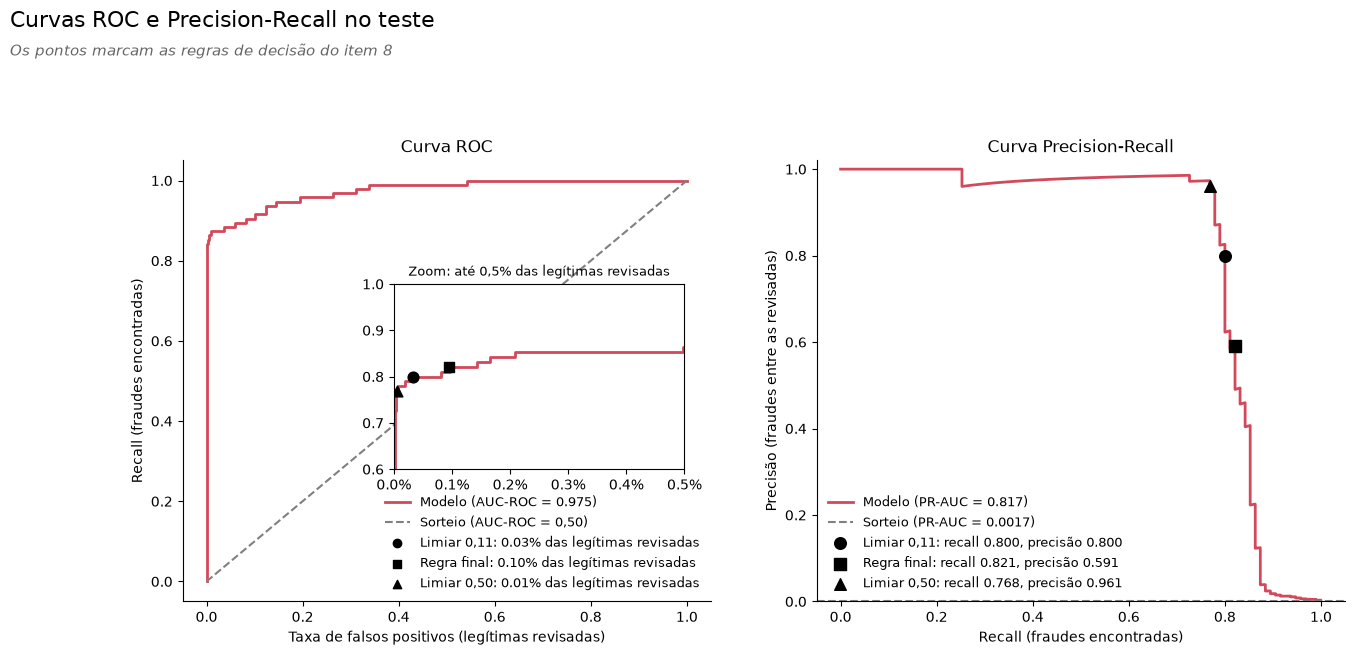

In [55]:
fpr, tpr, _ = roc_curve(y_test, prob_teste)
precisao_teste, recall_teste, _ = precision_recall_curve(y_test, prob_teste)
real_teste = y_test.values == 1
pontos_regras = {f'Limiar {limiar:.2f}'.replace('.', ','): prob_teste >= limiar, 'Regra final': previsto_teste.astype(bool),
                 'Limiar 0,50': prob_teste >= 0.5}

fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
axs[0].plot(fpr, tpr, color=COR_FRAUDE, lw=2, label=f"Modelo (AUC-ROC = {metricas_teste['AUC-ROC']:.3f})")
axs[0].plot([0, 1], [0, 1], color='grey', ls='--', label='Sorteio (AUC-ROC = 0,50)')
zoom = axs[0].inset_axes([0.4, 0.3, 0.55, 0.42])
zoom.plot(fpr, tpr, color=COR_FRAUDE, lw=2)
zoom.set(xlim=(0, 0.005), ylim=(0.6, 1.0))
zoom.set_title('Zoom: até 0,5% das legítimas revisadas', fontsize=9)
zoom.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
axs[1].plot(recall_teste, precisao_teste, color=COR_FRAUDE, lw=2, label=f"Modelo (PR-AUC = {metricas_teste['PR-AUC']:.3f})")
axs[1].axhline(y_test.mean(), color='grey', ls='--', label=f'Sorteio (PR-AUC = {y_test.mean():.4f})')
for (nome, marcado), marcador in zip(pontos_regras.items(), ['o', 's', '^']):
    vp, fp = (marcado & real_teste).sum(), (marcado & ~real_teste).sum()
    taxa_fp, recall_ponto, precisao_ponto = fp / (~real_teste).sum(), vp / real_teste.sum(), vp / marcado.sum()
    zoom.scatter(taxa_fp, recall_ponto, marker=marcador, s=60, color='black', zorder=3)
    axs[0].scatter([], [], marker=marcador, color='black', label=f'{nome}: {taxa_fp:.2%} das legítimas revisadas')
    axs[1].scatter(recall_ponto, precisao_ponto, marker=marcador, s=70, color='black', zorder=3,
                   label=f'{nome}: recall {recall_ponto:.3f}, precisão {precisao_ponto:.3f}')
    print(f'{nome:12s} recall {recall_ponto:.3f} | precisão {precisao_ponto:.3f} | legítimas revisadas {taxa_fp:.3%} ({fp} de {(~real_teste).sum():,})')
axs[0].set(xlabel='Taxa de falsos positivos (legítimas revisadas)', ylabel='Recall (fraudes encontradas)', title='Curva ROC')
axs[0].legend(frameon=False, fontsize=9, loc='lower right')
axs[1].set(xlabel='Recall (fraudes encontradas)', ylabel='Precisão (fraudes entre as revisadas)', title='Curva Precision-Recall',
           ylim=(0, 1.02))
axs[1].legend(frameon=False, fontsize=9, loc='lower left')
sns.despine()
titulo('Curvas ROC e Precision-Recall no teste', 'Os pontos marcam as regras de decisão do item 8')
fig.subplots_adjust(top=0.85 - 0.4 / fig.get_figheight())
salvar('Curvas ROC e PR')
plt.show()

📌 **Nota**
- 🔎 **A ROC parece quase perfeita** (AUC-ROC de **0,975**) porque o eixo x é a fração das **56.651 legítimas**. Até a regra final, que manda 54 legítimas para revisão, fica em **0,095%** delas, colada no eixo. O zoom mostra que toda a decisão acontece em menos de 0,1% das legítimas.
- 🔎 **A Precision-Recall mostra o preço de cada fraude a mais.**
  - Com o limiar de 0,50: recall de **0,768** e precisão de **0,961**.
  - Com 0,11: **0,800** e **0,800**.
  - A regra final chega a **0,821** de recall, com precisão de **0,591**.
  - No fim da curva, a precisão cai para perto de zero: as últimas fraudes só apareceriam revisando milhares de transações (são as 13 com probabilidade de até 0,1% do item 2).
- 💡 Com 0,17% de fraudes, a ROC esconde a dificuldade e a PR mostra. Por isso, a PR-AUC é a métrica principal: o sorteio dá **0,0017** na PR-AUC, contra 0,50 no AUC-ROC.

### 1.1. Quão certos são esses números? (bootstrap)

Com só 95 fraudes no teste, poucos casos mudam muito as métricas. O **bootstrap estratificado** sorteia, com reposição, 1.000 versões do teste (com as mesmas quantidades de fraudes e legítimas) e recalcula o resultado de cada regra. As regras usam as mesmas amostras, então a diferença entre elas é medida amostra a amostra.

In [56]:
decisoes_teste = {'Regra final': previsto_teste.astype(bool), 'Limiar 0,50': prob_teste >= 0.5}
amostras_bootstrap = bootstrap_decisoes(y_test, valor_teste, decisoes_teste, CUSTO_REVISAO, n=1000, semente=SEMENTE)

intervalos = (amostras_bootstrap.groupby('regra')[['Recall', 'Precisão', '% do valor barrado', 'Economia líquida']]
              .quantile([0.025, 0.5, 0.975]).unstack().T)
display(intervalos.style.format('{:.3f}'))

diferenca = (amostras_bootstrap.pivot(index='amostra', columns='regra', values='Economia líquida')
             .eval('`Regra final` - `Limiar 0,50`'))
print(f'Economia líquida, regra final - limiar 0,50: mediana R$ {diferenca.median():,.2f} | '
      f'IC 95% de R$ {diferenca.quantile(0.025):,.2f} a R$ {diferenca.quantile(0.975):,.2f} | '
      f'regra final melhor em {(diferenca > 0).mean():.0%} das amostras')

rng = np.random.default_rng(SEMENTE)
fraudes_idx, legitimas_idx = np.flatnonzero(y_test.values == 1), np.flatnonzero(y_test.values == 0)
pr_auc_boot = []
for _ in range(1000):
    idx = np.concatenate([rng.choice(fraudes_idx, len(fraudes_idx)), rng.choice(legitimas_idx, len(legitimas_idx))])
    pr_auc_boot.append(average_precision_score(y_test.values[idx], prob_teste[idx]))
print(f'PR-AUC no teste: {average_precision_score(y_test, prob_teste):.3f} | IC 95% de {np.quantile(pr_auc_boot, 0.025):.3f} a {np.quantile(pr_auc_boot, 0.975):.3f}')

Economia líquida, regra final - limiar 0,50: mediana R$ 881.27 | IC 95% de R$ -276.24 a R$ 2,647.33 | regra final melhor em 88% das amostras


PR-AUC no teste: 0.817 | IC 95% de 0.736 a 0.889


📌 **Nota: intervalos de confiança (1.000 amostras do teste)**

| Regra | Recall | Precisão | % do valor barrado | Economia líquida |
|---|---|---|---|---|
| **Regra final** | 0,821 (0,747 a 0,895) | 0,592 (0,531 a 0,670) | 83,0% (64,0% a 97,5%) | **R$ 11.358** (R$ 6.255 a R$ 17.940) |
| Limiar 0,50 | 0,768 (0,684 a 0,853) | 0,961 (0,917 a 1,000) | 74,7% (54,4% a 91,8%) | R$ 10.533 (R$ 5.413 a R$ 17.057) |

- 🔎 A regra final economiza mais que o limiar de 0,5 em **88%** das amostras (mediana de **+R$ 881**), mas o intervalo de 95% da diferença vai de **−R$ 276 a +R$ 2.647**: a vantagem é provável, mas não garantida.
- 🔎 A PR-AUC no teste é de **0,817**, com intervalo de **0,736 a 0,889**: a PR-AUC de 0,889 da validação está no limite do intervalo.
- 💡 O intervalo da economia é largo porque **poucas fraudes grandes** decidem o resultado: pegar ou perder uma fraude de R$ 1.000 muda tudo.

### 1.2. Validação temporal

Em produção, o modelo prevê transações **futuras**. Simulamos isso: o mesmo modelo (mesmos hiperparâmetros) é treinado com as **primeiras 36 horas** e avaliado nas **últimas 12 horas**, com a mesma regra de decisão. Nada é escolhido aqui: é só uma conferência.

In [57]:
horas_desde_inicio = df.loc[X.index, 'Timestamp'] / 3600
passado, futuro = horas_desde_inicio < 36, horas_desde_inicio >= 36
modelo_temporal = clone(modelo_escolhido).fit(X[passado], y[passado])
prob_futuro = modelo_temporal.predict_proba(X[futuro])[:, 1]
decisao_futuro = aplicar_regra(prob_futuro, X.loc[futuro, COLUNA_VALOR], limiar, regra_valor)
r_futuro = resumo_financeiro(y[futuro], decisao_futuro, X.loc[futuro, COLUNA_VALOR], CUSTO_REVISAO)
del modelo_temporal
_ = gc.collect()

pd.DataFrame({
    'Separação aleatória (teste)': {'Transações': len(y_test), 'Fraudes': int(y_test.sum()),
                                    'PR-AUC': average_precision_score(y_test, prob_teste),
                                    'Recall': recall_score(y_test, previsto_teste), 'Precisão': precision_score(y_test, previsto_teste),
                                    '% do valor barrado': resumo_financeiro(y_test, previsto_teste, valor_teste, CUSTO_REVISAO)['% do valor barrado']},
    'Temporal (últimas 12 h)': {'Transações': int(futuro.sum()), 'Fraudes': int(y[futuro].sum()),
                                'PR-AUC': average_precision_score(y[futuro], prob_futuro),
                                'Recall': recall_score(y[futuro], decisao_futuro), 'Precisão': precision_score(y[futuro], decisao_futuro),
                                '% do valor barrado': r_futuro['% do valor barrado']},
}).round(3)

,Separação aleatória (teste),Temporal (últimas 12 h)
Transações,56746.000,92198.000
Fraudes,95.000,114.000
PR-AUC,0.817,0.798
Recall,0.821,0.798
Precisão,0.591,0.268
% do valor barrado,0.823,0.794


📌 **Nota: validação temporal (treino nas primeiras 36 h, avaliação nas últimas 12 h)**
- 🔎 A capacidade de ordenar se mantém: PR-AUC de **0,798** (contra 0,817 no teste, dentro do intervalo do bootstrap), recall de **0,798** e **79,4%** do valor barrado.
- ⚠️ **A precisão cai de 0,591 para 0,268:** para encontrar 91 das 114 fraudes, a regra marcou cerca de **340** transações, com uns **250 alarmes falsos** (quase 3 por fraude).
- 💡 Em produção, a fila de revisão pode ser **mais que o dobro** do que o teste aleatório sugere. Parte da explicação pode estar na deriva de `lim_crt` entre os dias (Fase 05, monitoramento), e o modelo temporal também treinou com menos dados.
- ✅ **Decisão:** manter a regra, mas dimensionar a equipe de revisão com folga e acompanhar a precisão nas primeiras semanas.

## 2 - Previsto x observado

In [58]:
resultado_teste = pd.DataFrame({'valor (R$)': valor_teste, 'hora_do_dia': X_test['hora_do_dia'].round(1).values,
                                'real': y_test.values, 'previsto': previsto_teste, 'probabilidade': prob_teste.round(4)},
                               index=X_test.index)
print('✅ Fraudes encontradas (maiores probabilidades):')
display(resultado_teste.query('real == 1 and previsto == 1').sort_values('probabilidade', ascending=False).head(3))
print('❌ Fraudes que passaram (o modelo não viu):')
display(resultado_teste.query('real == 1 and previsto == 0').sort_values('probabilidade'))
print('⚠️ Alarmes falsos (legítimas marcadas):')
display(resultado_teste.query('real == 0 and previsto == 1').sort_values('probabilidade', ascending=False).head(5))

✅ Fraudes encontradas (maiores probabilidades):


,valor (R$),hora_do_dia,real,previsto,probabilidade
41828,112.33,11.4,1,1,1.0
151216,33.59,2.7,1,1,1.0
18710,0.68,8.3,1,1,1.0


❌ Fraudes que passaram (o modelo não viu):


,valor (R$),hora_do_dia,real,previsto,probabilidade
68371,1.18,14.7,1,0,0.0000
72475,1.79,15.2,1,0,0.0000
58516,1.00,13.5,1,0,0.0000
52289,105.99,12.6,1,0,0.0000
100242,549.06,18.8,1,0,0.0000
273358,0.00,22.1,1,0,0.0000
130779,0.20,22.1,1,0,0.0000
56464,0.76,13.2,1,0,0.0000
153692,0.92,4.1,1,0,0.0000
101128,320.00,18.8,1,0,0.0000


⚠️ Alarmes falsos (legítimas marcadas):


,valor (R$),hora_do_dia,real,previsto,probabilidade
119616,109.90,21.0,0,1,0.9999
273745,25691.16,22.2,0,1,0.7070
74524,33.49,15.5,0,1,0.5113
172172,10.61,9.7,0,1,0.4854
148340,0.77,1.1,0,1,0.4240


In [59]:
# Tradução do erro por grupo: o modelo acerta igual em fraudes pequenas e grandes? De dia e de madrugada?
resultado_teste['faixa de valor'] = pd.cut(resultado_teste['valor (R$)'], bins=[-0.01, 0, 10, 100, 500, np.inf],
                                           labels=['R$ 0', 'até R$ 10', 'R$ 10 a 100', 'R$ 100 a 500', 'acima de R$ 500'])
resultado_teste['período'] = np.where(resultado_teste['hora_do_dia'] < 6, 'Madrugada (0–6 h)', 'Resto do dia')

def por_grupo(coluna):
    fraudes = resultado_teste.query('real == 1')
    tabela = fraudes.groupby(coluna, observed=True).agg(fraudes=('real', 'size'), encontradas=('previsto', 'sum'),
                                                       valor_total=('valor (R$)', 'sum'))
    tabela['recall'] = tabela['encontradas'] / tabela['fraudes']
    tabela['valor perdido (R$)'] = fraudes.query('previsto == 0').groupby(coluna, observed=True)['valor (R$)'].sum() \
        .reindex(tabela.index, fill_value=0)
    tabela['alarmes falsos'] = resultado_teste.query('real == 0 and previsto == 1').groupby(coluna, observed=True).size() \
        .reindex(tabela.index, fill_value=0)
    return tabela

display(por_grupo('faixa de valor').style.format({'recall': '{:.0%}', 'valor_total': 'R$ {:,.2f}', 'valor perdido (R$)': 'R$ {:,.2f}'}))
display(por_grupo('período').style.format({'recall': '{:.0%}', 'valor_total': 'R$ {:,.2f}', 'valor perdido (R$)': 'R$ {:,.2f}'}))

,fraudes,encontradas,valor_total,recall,valor perdido (R$),alarmes falsos
faixa de valor,,,,,,
R$ 0,7,6,R$ 0.00,86%,R$ 0.00,1
até R$ 10,40,29,R$ 65.96,72%,R$ 20.13,9
R$ 10 a 100,22,22,"R$ 1,313.43",100%,R$ 0.00,4
R$ 100 a 500,14,12,"R$ 3,041.93",86%,R$ 425.99,25
acima de R$ 500,12,9,"R$ 10,344.99",75%,"R$ 2,165.95",15


,fraudes,encontradas,valor_total,recall,valor perdido (R$),alarmes falsos
período,,,,,,
Madrugada (0–6 h),27,26,"R$ 3,663.70",96%,R$ 0.92,9
Resto do dia,68,52,"R$ 11,102.61",76%,"R$ 2,611.15",45


📌 **Nota: onde o modelo erra**
- 🔎 **17 fraudes passaram.** **13** delas tiveram probabilidade de até 0,1%: nas componentes, elas são indistinguíveis de transações legítimas, e nenhum limiar razoável as pegaria.
- 🔎 **Por valor:** o recall é de **100%** nas fraudes de R$ 10 a R$ 100, **86%** nas de R$ 0 e nas de R$ 100 a R$ 500, **72%** nas de até R$ 10 e **75%** nas acima de R$ 500. Dos **R$ 2.612,07** que passaram, **R$ 2.165,95** (83%) vieram de só **3** fraudes acima de R$ 500, todas com probabilidade de até 0,1% (abaixo até da regra de valor, que começa em 0,5%).
- 🔎 **Por horário:** o recall é de **96%** na madrugada e de **76%** no resto do dia (H2).
- 🔎 **Alarmes falsos:** **40 dos 54** são transações acima de R$ 100, o efeito esperado da regra de valor. Um deles é a maior transação da base (**R$ 25.691,16**, com probabilidade de 0,71): revisar uma transação desse tamanho é sensato mesmo que seja legítima.
- 💡 As fraudes grandes que ainda escapam são invisíveis para as componentes. Pegá-las exige informação nova (histórico do cliente, dispositivo), não outro limiar.

## 3 - Quais variáveis mais influenciam o modelo?

Importância por permutação calculada em 98s


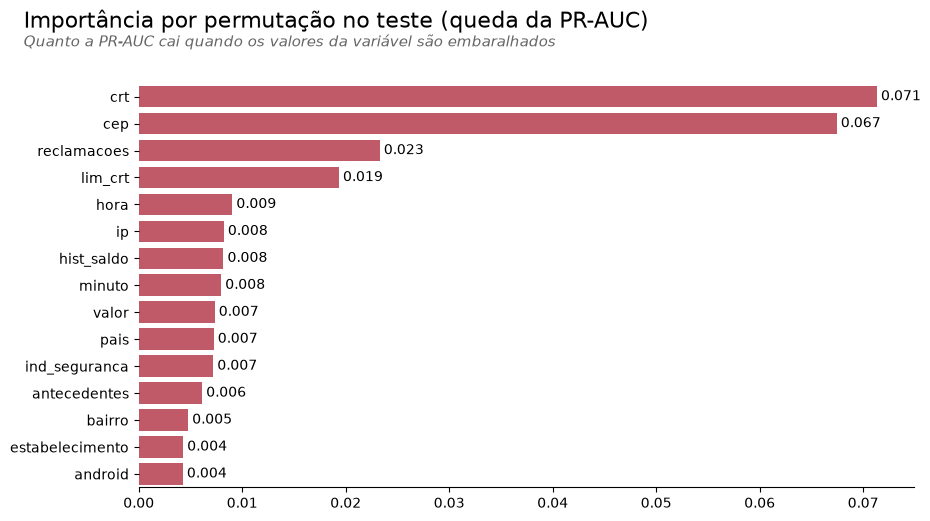

Variáveis cuja remoção não muda nada (queda < 0,001): 5 de 30


In [60]:
t0 = time.time()
importancia_perm = permutation_importance(modelo_final, X_test, y_test, scoring='average_precision', n_repeats=5,
                                          random_state=SEMENTE)
importancia_teste = pd.Series(importancia_perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(f'Importância por permutação calculada em {time.time() - t0:.0f}s')
plot_barras(importancia_teste.head(15), 'Importância por permutação no teste (queda da PR-AUC)', 'Importancia por permutacao',
            horizontal=True, cor=COR_FRAUDE, formato='{:.3f}',
            subtitulo='Quanto a PR-AUC cai quando os valores da variável são embaralhados')
print(f"Variáveis cuja remoção não muda nada (queda < 0,001): {(importancia_teste < 0.001).sum()} de {len(importancia_teste)}")

📌 **Nota**
- 🔎 Duas componentes dominam o modelo: embaralhar `crt` (V14) derruba a PR-AUC em **0,071**, e `cep` (V4) em **0,067**. Depois vêm `reclamacoes` (V12, 0,023) e `lim_crt` (V28, 0,019).
- 🔎 O valor da transação (`hist_saldo`) tem importância pequena (**0,008**), e a `hora_do_dia` fica fora das 15 primeiras: as componentes já carregam a maior parte da informação. **5** variáveis não mudam nada quando embaralhadas.
- ⚠️ Cuidado com os nomes: `hora` e `minuto` são as componentes V7 e V8, e não o horário da transação.

#### SHAP: explicando cada decisão

A importância por permutação mostra o que importa **em média**. Para o analista, a pergunta é outra: **por que esta transação foi marcada?** Os valores **SHAP** dividem o score de cada transação entre as variáveis: positivo empurra para "fraude", negativo para "legítima". O próprio XGBoost os calcula (`pred_contribs`), com o mesmo algoritmo do `TreeExplainer` da biblioteca `shap`.

Os valores SHAP têm uma propriedade que dá para conferir, a **eficiência**: **valor base + soma das contribuições = score do modelo** para cada transação. Num classificador, a escala é a de **log-odds** (o score antes de virar probabilidade), e não a da probabilidade.

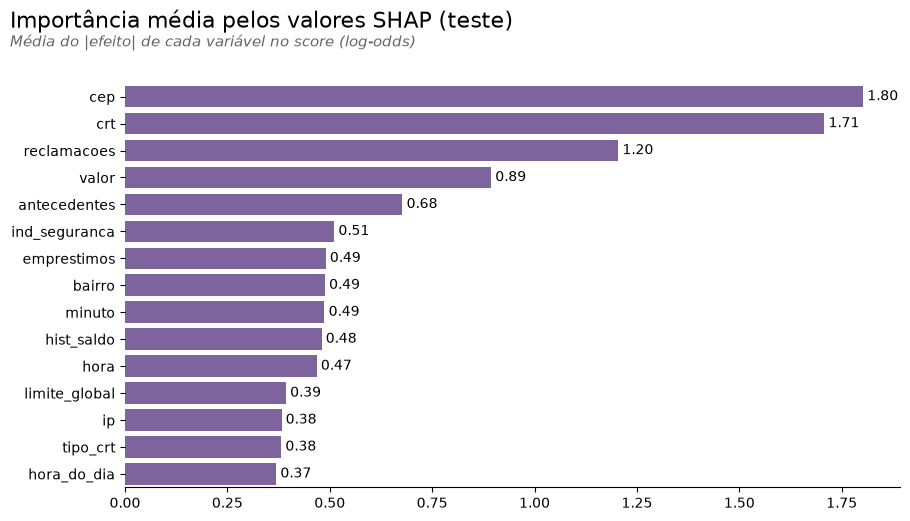

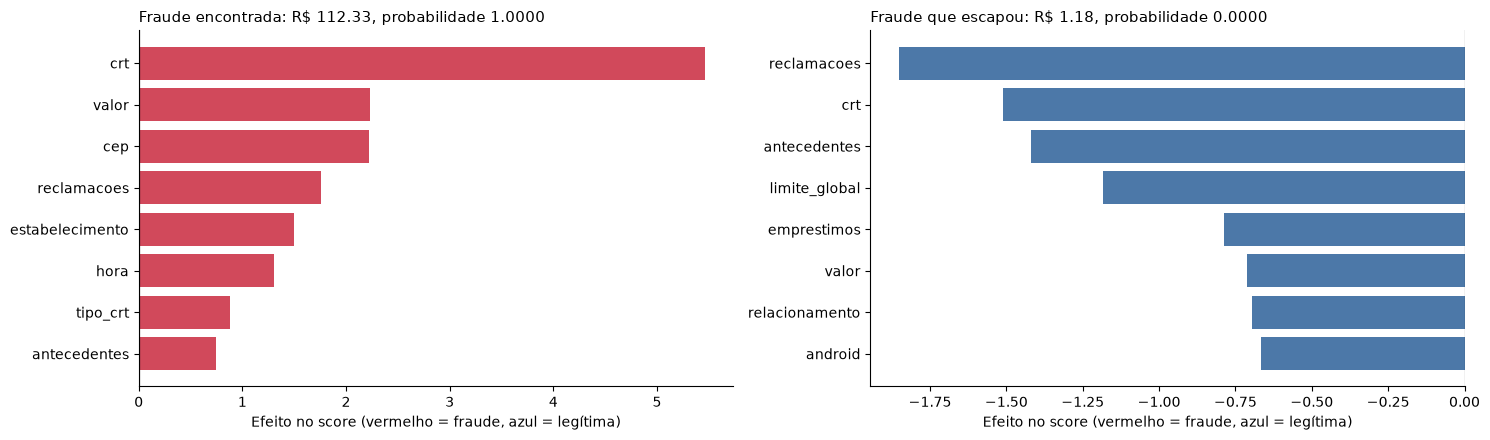

Correlação de postos entre o ranking SHAP e o da permutação: 0.63


Conferência da eficiência (valor base + soma das contribuições = score): diferença máxima de 3.2e-05 nas 56.746 transações do teste
Valor base: -2.51 em log-odds, ou probabilidade de 0.0751


In [61]:
contribuicoes = contribuicoes_xgboost(modelo_final, X_test)
shap_medio = contribuicoes.drop(columns='base').abs().mean().sort_values(ascending=False)
plot_barras(shap_medio.head(15), 'Importância média pelos valores SHAP (teste)', 'Importancia SHAP', horizontal=True,
            cor='#7D5BA6', formato='{:.2f}', subtitulo='Média do |efeito| de cada variável no score (log-odds)')

exemplos = {'Fraude encontrada': resultado_teste.query('real == 1 and previsto == 1')['probabilidade'].idxmax(),
            'Fraude que escapou': resultado_teste.query('real == 1 and previsto == 0')['probabilidade'].idxmin()}
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (nome, indice) in zip(axs, exemplos.items()):
    efeito = contribuicoes.loc[indice].drop('base')
    efeito = efeito.reindex(efeito.abs().sort_values(ascending=False).index[:8])[::-1]
    ax.barh(efeito.index, efeito.values, color=[COR_FRAUDE if v > 0 else COR_LEGITIMA for v in efeito.values])
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f"{nome}: R$ {resultado_teste.loc[indice, 'valor (R$)']:.2f}, probabilidade {resultado_teste.loc[indice, 'probabilidade']:.4f}",
                 fontsize=11, loc='left')
    ax.set_xlabel('Efeito no score (vermelho = fraude, azul = legítima)')
    sns.despine(ax=ax)
plt.tight_layout()
salvar('Explicacao SHAP de transacoes')
plt.show()
print(f"Correlação de postos entre o ranking SHAP e o da permutação: {pd.concat([shap_medio, importancia_teste], axis=1).corr(method='spearman').iloc[0, 1]:.2f}")
margem_teste = modelo_final.predict(X_test, output_margin=True)   # score do modelo em log-odds
diferenca_eficiencia = np.abs(contribuicoes.sum(axis=1).values - margem_teste).max()
valor_base = contribuicoes['base'].iloc[0]
print(f'Conferência da eficiência (valor base + soma das contribuições = score): diferença máxima de {diferenca_eficiencia:.1e} '
      f'nas {len(X_test):,} transações do teste'.replace(',', '.'))
print(f'Valor base: {valor_base:.2f} em log-odds, ou probabilidade de {1 / (1 + np.exp(-valor_base)):.4f}')

📌 **Nota: valores SHAP**
- 🔎 As três variáveis de maior efeito médio são as mesmas da permutação: `cep` (**1,80**), `crt` (**1,71**) e `reclamacoes` (**1,20**). A correlação de postos entre os dois rankings é de **0,63**.
- 🔎 `lim_crt` é a 4ª na permutação, mas fica fora das 15 primeiras no SHAP: pesa pouco na maioria das transações, mas decide em poucas, justamente as fraudes. Já `valor` (V10) é a 4ª no SHAP (0,89).
- 🔎 **Fraude encontrada** (R$ 112,33, probabilidade de 1,00): `crt` empurra o score para "fraude" com força (cerca de +5,5), seguida de `valor` e `cep` (cerca de +2,2 cada).
- 🔎 **Fraude que escapou** (R$ 1,18, probabilidade de 0,0000): as 8 variáveis de maior efeito empurram para "legítima", lideradas por `reclamacoes` (−1,85), `crt` (−1,5) e `antecedentes` (−1,4). Nas componentes, ela parece uma transação comum.
- 🔎 **Eficiência conferida:** valor base + soma das contribuições = score do modelo nas **56.746** transações do teste (diferença máxima de **3,2 × 10⁻⁵**, só arredondamento). O valor base é **−2,51** em log-odds (probabilidade de **0,075**), bem acima da taxa real de fraude (0,17%), porque o peso da classe no treino desloca o score para cima.
- 💡 No app, o analista vê esse gráfico para cada transação analisada.

# FASE 05: IMPLANTAÇÃO

## 1 - Salvando o modelo

In [62]:
PASTA_MODELO.mkdir(exist_ok=True)
joblib.dump({'pipeline': modelo_final, 'limiar': float(limiar), 'regra_valor': regra_valor, 'colunas': list(X.columns)},
            PASTA_MODELO / 'modelo_fraude.pkl')

# Arquivos usados pelo app: probabilidades do teste (para testar limiares) e uma amostra de transações para análise
pd.DataFrame({'real': y_test.values, 'probabilidade': prob_teste, 'valor': valor_teste}).to_csv(
    PASTA_REPORTS / 'previsoes_teste.csv', index=False)
amostra = pd.concat([X_test[y_test == 1].sample(15, random_state=SEMENTE), X_test[y_test == 0].sample(35, random_state=SEMENTE)])
amostra.assign(Target=y_test.loc[amostra.index]).sample(frac=1, random_state=SEMENTE).round(6).to_csv(
    PASTA_REPORTS / 'amostra_transacoes.csv', index_label='id')

ficha = salvar_ficha_modelo(
    PASTA_MODELO / 'modelo_fraude.json',
    modelo=f'{nome_escolhido}, com peso da classe',
    arquivo='modelo_fraude.pkl',
    treinado_com=f"{len(X_temp):,}".replace(',', '.') + f' transações (treino + validação), {y_temp.sum()} fraudes',
    colunas_de_entrada=list(X.columns),
    alvo='Target (1 = fraude, 0 = legítima)',
    limiar_recomendado=round(float(limiar), 3),
    criterio_do_limiar=f'custo mínimo na validação: fraude perdida = valor da transação, revisão = R$ {CUSTO_REVISAO:.0f}',
    regra_complementar_de_valor=regra_valor,
    intervalo_95_economia_teste={'regra final': [round(float(v), 2) for v in amostras_bootstrap.query("regra == 'Regra final'")['Economia líquida'].quantile([0.025, 0.975])]},
    validacao_temporal_ultimas_12h={'pr_auc': round(float(average_precision_score(y[futuro], prob_futuro)), 4),
                                    'recall': round(float(recall_score(y[futuro], decisao_futuro)), 4)},
    hiperparametros=({k: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else str(v)) for k, v in melhores_params.items()}
                     if usar_ajustado else f'padrão do {melhor_modelo}, com peso da classe = {proporcao:.1f}'),
    metodo_de_busca=metodo_escolhido if usar_ajustado else 'nenhum (hiperparâmetros padrão)',
    monitoramento={'sla_pr_auc_minima': round(float(np.quantile(pr_auc_boot, 0.025)), 3),
                   'sla_recall_minimo': round(float(intervalos.loc[('Recall', 0.025), 'Regra final']), 3), 'psi_alerta': 0.25,
                   'variaveis': ['score do modelo'] + VARIAVEIS_MONITORADAS},
    metricas_teste={k: round(float(metricas_teste[k]), 4) for k in ['Precisão', 'Recall (Sensibilidade)', 'F1-Score', 'PR-AUC', 'AUC-ROC']},
    resultado_teste_reais={k: round(float(v), 2) for k, v in financeiro_teste.items()},
    avisos=['28 das 30 variáveis são componentes PCA anônimas: só servem para bases geradas com o mesmo PCA.',
            'hora_do_dia supõe que a contagem do tempo começa à meia-noite.',
            'Base de apenas 2 dias: acompanhar o desempenho em produção e retreinar.',
            f'O limiar depende da premissa de custo de revisão (R$ {CUSTO_REVISAO:.0f}).'],
)
print('Modelo salvo em Model/modelo_fraude.pkl e ficha em Model/modelo_fraude.json')
print(f"Limiar recomendado: {ficha['limiar_recomendado']} | métricas no teste: {ficha['metricas_teste']}")

Modelo salvo em Model/modelo_fraude.pkl e ficha em Model/modelo_fraude.json
Limiar recomendado: 0.11 | métricas no teste: {'Precisão': 0.5909, 'Recall (Sensibilidade)': 0.8211, 'F1-Score': 0.6872, 'PR-AUC': 0.8169, 'AUC-ROC': 0.9753}


## 2 - Aplicando uma simulação

Carregamos o modelo salvo, como um sistema em produção faria, e avaliamos transações do teste que ele **nunca viu**.

In [63]:
carregado = joblib.load(PASTA_MODELO / 'modelo_fraude.pkl')
novas = pd.read_csv(PASTA_REPORTS / 'amostra_transacoes.csv', index_col='id').head(8)
novas['probabilidade de fraude'] = carregado['pipeline'].predict_proba(novas[carregado['colunas']])[:, 1].round(4)
novas['decisão'] = np.where(aplicar_regra(novas['probabilidade de fraude'], novas[COLUNA_VALOR], carregado['limiar'],
                                          carregado['regra_valor']), '🚨 Revisar', '✅ Liberar')
novas[[COLUNA_VALOR, 'hora_do_dia', 'Target', 'probabilidade de fraude', 'decisão']].rename(
    columns={COLUNA_VALOR: 'valor (R$)', 'Target': 'era fraude?'})

,valor (R$),hora_do_dia,era fraude?,probabilidade de fraude,decisão
id,,,,,
107830,0.76,19.674444,1,0.0002,✅ Liberar
177355,0.13,10.289167,0,0.0000,✅ Liberar
44751,0.76,11.706944,0,0.0000,✅ Liberar
177543,28.00,10.313056,0,0.0000,✅ Liberar
43174,32.70,11.520833,0,0.0000,✅ Liberar
221687,2.69,15.720833,0,0.0000,✅ Liberar
235070,134.09,17.280000,0,0.0000,✅ Liberar
258495,54.00,20.200833,0,0.0000,✅ Liberar


📌 **Nota**
- 🔎 O modelo salvo, recarregado do disco, liberou as **7** transações legítimas da amostra com probabilidade praticamente zero.
- ❌ A fraude da amostra (#107830, R$ 0,76) também foi liberada (probabilidade de 0,02%): é uma das 17 fraudes que o modelo não consegue ver.
- 💡 No app, é possível analisar as 50 transações da amostra (15 fraudes e 35 legítimas).

#### Quantas fraudes o time encontra revisando X transações?

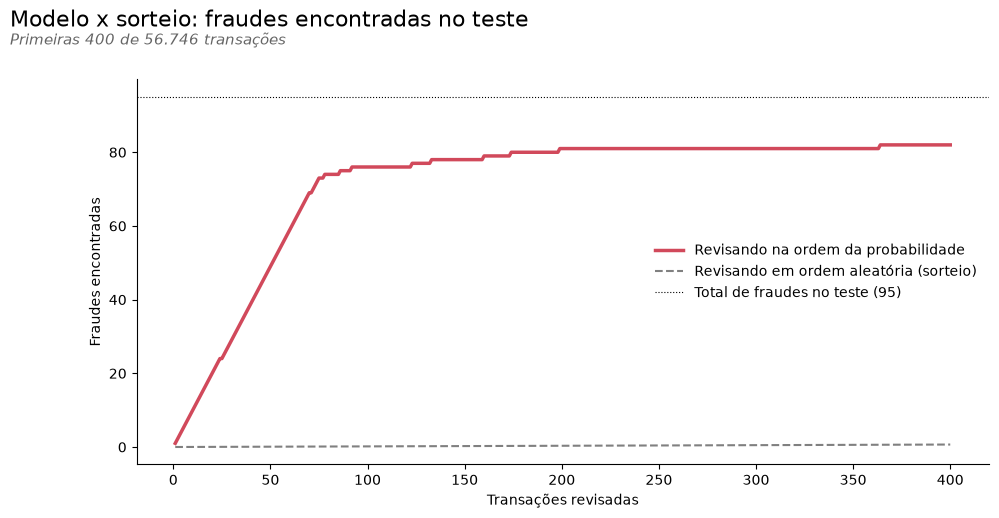

Revisando  50 transações: modelo encontra 49 fraudes | sorteio, 0.08
Revisando 100 transações: modelo encontra 76 fraudes | sorteio, 0.17
Revisando 200 transações: modelo encontra 81 fraudes | sorteio, 0.33


In [64]:
ganho = ganho_vs_sorteio(y_test, prob_teste)
plt.figure(figsize=(11, 5))
limite_grafico = 400
plt.plot(ganho['Lidos'][:limite_grafico], ganho['Modelo'][:limite_grafico], color=COR_FRAUDE, lw=2.5, label='Revisando na ordem da probabilidade')
plt.plot(ganho['Lidos'][:limite_grafico], ganho['Sorteio'][:limite_grafico], color='grey', ls='--', label='Revisando em ordem aleatória (sorteio)')
plt.axhline(y_test.sum(), color='black', lw=0.8, ls=':', label=f'Total de fraudes no teste ({y_test.sum()})')
plt.xlabel('Transações revisadas')
plt.ylabel('Fraudes encontradas')
plt.legend(frameon=False)
sns.despine()
titulo('Modelo x sorteio: fraudes encontradas no teste', f'Primeiras {limite_grafico} de {len(y_test):,} transações'.replace(',', '.'))
salvar('Ganho do modelo x sorteio')
plt.show()

for n in [50, 100, 200]:
    linha = ganho.iloc[n - 1]
    print(f'Revisando {n:>3} transações: modelo encontra {int(linha["Modelo"])} fraudes | sorteio, {linha["Sorteio"]:.2f}')

📌 **Nota**
- 🔎 Revisando as **50** transações de maior probabilidade, o time encontra **49 fraudes**. Num sorteio, encontraria **0,08**.
- 🔎 Com **100** revisões, são **76** fraudes; com **200**, **81**. Depois de cerca de 100 revisões, cada revisão nova traz pouca fraude a mais.
- 💡 O modelo transforma um problema de "achar 95 agulhas em 56 mil transações" numa fila de ~100 casos para revisar.

## 3 - Monitoramento em produção

Um modelo de fraude **envelhece rápido**: os fraudadores mudam de tática assim que um golpe começa a ser barrado. Dois tipos de mudança precisam ser acompanhados:

| Tipo | O que muda | Exemplo aqui | Como detectar |
|---|---|---|---|
| **Data drift** | a distribuição das **entradas** | a componente `lim_crt` muda do dia 1 para o dia 2 | PSI e teste K-S, **sem precisar do gabarito** |
| **Concept drift** | a **relação** entre as entradas e a fraude | um golpe novo com componentes "normais" | métricas do modelo (PR-AUC, recall, precisão da fila), **só depois que o gabarito chega** (contestações dos clientes) |

Simulamos o acompanhamento com os 2 dias da base. O **PSI** (*Population Stability Index*) compara a distribuição atual de uma variável, ou do próprio score, com a referência, faixa a faixa. O **teste K-S** (Kolmogorov-Smirnov) mede a maior distância entre as duas distribuições acumuladas (de 0 a 1). Com mais de 100 mil transações por dia, o p-valor do K-S fica abaixo de 0,05 até para diferenças sem importância prática; por isso, a leitura usa a **distância** e o PSI.

| PSI | Leitura |
|---|---|
| < 0,10 | Estável |
| 0,10 a 0,25 | Atenção |
| > 0,25 | Mudança relevante: investigar ou retreinar |

In [65]:
dia_2 = df.loc[X.index, 'Timestamp'] >= 24 * 3600
score_todas = modelo_final.predict_proba(X)[:, 1]
dia_1_valores = {coluna: X.loc[~dia_2, coluna].values for coluna in VARIAVEIS_MONITORADAS} | {'score do modelo': score_todas[~dia_2.values]}
dia_2_valores = {coluna: X.loc[dia_2, coluna].values for coluna in VARIAVEIS_MONITORADAS} | {'score do modelo': score_todas[dia_2.values]}
painel_psi = relatorio_drift(dia_1_valores, dia_2_valores, list(dia_1_valores)).rename(columns={'PSI': 'PSI (dia 2 x dia 1)'})
painel_psi.round(4)

,PSI (dia 2 x dia 1),K-S (distância),K-S (p-valor),Leitura
crt,0.0823,0.0857,0.0,Estável
cep,0.1951,0.1736,0.0,Atenção
reclamacoes,0.0104,0.0385,0.0,Estável
lim_crt,1.0513,0.3608,0.0,Mudança
hist_saldo,0.0023,0.0221,0.0,Estável
hora_do_dia,0.0131,0.0472,0.0,Estável
score do modelo,0.0347,0.0609,0.0,Estável


📌 **Nota: PSI do dia 2 em relação ao dia 1**
- 🔎 O **score do modelo** está estável (PSI de **0,035**), assim como `crt` (0,082), `reclamacoes` (0,010), o valor (0,002) e a hora do dia (0,013).
- ⚠️ `cep` pede atenção (**0,195**) e `lim_crt` mostra **mudança relevante** (**1,05**). O teste K-S confirma: a distância entre os dois dias é de **0,36** em `lim_crt` e **0,17** em `cep`, contra **0,09** em `crt` e **0,06** no score. A mudança é real, não efeito das faixas. Todos os p-valores dão 0,0: com 140 mil transações por dia, qualquer diferença é "significativa", e por isso a leitura usa a distância.
- 💡 `lim_crt` é a 4ª variável mais importante na permutação. Mesmo com o score estável, em produção esse alerta pediria uma investigação e é uma suspeita para a queda de precisão da validação temporal.
- ✅ **Decisão:** monitorar o PSI do score e das 4 variáveis mais importantes a cada dia; acima de 0,25, investigar e avaliar o retreino.

#### SLA e acompanhamento do desempenho em lotes

O PSI avisa que as **entradas** mudaram, mas não diz se o modelo **piorou**. Para isso é preciso o gabarito, que em fraude chega com atraso (a contestação do cliente leva dias). Definimos um **SLA** (acordo de nível de serviço) a partir do que o teste mostrou:
- **PR-AUC mínima** = limite inferior do intervalo de 95% do bootstrap (Fase 04, item 1.1). Abaixo dele, a queda já não é explicada pelo acaso de ter poucas fraudes;
- **recall mínimo da regra** = limite inferior do intervalo do recall da regra final no mesmo bootstrap;
- a **precisão da fila** é acompanhada para dimensionar a equipe de revisão (sem limite fixo).

Simulamos a produção com o modelo da validação temporal (treinado nas primeiras 36 horas), aplicado às últimas 12 horas em **3 lotes de 4 horas**, como se o gabarito de cada lote chegasse depois. Em cada lote, medimos também o PSI de `lim_crt` em relação às primeiras 36 horas. As contas ficam em `src/monitoramento.py`, as mesmas usadas pela aba **📡 Monitoramento** do app, onde dá para mudar o tamanho do lote e a regra de decisão.

SLA: PR-AUC ≥ 0.736 e recall da regra ≥ 0.747 (limites inferiores do bootstrap do teste)


,Transações,Fraudes,PR-AUC,Recall,Precisão da fila,Revisões,PSI de lim_crt,Situação
36 a 40 h,"32,508",38,0.778,0.763,0.225,129,0.587,✅ dentro do SLA
40 a 44 h,"32,914",54,0.837,0.833,0.360,125,0.581,✅ dentro do SLA
44 a 48 h,"26,776",22,0.734,0.773,0.198,86,0.577,🚨 abaixo do SLA


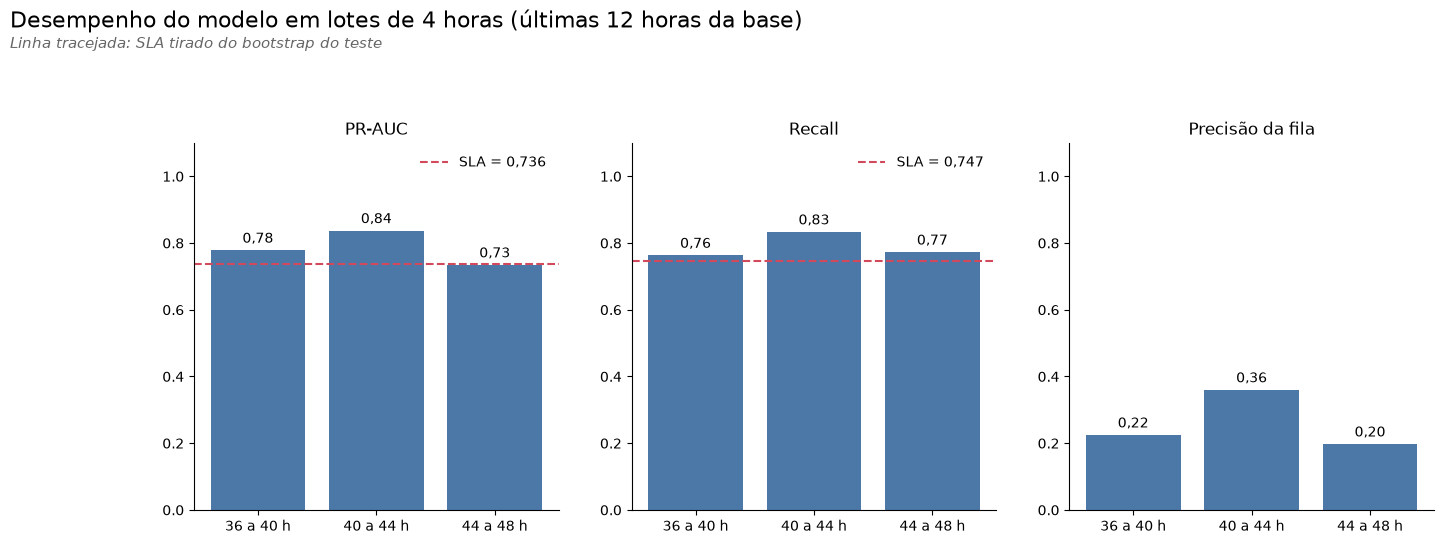

Arquivos do app: 92.198 transações das últimas 12 h e 5.000 de referência


In [66]:
sla_pr_auc = float(np.quantile(pr_auc_boot, 0.025))
sla_recall = float(intervalos.loc[('Recall', 0.025), 'Regra final'])
print(f'SLA: PR-AUC ≥ {sla_pr_auc:.3f} e recall da regra ≥ {sla_recall:.3f} (limites inferiores do bootstrap do teste)')

lotes = pd.cut(horas_desde_inicio[futuro], bins=[36, 40, 44, 48.01], right=False, labels=['36 a 40 h', '40 a 44 h', '44 a 48 h'])
painel_lotes_4h = painel_lotes(y[futuro], prob_futuro, decisao_futuro, lotes, sla_pr_auc, sla_recall)
painel_lotes_4h.insert(len(painel_lotes_4h.columns) - 1, 'PSI de lim_crt',
                       [psi(X.loc[passado, 'lim_crt'], X.loc[futuro, 'lim_crt'][(lotes == lote).values]) for lote in painel_lotes_4h.index])
display(painel_lotes_4h.style.format({'Transações': '{:,.0f}', 'Fraudes': '{:.0f}', 'Revisões': '{:.0f}', 'PR-AUC': '{:.3f}',
                                      'Recall': '{:.3f}', 'Precisão da fila': '{:.3f}', 'PSI de lim_crt': '{:.3f}'}))

fig, axs = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, coluna, limite in zip(axs, ['PR-AUC', 'Recall', 'Precisão da fila'], [sla_pr_auc, sla_recall, None]):
    ax.bar(painel_lotes_4h.index, painel_lotes_4h[coluna].astype(float), color=COR_LEGITIMA)
    ax.bar_label(ax.containers[0], labels=[f'{v:.2f}'.replace('.', ',') for v in painel_lotes_4h[coluna]], padding=3)
    if limite is not None:
        ax.axhline(limite, color=COR_FRAUDE, ls='--', label=f'SLA = {limite:.3f}'.replace('.', ','))
        ax.legend(frameon=False, loc='upper right')
    ax.set(title=coluna, ylim=(0, 1.1))
sns.despine()
titulo('Desempenho do modelo em lotes de 4 horas (últimas 12 horas da base)', 'Linha tracejada: SLA tirado do bootstrap do teste')
fig.subplots_adjust(top=0.85 - 0.4 / fig.get_figheight())
salvar('Monitoramento em lotes')
plt.show()

# Arquivos da aba "Monitoramento" do app: as últimas 12 horas (o app recorta os lotes) e uma amostra de referência
# das primeiras 36 horas, para o PSI e o K-S
(X.loc[futuro, VARIAVEIS_MONITORADAS].round(6)
 .assign(hora=horas_desde_inicio[futuro].round(6).values, real=y[futuro].values, probabilidade=prob_futuro.round(6))
 .to_csv(PASTA_REPORTS / 'lotes_monitoramento.csv.gz', index=False))
X.loc[passado, VARIAVEIS_MONITORADAS].sample(5000, random_state=SEMENTE).round(6).to_csv(
    PASTA_REPORTS / 'referencia_monitoramento.csv', index=False)
print(f'Arquivos do app: {int(futuro.sum()):,} transações das últimas 12 h e 5.000 de referência'.replace(',', '.'))

📌 **Nota**
- 🔎 **SLA:** PR-AUC de pelo menos **0,736** e recall da regra de pelo menos **0,747** (os limites inferiores do bootstrap do teste).
- 🔎 Os dois primeiros lotes ficam **dentro do SLA** (PR-AUC de **0,778** e **0,837**). O último (44 a 48 h) dá PR-AUC de **0,734**, logo abaixo do limite, e gera um **alerta**, embora o recall da regra (**0,773**) esteja dentro.
- ⚠️ O último lote tem só **22 fraudes**: uma fraude a mais ou a menos muda bastante a PR-AUC. Um alerta isolado com tão poucas fraudes pede **investigação**, e não retreino automático.
- 🔎 A **precisão da fila** fica entre **0,20 e 0,36**, contra 0,59 no teste aleatório: de **86 a 129 revisões** a cada 4 horas para **22 a 54 fraudes**. É esse número que dimensiona a equipe.
- 🔎 O PSI de `lim_crt` fica em **0,58** nos três lotes (mudança relevante), mas a PR-AUC não cai junto: **data drift nem sempre derruba o desempenho**. Por isso os dois monitoramentos são necessários.
- ✅ **Decisão:** o SLA de PR-AUC entra na ficha do modelo. Um lote só conta como alerta quando acumular volume de fraudes suficiente (dezenas, não 22); com **2 lotes seguidos** abaixo do SLA, retreinar.

#### Plano de retreino e implantação segura

| Gatilho | Exemplo | Ação |
|---|---|---|
| **Calendário** | todo mês | retreinar com a janela mais recente e comparar com o modelo atual nos mesmos dados |
| **Data drift** | PSI > 0,25 no score ou numa das 4 variáveis mais importantes (como `lim_crt` aqui) | investigar a origem (mudança no sistema, golpe novo) antes de retreinar |
| **Concept drift** | PR-AUC ou recall de um lote abaixo do SLA | retreinar com os dados recentes já rotulados; se repetir, rever as variáveis |
| **Fila de revisão** | precisão da fila bem abaixo da esperada (alarmes demais) | rever o limiar pelo custo, com os dados novos |

**Como trocar o modelo sem risco** (o ciclo de MLOps):
1. **Shadow mode:** o modelo novo roda em paralelo, sem decidir nada; compara-se o que ele teria marcado com o que o atual marcou.
2. **Canary e teste A/B:** o novo decide numa fração pequena das transações (por exemplo, 5%), e a fração cresce se o resultado em reais for melhor.
3. **Rollback:** o `.pkl` e a ficha (`Model/modelo_fraude.json`) versionados permitem voltar ao modelo anterior em minutos.

> 🚫 **Backtest walk-forward completo: não se aplica com 2 dias de dados.** A validação temporal (Fase 04, item 1.2) e os 3 lotes acima são o máximo que a base permite. Com meses de dados, o certo seria treinar em janelas crescentes (*expanding*) ou móveis (*sliding*), testar sempre no período seguinte e descobrir de quanto em quanto tempo retreinar.

# ✅ RESPOSTA À PERGUNTA DE NEGÓCIO

> *Quantas fraudes, e quanto dinheiro, o banco consegue barrar revisando só as transações que o modelo marcar? Qual o custo dessas revisões?*

**Revisando só 132 das 56.746 transações do teste (0,23%), o banco barra 78 das 95 fraudes (82%) e 82,3% do valor fraudado (R$ 12.154,24), gastando R$ 660 em revisões: uma economia líquida de R$ 11.494,24.**

| Pergunta | Resposta | Onde está |
|---|---|---|
| Quantas fraudes o modelo barra? | **78 de 95** (recall de 82,1%) | Fase 04, item 1 |
| Quanto dinheiro? | **R$ 12.154,24** de R$ 14.766,31 (82,3%) | Fase 04, item 1 |
| Qual o custo das revisões? | **132 revisões** (R$ 660); economia líquida de **R$ 11.494,24** | Fase 04, item 1 |
| Com que segurança? | Economia entre **R$ 6.255 e R$ 17.940** (intervalo de 95%) | Fase 04, item 1.1 |
| Quantos alarmes falsos? | **54**, ou 0,1% das legítimas. Em dados futuros, a precisão caiu para 0,27 (cerca de 3 alarmes por fraude) | Fase 04, itens 1 e 1.2 |
| O que escapa? | 17 fraudes (**R$ 2.612,07**); 3 fraudes acima de R$ 500 respondem por 83% desse valor | Fase 04, item 2 |
| É melhor que revisar ao acaso? | Revisando 50 transações: **49 fraudes**, contra 0,08 num sorteio | Fase 05, item 2 |
| Que modelo e que regra? | **XGBoost ajustado** com peso da classe; revisar quem tem probabilidade a partir de **0,11**, ou a partir de **0,005** se a transação passar de **R$ 200**. Tudo escolhido na validação pelo menor custo em reais. Grid, Random e Bayesiana empataram (PR-AUC de 0,837 a 0,842 na validação cruzada) | Fase 03, itens 7 e 8 |
| Como saber se continua funcionando? | PSI diário do score e das variáveis principais + SLA por lote: PR-AUC ≥ **0,736** e recall ≥ **0,747** | Fase 05, item 3 |
| Os 100% da versão original eram reais? | **Não**: eram o modelo avaliado nos dados em que treinou. Na avaliação honesta, F1 de 0,854 no limiar de 0,5 | Fase 03, item 9 |

### As hipóteses, revisitadas

| # | Hipótese | Na EDA (teste) | Na avaliação |
|---|---|---|---|
| H1 | As fraudes têm valor menor | ✅ Efeito pequeno (−0,11) | O valor pesa pouco no modelo (0,008 na permutação), e o recall é menor nas fraudes de até R$ 10 (72%) e nas acima de R$ 500 (75%) |
| H2 | Mais fraude de madrugada | ✅ *Odds ratio* de 3,51 | Recall de 96% na madrugada x 76% no resto do dia |
| H3 | Valor zero é suspeito | ✅ *Odds ratio* de 8,81 | 6 de 7 fraudes de R$ 0 encontradas no teste |
| H4 | Componentes separam fortemente | ✅ 13 de 28 com efeito grande | `crt` e `cep` lideram a permutação e o SHAP |
| H5 | Sem correlação entre componentes | ✅ Máximo de 0,019 | As 30 variáveis foram mantidas; usar só 10 piorou a PR-AUC |
| H6 | Mesma taxa nos dois dias | ⚠️ Diferença desprezível | `Timestamp` removido; a hora do dia contribui pouco (15ª no SHAP). Mas a componente `lim_crt` muda entre os dias (PSI de 1,05) |

# 💡 INSIGHTS

1. **A acurácia engana:** "nunca é fraude" acerta 99,83%. A PR-AUC e o resultado em reais são as medidas certas.
2. **Poucas componentes fazem o trabalho:** 13 das 28 separam bem as fraudes, e `crt` e `cep` lideram a importância por permutação e o SHAP.
3. **Peso da classe vale o mesmo que o SMOTE, sem dados falsos:** sem nenhum balanceamento, o LightGBM falha (PR-AUC de 0,092).
4. **Validação pequena engana; a validação cruzada decide:** com 94 fraudes, a diferença entre o XGBoost padrão e o ajustado era ruído na validação; nas dobras, o ajustado ganhou. E os três métodos de busca empataram (0,837 a 0,842): a Bayesiana com poda chegou lá com um terço menos modelos.
5. **A regra certa é a de menor custo, não o limiar de 0,5:** limiar de 0,11 mais a revisão das transações acima de R$ 200 com probabilidade a partir de 0,5%. No teste, a economia foi R$ 989 maior que só com o limiar, e o bootstrap mostra a regra final à frente do limiar de 0,5 em 88% das amostras.
6. **O que escapa é pouco, mas caro, e invisível:** 3 fraudes acima de R$ 500 respondem por 83% do valor que passou, todas com probabilidade de até 0,1%.
7. **O futuro é mais difícil que o teste aleatório:** em dados posteriores ao treino, a PR-AUC se mantém (0,798), mas a precisão cai para 0,27, e a componente `lim_crt` muda entre os dias. Nos lotes de 4 horas, o último ficou logo abaixo do SLA de PR-AUC. Monitorar é parte da solução.
8. **Os "100%" da versão original eram vazamento:** avaliando onde treinou, qualquer modelo tira 1,000.
9. **Sinais simples ajudam o analista:** transações de madrugada (3,5 vezes mais fraude) e de valor zero (8,8 vezes) merecem atenção, mesmo fora do modelo.

### Os limites, ditos com todas as letras

- **Só 2 dias de dados:** padrões de fraude mudam com o tempo (os fraudadores se adaptam). A validação temporal cobre só 12 horas e já mostrou a precisão caindo para 0,27.
- **Componentes anônimas:** não dá para explicar ao cliente, em termos de negócio, por que uma transação foi barrada (o SHAP aponta componentes, não motivos), nem aplicar o modelo a outra base sem o mesmo PCA. O PCA foi feito com a base inteira, incluindo o nosso teste.
- **Premissas de custo:** o custo de revisão de R$ 5 é uma suposição, e os valores, chamados de "reais", estão originalmente em euros na base pública.
- **A regra de valor foi escolhida entre 28 combinações:** o ganho na validação foi pequeno (R$ 122), e o maior ganho no teste pode ter um pouco de sorte.
- **Só 95 fraudes no teste:** a economia tem intervalo de 95% de R$ 6.255 a R$ 17.940.
- **Hora do dia:** supõe que a contagem do tempo começa à meia-noite (o volume de madrugada sustenta isso).

# 🚀 PRÓXIMOS PASSOS

1. **Mais dias de dados e validação temporal em janelas deslizantes**, para entender a queda de precisão em dados futuros e definir de quanto em quanto tempo retreinar.
2. **Automatizar o monitoramento da Fase 05:** PSI diário do score e das variáveis mais importantes (começando pela investigação de `lim_crt`) e o SLA por lote, com o gabarito das contestações chegando no tempo real.
3. **Variáveis de comportamento do cliente** (histórico, frequência de transações, dispositivo): é o único caminho para as 13 fraudes que o modelo não enxerga. Exige uma base não anonimizada.
4. **Fila priorizada pelo valor esperado** (probabilidade × valor), com um teto de revisões por dia de acordo com a capacidade da equipe, em vez de um corte fixo.
5. **Publicar o app** no Streamlit Community Cloud e expor o modelo numa API (por exemplo, FastAPI), lendo a ficha do modelo.

# 🖥️ Interface com Streamlit

O app permite que a área de fraudes **teste a regra de decisão** sem abrir o notebook:
1. **Escolher o limiar e o custo da revisão** e ver, nas transações do teste, quantas fraudes seriam barradas, quantos alarmes falsos e o resultado em reais.
2. **Ligar ou desligar a regra complementar para valores altos** (item 8.5 da Fase 03).
3. **Analisar uma transação** da amostra: probabilidade de fraude, decisão e **por que** o modelo chegou a ela (valores SHAP).
4. **📡 Monitoramento:** desempenho de cada lote das últimas 12 horas contra o SLA da ficha (com o tamanho do lote ajustável), PSI e K-S das variáveis monitoradas e a opção de **enviar um lote novo** (CSV) para checar o drift e, se houver gabarito, o SLA.

A célula abaixo grava o arquivo `app.py` na raiz do projeto. Para executar (a partir da raiz):

```bash
pip install -r requirements.txt
streamlit run app.py
```

In [67]:
%%writefile ../app.py
import json

import joblib
import numpy as np
import pandas as pd
import streamlit as st

from src.avaliacao import aplicar_regra, resumo_financeiro
from src.config import CUSTO_REVISAO, PASTA_MODELO, PASTA_REPORTS, VARIAVEIS_MONITORADAS
from src.explicacao import contribuicoes_xgboost
from src.monitoramento import painel_lotes, relatorio_drift

st.set_page_config(page_title="Detecção de Fraudes 🕵️", page_icon="🕵️", layout="wide")
st.title("🕵️ Detecção de Fraudes em Transferências")
st.markdown("Teste a **regra de decisão** do modelo: a partir de qual probabilidade uma transação vai para "
            "**revisão manual**, e quanto isso barra de fraudes e custa em revisões.")

CAMINHO_MODELO = PASTA_MODELO / "modelo_fraude.pkl"


### Carregamento
@st.cache_resource
def carregar_modelo():
    return joblib.load(CAMINHO_MODELO)


@st.cache_data
def carregar_dados():
    previsoes = pd.read_csv(PASTA_REPORTS / "previsoes_teste.csv")
    amostra = pd.read_csv(PASTA_REPORTS / "amostra_transacoes.csv", index_col="id")
    return previsoes, amostra


@st.cache_data
def carregar_monitoramento():
    with open(PASTA_MODELO / "modelo_fraude.json", encoding="utf-8") as arquivo:
        sla = json.load(arquivo)["monitoramento"]
    lotes = pd.read_csv(PASTA_REPORTS / "lotes_monitoramento.csv.gz")
    referencia = pd.read_csv(PASTA_REPORTS / "referencia_monitoramento.csv")
    return sla, lotes, referencia


def reais(valor):
    return f"R$ {valor:,.0f}".replace(",", ".")


FORMATO_LOTES = {"Transações": "{:,.0f}", "Fraudes": "{:.0f}", "Revisões": "{:.0f}", "PR-AUC": "{:.3f}",
                 "Recall": "{:.3f}", "Precisão da fila": "{:.3f}"}
# A hora do dia fica fora do drift por lote: um lote de poucas horas cobre só uma parte do dia e sempre "mudaria"
VARIAVEIS_LOTE = [coluna for coluna in VARIAVEIS_MONITORADAS if coluna != "hora_do_dia"]
FORMATO_DRIFT = {"PSI": "{:.3f}", "K-S (distância)": "{:.3f}", "K-S (p-valor)": "{:.3g}"}

if not CAMINHO_MODELO.exists():
    st.error("Modelo não encontrado. Execute o notebook v2 para gerar Model/modelo_fraude.pkl.")
    st.stop()

modelo = carregar_modelo()
previsoes, amostra = carregar_dados()

### Parâmetros
with st.sidebar:
    st.header("⚙️ Regra de decisão")
    limiar = st.slider("Limiar (probabilidade mínima para revisar)", 0.01, 0.99, round(modelo["limiar"], 2), step=0.01)
    custo_revisao = st.number_input("Custo de revisar uma transação (R$)", 0.0, 100.0, float(CUSTO_REVISAO), step=1.0)
    st.caption(f"Limiar recomendado pelo notebook: **{modelo['limiar']:.2f}** (custo mínimo na validação, "
               f"com revisão a R$ {CUSTO_REVISAO:.0f}).")
    regra_valor = modelo.get("regra_valor")
    usar_regra = False
    if regra_valor:
        usar_regra = st.checkbox(f"Regra complementar: revisar também valores ≥ {reais(regra_valor['corte_valor'])} "
                                 f"com probabilidade ≥ {regra_valor['limiar_valor']:.2%}", value=True)
    regra_ativa = regra_valor if usar_regra else None

aba_regra, aba_transacao, aba_monitoramento = st.tabs(["📊 Regra de decisão", "🔍 Analisar uma transação",
                                                       "📡 Monitoramento"])

### Regra de decisão, nas transações do teste
with aba_regra:
    real = previsoes["real"].to_numpy()
    marcado = aplicar_regra(previsoes["probabilidade"], previsoes["valor"], limiar, regra_ativa)
    resultado = resumo_financeiro(real, marcado, previsoes["valor"], custo_revisao)
    encontradas, total = int((marcado & (real == 1)).sum()), int(real.sum())
    alarmes = int((marcado & (real == 0)).sum())

    st.caption(f"Calculado nas {len(previsoes):,} transações do teste, que o modelo não viu no treino.".replace(",", "."))
    col1, col2, col3, col4 = st.columns(4)
    col1.metric("Fraudes barradas", f"{encontradas} de {total}", f"{encontradas / total:.0%} das fraudes", delta_color="off")
    col2.metric("Alarmes falsos", f"{alarmes}", f"{alarmes / max(marcado.sum(), 1):.0%} das revisões", delta_color="off")
    col3.metric("Valor das fraudes barradas", reais(resultado["Valor das fraudes barradas"]),
                f"{resultado['% do valor barrado']:.0%} do valor fraudado", delta_color="off")
    col4.metric("Economia líquida", reais(resultado["Economia líquida"]),
                f"revisões: {reais(resultado['Custo das revisões'])}", delta_color="off")

    st.markdown("#### Precisão e recall para cada limiar")
    grade = np.round(np.arange(0.01, 1.0, 0.01), 2)
    curva = pd.DataFrame({
        "Recall (fraudes encontradas)": [((previsoes["probabilidade"] >= g) & (real == 1)).sum() / total for g in grade],
        "Precisão (revisões que eram fraude)": [
            ((previsoes["probabilidade"] >= g) & (real == 1)).sum() / max((previsoes["probabilidade"] >= g).sum(), 1)
            for g in grade],
    }, index=pd.Index(grade, name="Limiar"))
    st.line_chart(curva)
    st.caption("Limiar baixo: mais fraudes encontradas e mais alarmes falsos. Limiar alto: o contrário.")

### Uma transação da amostra
with aba_transacao:
    st.markdown("Escolha uma transação da amostra do teste (15 fraudes e 35 legítimas). As 28 componentes PCA são "
                "anônimas, por isso não há campos para digitar uma transação nova.")
    escolhida = st.selectbox("Transação", amostra.index, format_func=lambda i: f"#{i} – {reais(amostra.loc[i, 'hist_saldo'])}")
    linha = amostra.loc[[escolhida]]
    probabilidade = float(modelo["pipeline"].predict_proba(linha[modelo["colunas"]])[:, 1][0])
    decisao = "🚨 Revisar" if aplicar_regra([probabilidade], linha["hist_saldo"], limiar, regra_ativa)[0] else "✅ Liberar"

    col1, col2, col3 = st.columns(3)
    col1.metric("Probabilidade de fraude", f"{probabilidade:.2%}")
    col2.metric("Decisão com o limiar escolhido", decisao)
    col3.metric("Na verdade era", "Fraude" if linha["Target"].iloc[0] == 1 else "Legítima")
    st.caption(f"Valor: {reais(linha['hist_saldo'].iloc[0])} · hora do dia: {linha['hora_do_dia'].iloc[0]:.1f} h")

    st.markdown("#### Por que essa probabilidade? (valores SHAP)")
    efeito = contribuicoes_xgboost(modelo["pipeline"], linha[modelo["colunas"]]).iloc[0].drop("base")
    principais = efeito.reindex(efeito.abs().sort_values(ascending=False).index[:8])
    st.bar_chart(principais.rename("Efeito no score (positivo = fraude)"), horizontal=True)
    st.caption("As componentes PCA (crt, cep, reclamacoes etc.) são anônimas: o gráfico mostra quais pesaram, "
               "mas não o que significam no negócio.")

### Monitoramento em produção: desempenho por lote (SLA) e data drift
with aba_monitoramento:
    sla, lotes, referencia = carregar_monitoramento()
    st.markdown("Simulação de produção: o modelo treinado nas **primeiras 36 horas** da base decide as **últimas 12 horas**, "
                "em lotes, como se o gabarito de cada lote chegasse depois (contestações dos clientes). "
                "A regra de decisão é a escolhida ao lado.")
    horas_lote = st.select_slider("Tamanho do lote (horas)", options=[2, 3, 4, 6, 12], value=4)
    inicio = 36 + (lotes["hora"] - 36) // horas_lote * horas_lote
    rotulos = inicio.astype(int).map(lambda h: f"{h} a {h + horas_lote} h")
    revisar = aplicar_regra(lotes["probabilidade"], lotes["hist_saldo"], limiar, regra_ativa)
    painel = painel_lotes(lotes["real"], lotes["probabilidade"], revisar, rotulos,
                          sla["sla_pr_auc_minima"], sla["sla_recall_minimo"])
    abaixo = int((painel["Situação"] == "🚨 abaixo do SLA").sum())

    col1, col2, col3 = st.columns(3)
    col1.metric("SLA de PR-AUC", f"≥ {sla['sla_pr_auc_minima']:.3f}")
    col2.metric("SLA de recall da regra", f"≥ {sla['sla_recall_minimo']:.3f}")
    col3.metric("Lotes abaixo do SLA", f"{abaixo} de {len(painel)}")
    st.dataframe(painel.style.format(FORMATO_LOTES, na_rep="–"))
    st.caption("SLA = limites inferiores do intervalo de 95% do bootstrap do teste. Lotes pequenos têm poucas "
               "fraudes, e uma fraude a mais ou a menos muda bastante a PR-AUC: um alerta isolado pede investigação, "
               "não retreino automático.")

    st.markdown("#### Data drift de um lote (não precisa do gabarito)")
    lote = st.selectbox("Lote", painel.index, index=len(painel) - 1)
    drift = relatorio_drift(referencia, lotes[(rotulos == lote).to_numpy()], VARIAVEIS_LOTE)
    st.dataframe(drift.style.format(FORMATO_DRIFT))
    st.caption(f"Referência: amostra de {len(referencia):,} transações das primeiras 36 horas. ".replace(",", ".") +
               f"PSI até 0,10: estável; até 0,25: atenção; acima de {sla['psi_alerta']:.2f}: mudança (investigar ou "
               "retreinar). Com lotes grandes, o p-valor do K-S fica perto de 0 até para diferenças pequenas: leia a distância. "
               "A hora do dia fica de fora: um lote de poucas horas sempre cobre só uma parte do dia (no notebook, ela é "
               "comparada dia contra dia).")

    st.markdown("#### Avaliar um lote novo")
    arquivo = st.file_uploader("CSV com as 30 colunas do modelo (e a coluna Target, se o gabarito já tiver chegado)",
                               type="csv")
    if arquivo is not None:
        novo = pd.read_csv(arquivo)
        faltando = [coluna for coluna in modelo["colunas"] if coluna not in novo.columns]
        if faltando:
            st.error(f"Faltam {len(faltando)} colunas no arquivo, por exemplo: {', '.join(faltando[:5])}.")
        else:
            prob_novo = modelo["pipeline"].predict_proba(novo[modelo["colunas"]])[:, 1]
            revisar_novo = aplicar_regra(prob_novo, novo["hist_saldo"], limiar, regra_ativa)
            st.metric("Transações enviadas para revisão", f"{int(revisar_novo.sum())} de {len(novo)}")
            st.dataframe(relatorio_drift(referencia, novo, VARIAVEIS_LOTE).style.format(FORMATO_DRIFT))
            if "Target" in novo.columns:
                st.dataframe(painel_lotes(novo["Target"], prob_novo, revisar_novo, ["lote enviado"] * len(novo),
                                          sla["sla_pr_auc_minima"], sla["sla_recall_minimo"])
                             .style.format(FORMATO_LOTES, na_rep="–"))

st.info("ℹ️ Premissas: uma fraude não barrada custa o valor da transação; cada transação revisada custa o valor "
        "definido ao lado. O modelo foi treinado com 2 dias de transações e deve ser acompanhado em produção.")


Overwriting ../app.py
